# Projekt 1 - model ratingowy z interpretowalnością, wyjaśnialnością i kalibracją do 4%

**Zbiór:** `zbior_13.csv` - sprawozdania finansowe 3000 spółek z o.o. i flaga `default`.

**Dwa modele:**
- **interpretowalny** - karta scoringowa: binning monotoniczny → WoE → regresja logistyczna (Lab 1),
- **black-box** - XGBoost strojony w walidacji krzyżowej (Lab 3, krok 3).

**Kolejność kroków** (Lab 3, sześć kroków Projektu 1):

| Sekcja | Krok |
|---|---|
| 1-2 | dane, jakość danych, przeciek, podział |
| 3 | EDA |
| 4-5 | cechy i model interpretowalny |
| 6 | black-box i porównanie |
| 7-9 | wyjaśnienia globalne i lokalne, PDP / ICE / ALE, LIME |
| 10 | wierność i stabilność wyjaśnień |
| 11 | kalibracja statystyczna i dostosowanie do 4% |
| 12 | ratingi, próg decyzyjny, porównanie decyzji |
| 13 | analiza kontrfaktyczna |
| 14 | audyt podgrup, monitoring, podsumowanie |

**Konwencje:** `default = 1` to zdarzenie ryzyka, model zwraca PD = P(default = 1). **train** - uczenie modeli i wszystkich
przekształceń, **valid** - kalibracja, wybór metody kalibracji i progu, **test** - wyłącznie ocena końcowa.
Fragmenty kodu przeniesione z laboratoriów są oznaczone komentarzem `# z Lab N` (regulamin pkt 10.5).

## 0. Środowisko i parametry

In [1]:
import sys, warnings, json, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, shap, lime
from scipy.special import logit, expit
from scipy.stats import spearmanr, binomtest, beta as beta_dist
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             log_loss, brier_score_loss)
from sklearn.model_selection import train_test_split, StratifiedKFold

print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__, "| shap:", shap.__version__,
      "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (7, 4.5)
KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}   # z Lab 3
EPS = 1e-6
RNG_SEED = 42
TARGET_PD = 0.04                    # wymóg Projektu 1: tendencja centralna PD = 4%
MARGIN, LGD = 0.10, 0.45            # ekonomia decyzji (sekcja 12)
TARGET = "default"

C:\Users\barto\venvs\wyjasnialnosc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.13 | numpy: 2.4.6 | pandas: 3.1.1 | scikit-learn: 1.9.1 | xgboost: 3.2.0 | shap: 0.51.0 | matplotlib: 3.11.2


## 1. Dane i jakość danych

### 1.1 Definicja PD i słownik danych

- **Zdarzenie:** flaga `default` - zdarzenie ryzyka w przyjętym horyzoncie (zgodnie z opisem projektu).
- **Moment decyzji:** ocena firmy na podstawie ostatniego sprawozdania finansowego. Wszystkie cechy to pozycje
  bilansu, rachunku zysków i strat, przepływów pieniężnych i wskaźniki z nich liczone oraz dane rejestrowe
  (forma prawna, forma własności, PKD) - są znane w dniu oceny.
- **Dane przekrojowe:** brak daty oceny i identyfikatora firmy, więc podział jest losowy, stratyfikowany (1.4).

In [2]:
df = pd.read_csv("dane/zbior_13.csv")
print(f"n = {len(df):,} | cech: {df.shape[1] - 1} | defaultów: {df[TARGET].sum()} | DR = {df[TARGET].mean():.2%}")

opis = pd.read_csv("dane/opis_zmiennych.csv")          # słownik z Dane_Opis_zmiennych.pdf: zmienna -> obszar
obszar = dict(zip(opis["zmienna"].str.replace("dlugu", "długu"), opis["obszar"]))       # w danych: wsk_koszt_długu_*
print(pd.Series([obszar.get(c, "brak w słowniku") for c in df.columns if c != TARGET]).value_counts().to_string())
print("Zmienne spoza słownika:", [c for c in df.columns if c != TARGET and c not in obszar])
df.head(3)

n = 3,000 | cech: 222 | defaultów: 445 | DR = 14.83%
wskaźnik finansowy         136
pozycja bilansu             54
pozycja RZiS                22
brak w słowniku              5
rachunek przepływów          2
szczególna forma prawna      1
forma własności              1
PKD                          1
Zmienne spoza słownika: ['wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'schemat_wsk_bilans', 'schemat_wsk_rzis']


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,214,3811,-0.024322,0.343511,0.196646,8215,817000.00,134000.00,0.00,...,0.209302,0.212159,3.777778,0.410037,0.0,0.0,0.790698,0.777234,0.054173,1
1,117,215,3821,0.027073,0.354839,0.435294,2105,40604.45,0.00,0.00,...,0.431132,2.706957,1.319474,0.517185,0.0,0.0,0.568868,-0.271864,0.431132,1
2,117,215,7311,0.053428,0.351690,0.417817,1458,1269563.78,323411.06,226537.02,...,0.444981,0.462152,0.559528,0.022711,0.0,0.0,0.555019,0.517866,0.518583,1


### 1.2 Kontrola jakości danych (Data Quality)

Sprawdzamy: wartości nieskończone (dzielenie przez zero we wskaźnikach), braki, kolumny stałe i zduplikowane,
duplikaty obserwacji. Decyzje o usunięciu kolumn zależą tylko od opisu danych albo od zbioru train (1.4).

In [3]:
num_all = df.drop(columns=TARGET).select_dtypes("number")
inf_kol = num_all.columns[np.isinf(num_all).any()].tolist()
print("Kolumny z wartościami ±inf:", {c: int(np.isinf(df[c]).sum()) for c in inf_kol})
df[inf_kol] = df[inf_kol].replace([np.inf, -np.inf], np.nan)        # ±inf traktujemy jak brak (wskaźnik nieokreślony)

braki = df.isna().mean().sort_values(ascending=False)
display(braki[braki > 0].to_frame("udział braków").round(3))
print("Duplikaty wierszy:", df.duplicated().sum(), "| duplikaty bez flagi default:", df.drop(columns=TARGET).duplicated().sum())
print("Kolumny stałe:", [c for c in df.columns if df[c].nunique(dropna=False) <= 1])
print("schemat_wsk_bilans = schemat_wsk_rzis w", f"{(df['schemat_wsk_bilans'] == df['schemat_wsk_rzis']).mean():.1%} obserwacji")

Kolumny z wartościami ±inf: {'wsk_kapital_do_aktywa': 13, 'wsk_plynnosc_biez_1': 920, 'wsk_struktura_kap_wlasnego_s_2': 93}


,udział braków
RP_przeplywy_operacyjne,0.986
wsk_zadluzenia_gotowki_2,0.986
wsk_zysk_CF_operacyjny,0.986
wsk_pokrycie_wyd_fin_gotowkowe_2,0.986
wsk_pokrycie_zob_kr_gotowkowe_2,0.986
wsk_akt_generowania_got_2,0.986
RP_amortyzacja,0.948
wsk_plynnosc_biez_1,0.339
wsk_struktura_kap_wlasnego_s_2,0.044
wsk_kapital_do_aktywa,0.017


Duplikaty wierszy: 0 | duplikaty bez flagi default: 0
Kolumny stałe: ['szczegolnaFormaPrawna_Symbol', 'Naleznosci_dostaw_uslug_pow12m_kapitale']
schemat_wsk_bilans = schemat_wsk_rzis w 97.6% obserwacji


**Powtarzające się podmioty.** Zbiór nie ma identyfikatora firmy. Sprawdzamy, czy ta sama firma nie występuje
kilka razy (np. w kolejnych latach): szukamy par z tym samym PKD, formą własności i kapitałem podstawowym,
których wiek różni się o pełną liczbę lat (±3 dni). Jeśli takich par jest tyle, ile wynika z przypadku, nie ma
podstaw do podziału grupowego.

In [4]:
def pary_rok_pozniej(dane):
    # pary firm z tym samym PKD, formą własności i kapitałem, których wiek różni się o 1-6 pełnych lat (±3 dni)
    pary = []
    for _, g in dane.groupby(["pkdKod", "formaWlasnosci_Symbol", "Kapital_podstawowy"]):
        for a, b in itertools.combinations(g.index, 2):
            d = abs(dane.at[a, "wsk_liczba_dni_istnienia"] - dane.at[b, "wsk_liczba_dni_istnienia"]); k = round(d / 365.25)
            if 1 <= k <= 6 and abs(d - k * 365.25) <= 3:
                pary.append((a, b))
    return pary

PARY = pary_rok_pozniej(df)
rng = np.random.default_rng(RNG_SEED)                       # poziom przypadku: wiek firm losowo przemieszany
losowe = [len(pary_rok_pozniej(df.assign(wsk_liczba_dni_istnienia=rng.permutation(df["wsk_liczba_dni_istnienia"].to_numpy()))))
          for _ in range(5)]
print(f"Pary „ta sama firma rok później”: w danych {len(PARY)} | po losowym przemieszaniu wieku: "
      f"średnio {np.mean(losowe):.0f} (min {min(losowe)}, max {max(losowe)})")
print("Wartości wsk_index_skr_zaw na kod PKD (średnio):", round(df.groupby("pkdKod")["wsk_index_skr_zaw"].nunique().mean(), 2))

Pary „ta sama firma rok później”: w danych 61 | po losowym przemieszaniu wieku: średnio 35 (min 31, max 38)
Wartości wsk_index_skr_zaw na kod PKD (średnio): 2.98


**Wnioski:**
- Par „rok później” jest wyraźnie więcej niż przy losowym wieku (różnica rzędu kilkudziesięciu par). Do tego wskaźniki
  `wsk_index_*` mają ok. 3 różne wartości na kod PKD - wyglądają na wskaźniki **branżowe liczone dla kilku okresów**.
  Dane pochodzą więc najpewniej z kilku lat i część firm może występować kilka razy.
- Pełnych duplikatów nie ma, a identyfikatora brak, więc stosujemy **ostrożny podział grupowy**: firmy z każdej pary
  kandydatów (i łańcuchów takich par) tworzą jedną grupę. Grupa trafia w całości do jednego zbioru (train, valid albo
  test) i do jednego foldu CV. Kosztem jest kilkadziesiąt „fałszywych” grup różnych firm - to nie szkodzi ocenie.

In [5]:
grupa = pd.Series(np.arange(len(df)), index=df.index)        # union-find: wspólna grupa dla każdej pary kandydatów
def korzen(i):
    while grupa[i] != i:
        i = grupa[i]
    return i
for a, b in PARY:
    ra, rb = korzen(a), korzen(b)
    if ra != rb:
        grupa[max(ra, rb)] = min(ra, rb)
df["grupa"] = [korzen(i) for i in df.index]
rozmiar = df["grupa"].value_counts()
print(f"Grup: {len(rozmiar):,} | grup wieloelementowych: {(rozmiar > 1).sum()} (obserwacji w nich: {rozmiar[rozmiar > 1].sum()})")
#
# ### 1.3 Cechy pochodne i kategorie
#
# - `pkdKod` (400 kodów) → **sekcja PKD** (litera A-U) - stały słownik GUS, bez dopasowania do danych,
# - `formaWlasnosci_Symbol` i `schemat_wsk_bilans` (wielkość jednostki: SFJMI - mikro, SFJMA - mała, SFJIN - pozostałe) jako kategorie,
# - usuwamy: `szczegolnaFormaPrawna_Symbol` (stała - same spółki z o.o.), `schemat_wsk_rzis` (powiela `schemat_wsk_bilans`),
#   `pkdKod` (zastąpiony sekcją).

Grup: 2,942 | grup wieloelementowych: 51 (obserwacji w nich: 109)


C:\Users\barto\AppData\Local\Temp\ipykernel_20212\2624570969.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["grupa"] = [korzen(i) for i in df.index]


In [6]:
SEKCJE = [("A", 1, 3), ("B", 5, 9), ("C", 10, 33), ("D", 35, 35), ("E", 36, 39), ("F", 41, 43), ("G", 45, 47),
          ("H", 49, 53), ("I", 55, 56), ("J", 58, 63), ("K", 64, 66), ("L", 68, 68), ("M", 69, 75), ("N", 77, 82),
          ("O", 84, 84), ("P", 85, 85), ("Q", 86, 88), ("R", 90, 93), ("S", 94, 96), ("T", 97, 98), ("U", 99, 99)]

def sekcja_pkd(kod):
    dzial = int(kod) // 100
    return next((s for s, a, b in SEKCJE if a <= dzial <= b), "INNE")

df = df.copy()
df["sekcja_pkd"] = df["pkdKod"].map(sekcja_pkd)
df["forma_wlasnosci"] = "F" + df["formaWlasnosci_Symbol"].astype(str)
df["wielkosc"] = df["schemat_wsk_bilans"].map({"SFJMI": "mikro", "SFJMA": "mała", "SFJIN": "pozostałe"})
df = df.drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis", "schemat_wsk_bilans", "pkdKod", "formaWlasnosci_Symbol"])
display(df.groupby("sekcja_pkd")[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10).round(3))

,n,DR
sekcja_pkd,,
G,555,0.133
M,454,0.152
C,369,0.125
F,322,0.152
L,238,0.126
J,228,0.171
N,147,0.211
H,139,0.122
K,94,0.117


### 1.4 Podział stratyfikowany train / valid / test (60 / 20 / 20) i walidacja krzyżowa

```
              ┌──────────── train 60% ────────────┐┌─ valid 20% ─┐┌─ test 20% ─┐
dane (3000) → │ uczenie modeli, binning/WoE,       ││ kalibracja,  ││ wyłącznie  │
              │ selekcja cech, tuning:             ││ wybór metody,││ ocena      │
              │ StratifiedKFold(5) wewnątrz train  ││ δ do 4%, próg││ końcowa    │
              └────────────────────────────────────┘└──────────────┘└────────────┘
```

- podział losowy, **stratyfikowany po `default` i grupowy** (`StratifiedGroupKFold`): dzielimy dane na 5 równych części
  z zachowaniem DR i grup z 1.2; 3 części → train, 1 → valid, 1 → test,
- **5-krotna stratyfikowana grupowa CV na train**: wybór liczby cech karty, strojenie black-boxa, stabilność metryk i wyjaśnień,
- każda transformacja wymagająca dopasowania (mediany, binning, WoE, selekcja cech, kodowanie kategorii) jest
  liczona tylko na train (albo na foldach treningowych w CV),
- kalibracja i próg - tylko na valid, test - tylko do raportu. Podział zapisujemy do `wyniki/podzial.csv`.

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

czesci = [b for _, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED).split(df, df[TARGET], groups=df["grupa"])]
zbior = pd.Series("train", index=df.index); zbior.iloc[czesci[3]] = "valid"; zbior.iloc[czesci[4]] = "test"
zbior.rename("zbior").to_frame().assign(grupa=df["grupa"]).to_csv("wyniki/podzial.csv", index_label="wiersz")   # zapis podziału
df_train, df_valid, df_test = (df[zbior == s].copy() for s in ["train", "valid", "test"])
for nazwa, part in [("train", df_train), ("valid", df_valid), ("test", df_test)]:
    print(f"{nazwa:5s} n = {len(part):5,d}   defaulty = {part[TARGET].sum():4d}   DR = {part[TARGET].mean():.2%}")
wspolne = [len(set(a["grupa"]) & set(b["grupa"])) for a, b in [(df_train, df_valid), (df_train, df_test), (df_valid, df_test)]]
print("Wspólne grupy train-valid, train-test, valid-test:", wspolne)
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
FOLDY = list(CV.split(df_train, df_train[TARGET], groups=df_train["grupa"]))          # te same foldy w całym notebooku

train n = 1,801   defaulty =  267   DR = 14.83%
valid n =   600   defaulty =   89   DR = 14.83%
test  n =   599   defaulty =   89   DR = 14.86%
Wspólne grupy train-valid, train-test, valid-test: [0, 0, 0]


### 1.5 Usunięcie cech na podstawie train

Na train: usuwamy cechy z > 50% braków (przepływy pieniężne - prawie zawsze puste), prawie stałe (> 99% jednej
wartości) i zduplikowane (identyczne kolumny - zostawiamy pierwszą).

In [8]:
cat_cols = ["sekcja_pkd", "forma_wlasnosci", "wielkosc"]
kandydaci = [c for c in df.columns if c not in [TARGET, "grupa"] + cat_cols]
usun_braki = [c for c in kandydaci if df_train[c].isna().mean() > 0.5]
usun_stale = [c for c in kandydaci if df_train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99]
pozostale = [c for c in kandydaci if c not in usun_braki + usun_stale]
usun_duplikaty = df_train[pozostale].T.duplicated().pipe(lambda s: s[s].index.tolist())
print("Braki > 50%:", usun_braki)
print("Prawie stałe:", usun_stale)
print("Duplikaty innych kolumn:", usun_duplikaty)
num_cols = [c for c in pozostale if c not in usun_duplikaty]
print(f"Cechy liczbowe: {len(num_cols)} | kategoryczne: {cat_cols}")

Braki > 50%: ['RP_przeplywy_operacyjne', 'RP_amortyzacja', 'wsk_akt_generowania_got_2', 'wsk_pokrycie_wyd_fin_gotowkowe_2', 'wsk_pokrycie_zob_kr_gotowkowe_2', 'wsk_zadluzenia_gotowki_2', 'wsk_zysk_CF_operacyjny']
Prawie stałe: ['Wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m_powiazane', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Pozostale_rezerwy', 'Zobowiazania_dostaw_uslug_pow12m_powiazane', 'Zobowiazania_dostaw_uslug_12m_kapitale', 'Zobowiazania_dostaw_uslug_pow12m_kapitale', 'Ujemna_wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m', 'Zobowiazania_dostaw_uslug_pow12m']
Duplikaty innych kolumn: ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']
Cechy liczbowe: 192 | kategoryczne: ['sekcja_pkd', 'forma_wlasnosci', 'wielkosc']


### 1.6 Kontrola przecieku (anty-leak)

Test z Lab 3: **AUC każdej cechy osobno** na train. Cecha silniejsza niż cały sensowny model (AUC > 0,85) to sygnał,
że może zawierać informację z przyszłości.

In [9]:
rows = []                                                     # z Lab 3 (1.4)
for c in num_cols:
    m = df_train[c].notna()
    auc = roc_auc_score(df_train.loc[m, TARGET], df_train.loc[m, c])
    rows.append({"cecha": c, "obszar": obszar.get(c, "-"), "AUC jednowymiarowe": max(auc, 1 - auc),
                 "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - m.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha").sort_values("AUC jednowymiarowe", ascending=False)
display(tab_auc.head(15).round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Podejrzanie silne cechy (AUC > 0,85):", podejrzane)

,obszar,AUC jednowymiarowe,kierunek,braki
cecha,,,,
wsk_index_nowe,-,0.718,+,0.0
wsk_index_skr_zaw,-,0.708,+,0.0
Kapital_wlasny,pozycja bilansu,0.658,-,0.0
podatek_dochodowy,pozycja RZiS,0.649,-,0.0
zysk_netto,pozycja RZiS,0.634,-,0.0
zysk_brutto,pozycja RZiS,0.633,-,0.0
wsk_ebitda_1,wskaźnik finansowy,0.631,-,0.0
wsk_ebitda_2,wskaźnik finansowy,0.628,-,0.0
wsk_ROA,wskaźnik finansowy,0.627,-,0.0


Podejrzanie silne cechy (AUC > 0,85): []


Żadna cecha nie przekracza progu 0,85, ale **AUC to tylko sygnał - decyzję podejmujemy na podstawie słownika danych**
(Lab 3). Trzy cechy wymagają uwagi:

| Cecha | Co wiemy | Ryzyko |
|---|---|---|
| `wsk_index_skr_zaw`, `wsk_index_nowe`, `wsk_index_aktywne` | **jedyne cechy merytoryczne spoza słownika danych** (poza technicznym typem sprawozdania `schemat_wsk_*`); ok. 3 wartości na kod PKD - wskaźniki **branżowe dla okresu** (dynamika firm skreślonych / zawieszonych, nowych, aktywnych) | nie wiadomo, za jaki okres są liczone; jeśli obejmują okres po dacie oceny, zawierają **informację z przyszłości** (skreślenie lub zawieszenie firmy to zdarzenie bliskie defaultowi, a firma może sama wchodzić do wskaźnika). `wsk_index_skr_zaw` ma najwyższe AUC jednowymiarowe ze wszystkich cech i IV „podejrzanie silne” (4.1) |

Wszystkie pozostałe cechy pochodzą ze sprawozdania finansowego albo rejestru, więc są znane w dniu oceny.
**Decyzja:** wykluczamy trzy cechy `wsk_index_*` z obu modeli (zasada ostrożności - cecha o nieznanym momencie
pomiaru nie może trafić do modelu ratingowego). Poniżej sprawdzamy, ile „dałyby” - jak w Zadaniu 1 z Lab 3.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

WYKLUCZONE = ["wsk_index_skr_zaw", "wsk_index_nowe", "wsk_index_aktywne"]

def gini_prostego_logitu(cechy):                              # z Lab 3 (Zadanie 1); logit na rangach cech (odporny na skrajne wartości)
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
    rangi = lambda d: d[cechy].rank(pct=True)
    m.fit(rangi(df_train), df_train[TARGET])
    return {f"Gini {s}": 2 * roc_auc_score(cz[TARGET], m.predict_proba(rangi(cz))[:, 1]) - 1 for s, cz in [("valid", df_valid), ("test", df_test)]}

from sklearn.linear_model import LogisticRegression
bez = [c for c in num_cols if c not in WYKLUCZONE]
display(pd.DataFrame({"bez wsk_index_*": gini_prostego_logitu(bez), "z wsk_index_*": gini_prostego_logitu(num_cols)}).T.round(3))
num_cols = bez
tab_auc = tab_auc.drop(index=WYKLUCZONE)

,Gini valid,Gini test
bez wsk_index_*,0.397,0.373
z wsk_index_*,0.586,0.534


Trzy wskaźniki podnoszą Gini prostego logitu o kilkanaście punktów - więcej niż cała reszta polityki cech. Tak duży
zysk z cech branżowo-okresowych o nieznanym horyzoncie to typowy objaw przecieku albo efektu okresu (w „złym” roku
rośnie zarówno odsetek skreśleń w branży, jak i DR). W obu przypadkach model z nimi gorzej uogólniałby się na
przyszłe okresy. **W raporcie opisujemy tę decyzję i jej koszt; jeśli autor danych potwierdzi, że wskaźniki są
liczone za okres przed oceną, można je przywrócić.**

## 2. Zmienne objaśniające - zestaw do modelowania

In [11]:
FEATURES = num_cols + cat_cols
X_tr, y_tr = df_train[FEATURES], df_train[TARGET].to_numpy()
X_va, y_va = df_valid[FEATURES], df_valid[TARGET].to_numpy()
X_te, y_te = df_test[FEATURES], df_test[TARGET].to_numpy()
Y = {"train": y_tr, "valid": y_va, "test": y_te}
X = {"train": X_tr, "valid": X_va, "test": X_te}
json.dump({"num_cols": num_cols, "cat_cols": cat_cols, "usuniete": usun_braki + usun_stale + usun_duplikaty},
          open("wyniki/cechy_v1.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)       # wersjonowanie cech
print(f"Zestaw cech v1: {len(FEATURES)} cech")

Zestaw cech v1: 192 cech


## 3. EDA: rozkłady, obserwacje odstające, korelacje, zależność z targetem (train)

### 3.1 Rozkłady i obserwacje odstające

Wskaźniki finansowe mają bardzo ciężkie ogony (dzielenie przez małe mianowniki). Mierzymy skośność i udział
obserwacji poza przedziałem [Q1 - 3·IQR, Q3 + 3·IQR].

In [12]:
opisowe = df_train[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
opisowe["skośność"] = df_train[num_cols].skew()
q1, q3 = df_train[num_cols].quantile(0.25), df_train[num_cols].quantile(0.75)
opisowe["odstające (3·IQR)"] = ((df_train[num_cols] < q1 - 3 * (q3 - q1)) | (df_train[num_cols] > q3 + 3 * (q3 - q1))).mean()
print(f"Cechy ze skośnością |s| > 2: {(opisowe['skośność'].abs() > 2).sum()} z {len(num_cols)} | "
      f"mediana udziału obserwacji odstających: {opisowe['odstające (3·IQR)'].median():.1%}")
display(opisowe.loc[tab_auc.index[:8], ["mean", "1%", "50%", "99%", "skośność", "odstające (3·IQR)"]].round(3))

Cechy ze skośnością |s| > 2: 182 z 189 | mediana udziału obserwacji odstających: 12.8%


,mean,1%,50%,99%,skośność,odstające (3·IQR)
Kapital_wlasny,2320978.174,0.000,233841.17,3.123868e+07,27.012,0.092
podatek_dochodowy,30889.528,-879.000,112.00,5.786742e+05,-7.057,0.135
zysk_netto,107548.107,-1448857.830,0.00,2.557294e+06,-5.380,0.166
zysk_brutto,142650.762,-1583591.760,0.00,3.097777e+06,-1.872,0.165
wsk_ebitda_1,346036.460,-621856.560,10528.02,5.511441e+06,11.016,0.133
wsk_ebitda_2,383950.352,-621856.560,11709.12,6.159873e+06,10.191,0.133
wsk_ROA,2.572,-0.831,0.00,6.480000e-01,41.373,0.123
wsk_rent_kaptial_podstawowy,11.585,-20.381,0.00,1.659280e+02,21.016,0.184


**Polityka obserwacji odstających:** nie usuwamy firm - skrajne wskaźniki to często prawdziwe sygnały ryzyka
(np. ujemny kapitał własny). Model interpretowalny używa **binningu kwantylowego i WoE**, który jest odporny na
wartości skrajne (skrajne wartości trafiają do skrajnego przedziału). Drzewa w XGBoost są niezmiennicze na
monotoniczne przekształcenia i nie wymagają cappingu. Siatki PDP / ICE ograniczamy do kwantyli 2-98% z train.

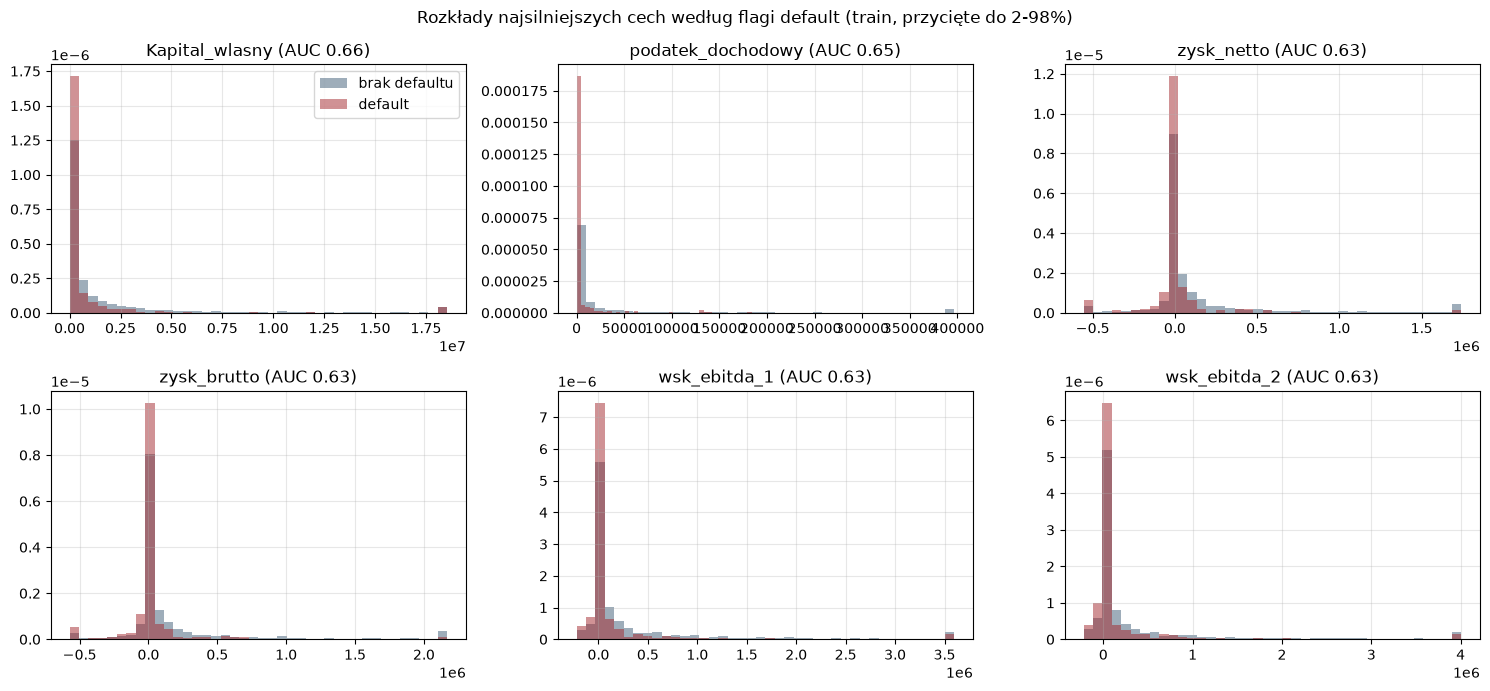

In [13]:
TOP_EDA = tab_auc.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, TOP_EDA):
    lo, hi = df_train[c].quantile([0.02, 0.98])
    for k, kol, lab in [(0, KOL["train"], "brak defaultu"), (1, KOL["test"], "default")]:
        ax.hist(df_train.loc[df_train[TARGET] == k, c].clip(lo, hi), bins=40, density=True, alpha=0.5, color=kol, label=lab)
    ax.set_title(f"{c} (AUC {tab_auc.loc[c, 'AUC jednowymiarowe']:.2f})"); ax.grid(alpha=0.3)
axes[0, 0].legend(); plt.suptitle("Rozkłady najsilniejszych cech według flagi default (train, przycięte do 2-98%)")
plt.tight_layout(); plt.savefig("wykresy/eda_rozklady.png", dpi=120); plt.show()

### 3.2 Zmienne kategoryczne a DR

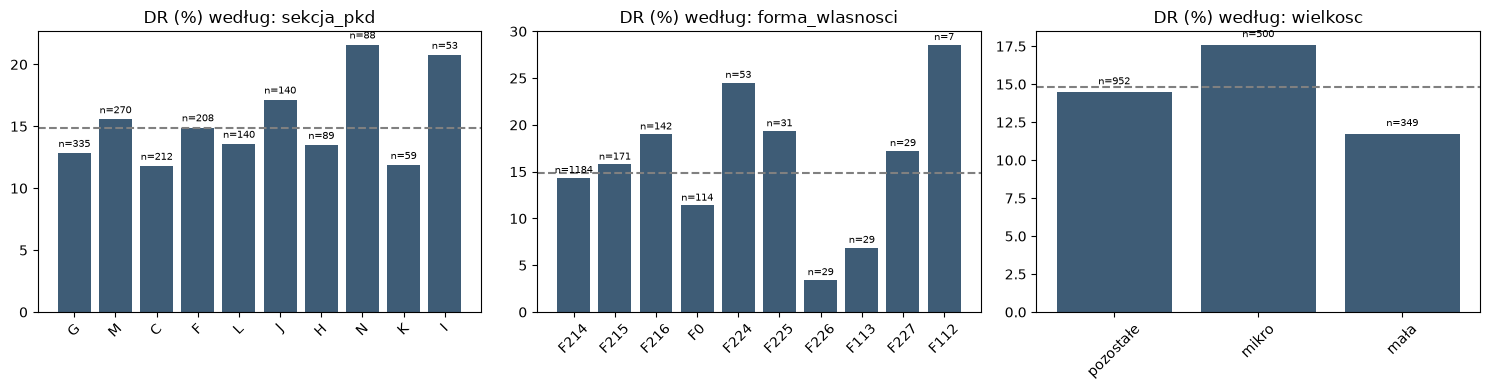

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cat_cols):
    t = df_train.groupby(c)[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10)
    ax.bar(t.index.astype(str), 100 * t["DR"], color=KOL["logit"])
    for i, (n_, dr) in enumerate(zip(t["n"], t["DR"])):
        ax.text(i, 100 * dr + 0.5, f"n={n_}", ha="center", fontsize=7)
    ax.axhline(100 * y_tr.mean(), ls="--", color="gray"); ax.set_title(f"DR (%) według: {c}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("wykresy/eda_kategorie.png", dpi=120); plt.show()

### 3.3 Korelacje

Wiele wskaźników to warianty tej samej miary (np. kilka definicji EBITDA czy zadłużenia), więc korelacje są
bardzo wysokie. To ważne dla: (a) selekcji cech do modelu interpretowalnego, (b) interpretacji SHAP i PDP
(rozdzielanie wpływu między skorelowane cechy), (c) analizy kontrfaktycznej.

Par cech z |ρ Spearmana| > 0,9: 219 | > 0,7: 937 (z 35,721)


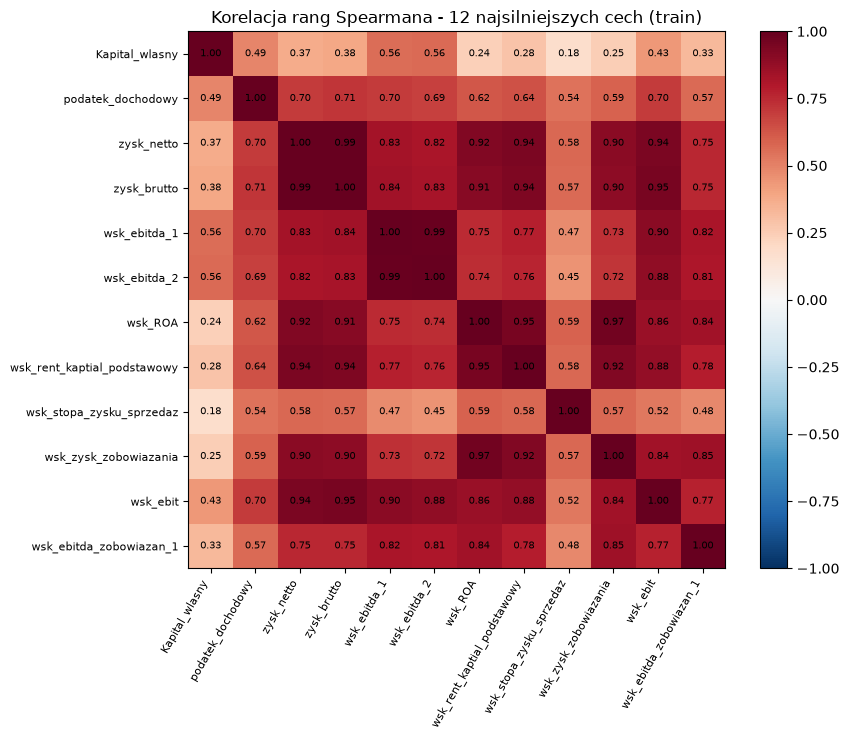

In [15]:
kor = df_train[num_cols].corr(method="spearman").abs()
gorne = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1)).stack()
print(f"Par cech z |ρ Spearmana| > 0,9: {(gorne > 0.9).sum()} | > 0,7: {(gorne > 0.7).sum()} (z {len(gorne):,})")
TOP_KOR = tab_auc.index[:12].tolist()
k12 = df_train[TOP_KOR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(k12.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
for (a, b), val in np.ndenumerate(k12.to_numpy()):
    ax.text(b, a, f"{val:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(TOP_KOR))); ax.set_xticklabels(TOP_KOR, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(TOP_KOR))); ax.set_yticklabels(TOP_KOR, fontsize=8)
ax.set_title("Korelacja rang Spearmana - 12 najsilniejszych cech (train)"); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig("wykresy/eda_korelacje.png", dpi=120); plt.show()

## 4. Przygotowanie cech: binning monotoniczny i WoE (tylko train)

Klasa `WoEBinner` z Lab 1: przedziały kwantylowe łączone do monotonicznego WoE, każdy przedział ≥ 5% obserwacji,
najwyżej 5 przedziałów; rzadkie kategorie → `INNE`. Konwencja: **WoE = ln(%dobrych / %złych)**, WoE > 0 - niższe ryzyko.
Rozszerzenie względem Lab 1: braki danych tworzą **osobny przedział `BRAK`** (brak wskaźnika, np. przez zerowy mianownik,
to też informacja).

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class WoEBinner(BaseEstimator, TransformerMixin):
    # z Lab 1 (sekcja 7) - binning + WoE; dodany osobny przedział dla braków danych
    # Konwencja: WoE = ln(%dobrych / %złych), y = 1 oznacza złego klienta.
    def __init__(self, max_bins=5, init_bins=10, min_share=0.05, smoothing=0.5):
        self.max_bins, self.init_bins, self.min_share, self.smoothing = max_bins, init_bins, min_share, smoothing

    def _stats(self, codes, y, k):
        n = np.bincount(codes, minlength=k).astype(float)
        bad = np.bincount(codes, weights=y, minlength=k)
        return n, bad

    def _num_cuts(self, x, y):
        cuts = list(np.unique(np.quantile(x, np.linspace(0, 1, self.init_bins + 1)[1:-1])))
        rho = pd.Series(x).corr(pd.Series(y), method="spearman")
        direction = 1.0 if (not np.isfinite(rho) or rho == 0) else float(np.sign(rho))
        N = len(x)
        while cuts:
            codes = np.searchsorted(cuts, x, side="right"); k = len(cuts) + 1
            n, bad = self._stats(codes, y, k)
            br = bad / np.maximum(n, 1)
            small = np.where(n / N < self.min_share)[0]
            if len(small):
                i = small[0]
                j = i - 1 if i == k - 1 else (i if i == 0 else (i - 1 if abs(br[i] - br[i - 1]) < abs(br[i] - br[i + 1]) else i))
                cuts.pop(j); continue
            viol = np.where(np.diff(br) * direction < 0)[0]
            if len(viol):
                cuts.pop(viol[0]); continue
            if k > self.max_bins:
                cuts.pop(int(np.argmin(np.abs(np.diff(br))))); continue
            break
        return cuts

    def _table(self, codes, y, labels):
        k = len(labels); n, bad = self._stats(codes, y, k); good = n - bad; s = self.smoothing
        pg = (good + s) / (good.sum() + s * k); pb = (bad + s) / (bad.sum() + s * k)
        woe = np.log(pg / pb)
        return pd.DataFrame({"przedział": labels, "N": n.astype(int), "udział": n / n.sum(), "złe": bad.astype(int),
                             "stopa złych": bad / np.maximum(n, 1), "% dobrych": pg, "% złych": pb,
                             "WoE": woe, "IV": (pg - pb) * woe})

    def fit(self, X, y):
        X = pd.DataFrame(X); y = np.asarray(y).astype(float)
        self.cuts_, self.groups_, self.tables_, self.woe_, self.iv_, self.nan_ = {}, {}, {}, {}, {}, {}
        for c in X.columns:
            if pd.api.types.is_numeric_dtype(X[c]):
                x = X[c].to_numpy(dtype=float); ok = ~np.isnan(x)
                cuts = self._num_cuts(x[ok], y[ok]); self.cuts_[c] = cuts
                edges = [-np.inf] + cuts + [np.inf]
                labels = [f"[{edges[i]:.4g}; {edges[i+1]:.4g})" for i in range(len(edges) - 1)]
                self.nan_[c] = bool((~ok).any())                    # osobny przedział BRAK, gdy w train są braki
                if self.nan_[c]:
                    labels = labels + ["BRAK"]
                codes = np.where(ok, np.searchsorted(cuts, np.nan_to_num(x), side="right"), len(cuts) + 1)
            else:
                share = X[c].value_counts(normalize=True)
                groups = {v: (v if share[v] >= self.min_share else "INNE") for v in share.index}
                labels = sorted(set(groups.values()), key=lambda g: (g == "INNE", g))
                self.groups_[c] = (groups, labels)
                codes = X[c].map(groups).map({g: i for i, g in enumerate(labels)}).to_numpy()
            tab = self._table(codes, y, labels)
            self.tables_[c] = tab; self.woe_[c] = tab["WoE"].to_numpy(); self.iv_[c] = float(tab["IV"].sum())
        self.feature_names_in_ = np.array(X.columns)
        return self

    def codes(self, X):
        X = pd.DataFrame(X); out = {}
        for c in self.feature_names_in_:
            if c in self.cuts_:
                x = X[c].to_numpy(dtype=float); k = len(self.cuts_[c])
                kod = np.searchsorted(self.cuts_[c], np.nan_to_num(x), side="right")
                out[c] = np.where(np.isnan(x), k + 1 if self.nan_[c] else -1, kod)    # brak bez przedziału BRAK -> WoE 0
            else:
                groups, labels = self.groups_[c]; idx = {g: i for i, g in enumerate(labels)}
                out[c] = X[c].map(lambda v: idx[groups[v]] if v in groups else (idx["INNE"] if "INNE" in idx else -1)).to_numpy()
        return pd.DataFrame(out, index=X.index)

    def transform(self, X):
        cd = self.codes(X)
        return pd.DataFrame({c: np.where(cd[c] >= 0, self.woe_[c][np.clip(cd[c], 0, None)], 0.0)
                             for c in self.feature_names_in_}, index=cd.index)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

### 4.1 Information Value - ranking cech (train)

In [17]:
def sila_iv(v):                                              # z Lab 1
    return ("bezużyteczna" if v < 0.02 else "słaba" if v < 0.1 else "średnia" if v < 0.3
            else "silna" if v < 0.5 else "podejrzanie silna – sprawdź przeciek")

binner_all = WoEBinner(max_bins=5, min_share=0.05).fit(X_tr, y_tr)
iv_tab = pd.DataFrame({"cecha": list(binner_all.iv_), "IV": list(binner_all.iv_.values())}).sort_values("IV", ascending=False)
iv_tab["siła"] = iv_tab["IV"].map(sila_iv)
iv_tab["obszar"] = iv_tab["cecha"].map(lambda c: obszar.get(c, "kategoria"))
print(iv_tab["siła"].value_counts().to_string())
display(iv_tab.head(20).set_index("cecha").round(3))

siła
średnia         80
słaba           73
bezużyteczna    36
silna            3


,IV,siła,obszar
cecha,,,
podatek_dochodowy,0.366,silna,pozycja RZiS
Kapital_wlasny,0.322,silna,pozycja bilansu
zysk_netto,0.304,silna,pozycja RZiS
zysk_brutto,0.293,średnia,pozycja RZiS
wsk_ogolnego_zadluzenia_1,0.291,średnia,wskaźnik finansowy
wsk_ogolnego_zadluzenia_2,0.284,średnia,wskaźnik finansowy
wsk_kapital_do_aktywa,0.283,średnia,wskaźnik finansowy
wsk_rent_kaptial_podstawowy,0.277,średnia,wskaźnik finansowy
wsk_mnoznik_kap_wl,0.274,średnia,wskaźnik finansowy


### 4.2 Selekcja cech do karty scoringowej

Baseline nie może być „za bogaty” (Lab 3). Procedura na train:
1. kandydaci: IV ≥ 0,1 (co najmniej średnia siła),
2. zachłannie według IV: cechę dodajemy, jeśli |ρ Spearmana| jej WoE z każdą już wybraną < 0,6 (unikamy wariantów tej samej miary),
3. liczbę cech k wybieramy 5-krotną CV na train (AUC): bierzemy k z najwyższym średnim AUC. Reguła „1 błędu standardowego”
   dałaby 2-3 cechy, ale przy dużym rozrzucie między foldami (odch. std. ok. 0,05) jest zbyt agresywna, a karta z 2-3 cechami
   pomija całe obszary oceny (płynność, rentowność sprzedaży),
4. kontrola znaków β i VIF (4.3).

In [18]:
W_tr_all = binner_all.transform(X_tr)
kand = iv_tab.loc[iv_tab["IV"] >= 0.1, "cecha"].tolist()
wybrane_kol = []
for c in kand:
    if all(abs(spearmanr(W_tr_all[c], W_tr_all[w])[0]) < 0.6 for w in wybrane_kol):
        wybrane_kol.append(c)
print(f"Kandydaci IV ≥ 0,1: {len(kand)} | po filtrze korelacji: {len(wybrane_kol)}")
print(wybrane_kol)

Kandydaci IV ≥ 0,1: 83 | po filtrze korelacji: 11
['podatek_dochodowy', 'Kapital_wlasny', 'wsk_ogolnego_zadluzenia_1', 'wsk_zysk_zobowiazania', 'wsk_stopa_zysku_sprzedaz', 'wsk_sytuacji_fin', 'pozostale_przychody_oper', 'wsk_rotacja_wartosci_niewaterialnych', 'wsk_ebitda_zobowiazan_odsetki_3', 'wsk_plynnosc_biez_1', 'wsk_struktury_finansowania']


k,2,3,4,5,6,7,8,9,10,11
AUC CV,0.6708,0.7052,0.7048,0.7072,0.7066,0.7124,0.7092,0.7054,0.7040,0.7034
odch. std.,0.0424,0.0420,0.0483,0.0450,0.0466,0.0491,0.0508,0.0533,0.0524,0.0529
błąd std.,0.0190,0.0188,0.0216,0.0201,0.0208,0.0219,0.0227,0.0238,0.0234,0.0236


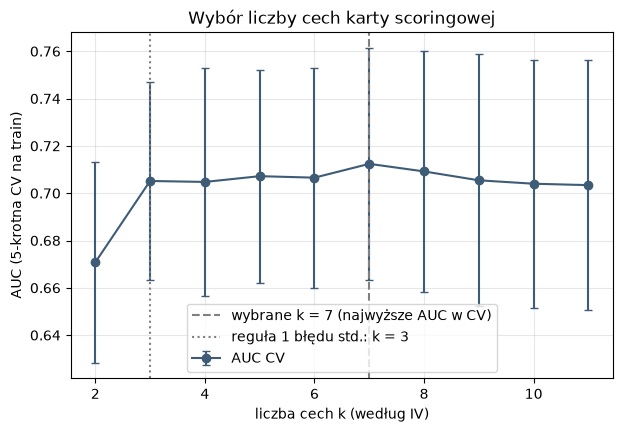

Najlepsze AUC dla k = 7; reguła 1 błędu std. dałaby k = 3; wybieramy k = 7


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def lr_bez_kary(**kw):                                       # z Lab 1
    wersja = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
    return LogisticRegression(C=np.inf, **kw) if wersja >= (1, 8) else LogisticRegression(penalty=None, **kw)

def karta(cechy):
    return Pipeline([("woe", WoEBinner(max_bins=5, min_share=0.05)), ("lr", lr_bez_kary(max_iter=5000))])

wiersze = []
for k in range(2, len(wybrane_kol) + 1):
    auc_f = []
    for a, b in FOLDY:                                         # binning dopasowany w każdym foldzie od nowa
        m = karta(wybrane_kol[:k]).fit(X_tr.iloc[a][wybrane_kol[:k]], y_tr[a])
        auc_f.append(roc_auc_score(y_tr[b], m.predict_proba(X_tr.iloc[b][wybrane_kol[:k]])[:, 1]))
    wiersze.append({"k": k, "AUC CV": np.mean(auc_f), "odch. std.": np.std(auc_f), "błąd std.": np.std(auc_f) / np.sqrt(5)})
wybor_k = pd.DataFrame(wiersze).set_index("k")
najl = wybor_k["AUC CV"].idxmax()
K_1SE = int(wybor_k.index[wybor_k["AUC CV"] >= wybor_k.loc[najl, "AUC CV"] - wybor_k.loc[najl, "błąd std."]].min())
K_CECH = int(najl)
display(wybor_k.round(4).T)
ax = wybor_k["AUC CV"].plot(marker="o", yerr=wybor_k["odch. std."], capsize=3, color=KOL["logit"])
ax.axvline(K_CECH, ls="--", color="gray", label=f"wybrane k = {K_CECH} (najwyższe AUC w CV)")
ax.axvline(K_1SE, ls=":", color="gray", label=f"reguła 1 błędu std.: k = {K_1SE}")
ax.set_xlabel("liczba cech k (według IV)"); ax.set_ylabel("AUC (5-krotna CV na train)"); ax.legend(); ax.grid(alpha=0.3)
plt.title("Wybór liczby cech karty scoringowej"); plt.show()
print(f"Najlepsze AUC dla k = {najl}; reguła 1 błędu std. dałaby k = {K_1SE}; wybieramy k = {K_CECH}")

## 5. Model interpretowalny: karta scoringowa (WoE + regresja logistyczna)

### 5.1 Estymacja i kontrola znaków

W konwencji WoE = ln(%dobrych/%złych) wyższe WoE oznacza niższe ryzyko, więc **oczekujemy β < 0** dla każdej cechy
(typowo β ≈ -1). Dodatni współczynnik to sygnał współliniowości albo niestabilnego binningu (Lab 1, 7.3) - taką cechę usuwamy.

In [20]:
CECHY_L = wybrane_kol[:K_CECH]
while True:
    baseline = karta(CECHY_L).fit(X_tr[CECHY_L], y_tr)
    beta_l = pd.Series(baseline.named_steps["lr"].coef_.ravel(), index=CECHY_L)
    if (beta_l < 0).all():
        break
    print(f"Usuwam {beta_l.idxmax()} (β = {beta_l.max():+.3f} ≥ 0)")
    CECHY_L = [c for c in CECHY_L if c != beta_l.idxmax()]

woe_l = baseline.named_steps["woe"]; lr_l = baseline.named_steps["lr"]
W_tr = woe_l.transform(X_tr[CECHY_L])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(W_tr.to_numpy(), rowvar=False))), index=CECHY_L)       # z Lab 3 (Zadanie 2)
tab_beta = pd.DataFrame({"obszar": [obszar.get(c, "kategoria") for c in CECHY_L], "IV": [woe_l.iv_[c] for c in CECHY_L],
                         "β": beta_l, "kontrola znaku": np.where(beta_l < 0, "OK (β < 0)", "UWAGA: β ≥ 0"), "VIF": vif,
                         "liczba przedziałów": [len(woe_l.tables_[c]) for c in CECHY_L]})
display(tab_beta.round(3))
print(f"Wyraz wolny: {lr_l.intercept_[0]:.3f} | liczba parametrów: {len(CECHY_L) + 1} | maks. VIF = {vif.max():.2f}")
json.dump({"karta_scoringowa": CECHY_L}, open("wyniki/cechy_karty.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

,obszar,IV,β,kontrola znaku,VIF,liczba przedziałów
podatek_dochodowy,pozycja RZiS,0.366,-0.465,OK (β < 0),2.187,5
Kapital_wlasny,pozycja bilansu,0.322,-0.356,OK (β < 0),1.788,5
wsk_ogolnego_zadluzenia_1,wskaźnik finansowy,0.291,-0.856,OK (β < 0),1.204,3
wsk_zysk_zobowiazania,wskaźnik finansowy,0.246,-0.177,OK (β < 0),1.759,5
wsk_stopa_zysku_sprzedaz,wskaźnik finansowy,0.220,-0.412,OK (β < 0),1.704,5
wsk_sytuacji_fin,wskaźnik finansowy,0.176,-0.160,OK (β < 0),1.265,5
pozostale_przychody_oper,pozycja RZiS,0.174,-0.508,OK (β < 0),1.462,4


Wyraz wolny: -1.755 | liczba parametrów: 8 | maks. VIF = 2.19


### 5.2 Ocena jakości: AUC, Gini, KS, PR-AUC, log-loss, Brier

Funkcje metryk z Lab 3 (`metryki`) i Lab 2 (`cox`: calibration intercept *a* i slope *b*). Wszystkie liczymy na train,
valid i test; decyzje podejmujemy na train / valid, test tylko raportujemy.

In [21]:
from scipy.optimize import brentq

def ks(y, p):                                                 # z Lab 3
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def ece(y, p, n_bins=10):                                     # z Lab 3 - przedziały równej szerokości
    edges = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(n_bins) if np.any(idx == m)))

def ace(y, p, n_bins=10):                                     # z Lab 3 - przedziały równoliczne
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(len(edges) - 1) if np.any(idx == m)))

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def cox(y, p):                                                # z Lab 2 - calibration intercept (CITL, przy nachyleniu 1) i slope
    z = _z(p)
    a = brentq(lambda d: expit(z + d).mean() - y.mean(), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y).coef_[0, 0]
    return a, b

def metryki(y, p):                                            # z Lab 3, rozszerzone o CITL i slope z Lab 2
    y, p = np.asarray(y), np.asarray(p); auc = roc_auc_score(y, p); a, b = cox(y, p)
    return {"n": len(y), "DR": y.mean(), "średnie PD": p.mean(), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks(y, p),
            "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "ACE": ace(y, p), "CITL a": a, "slope b": b}

P = {"logit": {s: baseline.predict_proba(X[s][CECHY_L])[:, 1] for s in X}}
display(pd.DataFrame({s: metryki(Y[s], P["logit"][s]) for s in X}).T.round(4))

,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1483,0.7326,0.4653,0.3429,0.3292,0.3726,0.1136,0.0083,0.0139,-0.0004,1.0009
valid,600.0,0.1483,0.1438,0.7187,0.4375,0.3506,0.3244,0.3774,0.1148,0.0302,0.0337,0.0400,0.9450
test,599.0,0.1486,0.1435,0.7298,0.4597,0.3527,0.3312,0.3774,0.1148,0.0171,0.0250,0.0459,0.9252


**Wnioski:** karta z 7 cechami ma Gini ok. 0,46 na train i teście oraz 0,44 na valid - brak przeuczenia. Średnie PD jest
bliskie DR (CITL ≈ 0,04), nachylenie kalibracji ≈ 0,93-0,95: model jest już skalibrowany do częstości w próbie, co sprawdzimy w 11.

### 5.3 Profile przedziałów WoE (interpretacja globalna)

Dla każdej cechy karty: stopa defaultu i WoE w przedziałach na train oraz **stopa defaultu na valid** w tych samych
przedziałach - sprawdzamy, czy monotoniczny kierunek utrzymuje się na nowych danych (test monotoniczności).

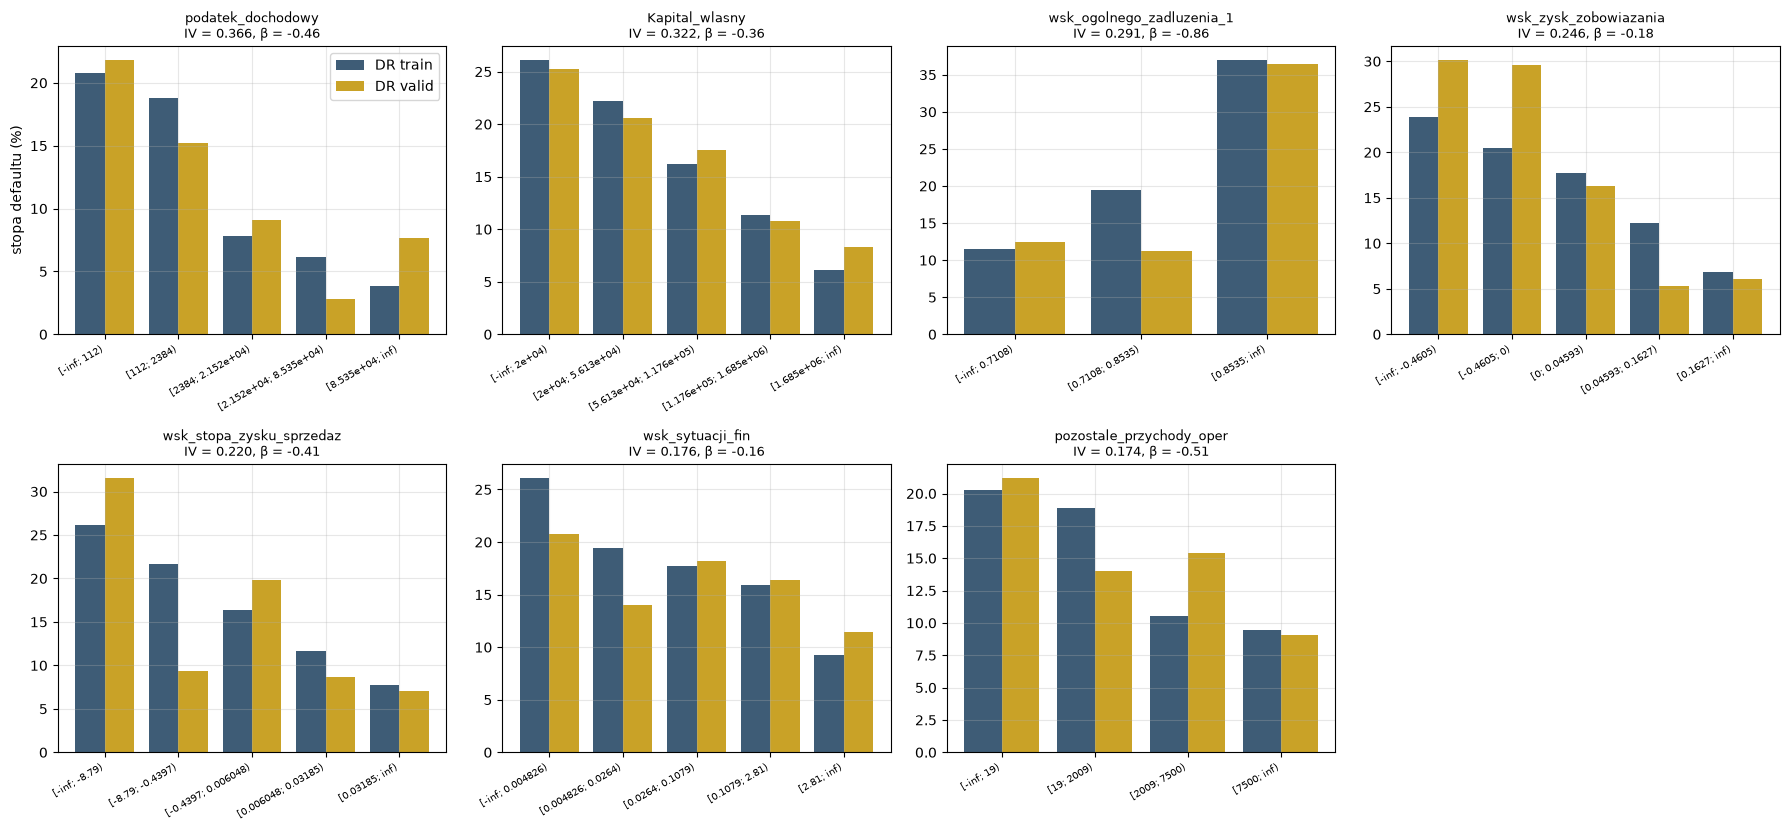

,przedziałów,kierunek na train,zgodnych zmian na valid
podatek_dochodowy,5,malejący,3 / 4
Kapital_wlasny,5,malejący,4 / 4
wsk_ogolnego_zadluzenia_1,3,rosnący,1 / 2
wsk_zysk_zobowiazania,5,malejący,3 / 4
wsk_stopa_zysku_sprzedaz,5,malejący,3 / 4
wsk_sytuacji_fin,5,malejący,3 / 4
pozostale_przychody_oper,4,malejący,2 / 3


In [22]:
kody_va = woe_l.codes(X_va[CECHY_L])
n_kol = 4; n_wier = int(np.ceil(len(CECHY_L) / n_kol))
fig, axes = plt.subplots(n_wier, n_kol, figsize=(18, 4.2 * n_wier)); axes = np.atleast_2d(axes)
monot = {}
for ax, c in zip(axes.flat, CECHY_L):
    tab = woe_l.tables_[c].copy()
    tab["stopa złych (valid)"] = [y_va[kody_va[c].to_numpy() == i].mean() if np.any(kody_va[c].to_numpy() == i) else np.nan for i in range(len(tab))]
    x_ = np.arange(len(tab))
    ax.bar(x_ - 0.2, 100 * tab["stopa złych"], 0.4, color=KOL["train"], label="DR train")
    ax.bar(x_ + 0.2, 100 * tab["stopa złych (valid)"], 0.4, color=KOL["valid"], label="DR valid")
    ax.set_xticks(x_); ax.set_xticklabels(tab["przedział"], rotation=30, ha="right", fontsize=7)
    ax.set_title(f"{c}\nIV = {woe_l.iv_[c]:.3f}, β = {beta_l[c]:+.2f}", fontsize=9); ax.grid(alpha=0.3)
    br = tab.loc[tab["przedział"] != "BRAK"]
    kier_tr, kier_va = np.sign(np.diff(br["stopa złych"])), np.sign(np.diff(br["stopa złych (valid)"]))
    monot[c] = {"przedziałów": len(br), "kierunek na train": "rosnący" if kier_tr.sum() > 0 else "malejący",
                "zgodnych zmian na valid": f"{int((kier_tr == kier_va).sum())} / {len(kier_tr)}"}
for ax in axes.flat[len(CECHY_L):]:
    ax.axis("off")
axes.flat[0].legend(); axes.flat[0].set_ylabel("stopa defaultu (%)")
plt.tight_layout(); plt.savefig("wykresy/karta_woe_profile.png", dpi=120); plt.show()
display(pd.DataFrame(monot).T)

**Wnioski:** wszystkie kierunki zgadzają się z intuicją ekonomiczną: wyższy podatek dochodowy (proxy zysku), kapitał własny,
rentowność sprzedaży i zysk względem zobowiązań oraz wyższe pozostałe przychody operacyjne → niższe ryzyko; wyższe zadłużenie
ogólne → wyższe ryzyko (skok powyżej ok. 0,85). Na valid 19 z 25 zmian między sąsiednimi przedziałami ma ten sam kierunek co na
train; niezgodności dotyczą środkowych przedziałów, w których na valid jest kilka-kilkanaście defaultów.

### 5.4 Karta punktowa (PDO) i dekompozycja wyniku

Skalowanie z Lab 1: 600 pkt przy szansach dobry:zły 50:1, PDO = 20 (co 20 pkt szanse się podwajają).
$\text{Punkty}_{ij} = \text{Factor}\cdot(-\beta_j\,\text{WoE}_{ij} - \beta_0/k) + \text{Offset}/k$. Suma punktów firmy
odpowiada logitowi modelu - to **bezpośrednia, dokładna dekompozycja wyniku na wkłady cech** (interpretacja lokalna 9.1).

In [23]:
PDO, SCORE_REF, ODDS_REF = 20, 600, 50                        # z Lab 1 (sekcja 8)
factor = PDO / np.log(2)
offset = SCORE_REF - factor * np.log(ODDS_REF)
b0, betas, k_ = lr_l.intercept_[0], dict(zip(CECHY_L, lr_l.coef_.ravel())), len(CECHY_L)
wiersze = []
for c in CECHY_L:
    tab = woe_l.tables_[c]
    for lab, w in zip(tab["przedział"], tab["WoE"]):
        wiersze.append({"cecha": c, "atrybut": lab, "WoE": w, "punkty": factor * (-betas[c] * w - b0 / k_) + offset / k_})
karta_pkt = pd.DataFrame(wiersze)
karta_pkt["punkty (zaokr.)"] = karta_pkt["punkty"].round().astype(int)
print(f"Factor = {factor:.3f}, Offset = {offset:.2f}")
display(karta_pkt[["cecha", "atrybut", "WoE", "punkty (zaokr.)"]].round(3))

def punkty_firmy(Xw):
    # punkty każdej cechy dla firm z Xw (wiersze) - dekompozycja wyniku karty
    W = woe_l.transform(Xw[CECHY_L])
    return pd.DataFrame({c: factor * (-betas[c] * W[c] - b0 / k_) + offset / k_ for c in CECHY_L}, index=Xw.index)

wynik_model = offset + factor * (-baseline.decision_function(X_te[CECHY_L]))
print("Suma punktów zgodna z modelem:", np.allclose(punkty_firmy(X_te).sum(axis=1), wynik_model),
      f"| wynik na teście: min {wynik_model.min():.0f}, mediana {np.median(wynik_model):.0f}, max {wynik_model.max():.0f}")

Factor = 28.854, Offset = 487.12


,cecha,atrybut,WoE,punkty (zaokr.)
0,podatek_dochodowy,[-inf; 112),-0.404,71
1,podatek_dochodowy,[112; 2384),-0.288,73
2,podatek_dochodowy,[2384; 2.152e+04),0.713,86
3,podatek_dochodowy,[2.152e+04; 8.535e+04),0.950,90
4,podatek_dochodowy,[8.535e+04; inf),1.406,96
5,Kapital_wlasny,[-inf; 2e+04),-0.705,70
6,Kapital_wlasny,[2e+04; 5.613e+04),-0.493,72
7,Kapital_wlasny,[5.613e+04; 1.176e+05),-0.111,76
8,Kapital_wlasny,[1.176e+05; 1.685e+06),0.306,80
9,Kapital_wlasny,[1.685e+06; inf),0.973,87


Suma punktów zgodna z modelem: True | wynik na teście: min 480, mediana 547, max 597


### 5.5 Stabilność modelu interpretowalnego w 5-krotnej CV (train)

W każdym foldzie od nowa: binning, WoE i regresja. Raportujemy rozrzut metryk i współczynników - czy znaki β są
stabilne między foldami.

In [24]:
def metryki_cv(budowa, cechy):
    wiersze, bety = [], []
    for k, (a, b) in enumerate(FOLDY, start=1):
        m = budowa().fit(X_tr.iloc[a][cechy], y_tr[a])
        p = m.predict_proba(X_tr.iloc[b][cechy])[:, 1]
        w = metryki(y_tr[b], p); w["fold"] = k; wiersze.append(w)
        if "lr" in m.named_steps:
            bety.append(pd.Series(m.named_steps["lr"].coef_.ravel(), index=cechy))
    return pd.DataFrame(wiersze).set_index("fold"), (pd.DataFrame(bety) if bety else None)

cv_logit, bety_cv = metryki_cv(lambda: karta(CECHY_L), CECHY_L)
KOL_CV = ["AUC", "Gini", "KS", "PR-AUC", "log-loss", "Brier"]
display(cv_logit[KOL_CV].round(4))
print("Średnia ± odch. std.:", {c: f"{cv_logit[c].mean():.3f} ± {cv_logit[c].std():.3f}" for c in ["Gini", "KS", "log-loss"]})
display(pd.DataFrame({"β (cały train)": beta_l, "β CV średnia": bety_cv.mean(), "β CV odch. std.": bety_cv.std(),
                      "znak ujemny w foldach": (bety_cv < 0).sum().astype(str) + " / 5"}).round(3))

,AUC,Gini,KS,PR-AUC,log-loss,Brier
fold,,,,,,
1,0.6429,0.2858,0.2192,0.2473,0.4108,0.1238
2,0.7788,0.5576,0.4263,0.4265,0.3543,0.1078
3,0.6845,0.3689,0.3096,0.3209,0.3965,0.1192
4,0.7001,0.4002,0.3216,0.3235,0.3863,0.1175
5,0.7557,0.5115,0.4119,0.3533,0.3639,0.1114


Średnia ± odch. std.: {'Gini': '0.425 ± 0.110', 'KS': '0.338 ± 0.084', 'log-loss': '0.382 ± 0.023'}


,β (cały train),β CV średnia,β CV odch. std.,znak ujemny w foldach
podatek_dochodowy,-0.465,-0.459,0.080,5 / 5
Kapital_wlasny,-0.356,-0.379,0.044,5 / 5
wsk_ogolnego_zadluzenia_1,-0.856,-0.867,0.046,5 / 5
wsk_zysk_zobowiazania,-0.177,-0.175,0.154,4 / 5
wsk_stopa_zysku_sprzedaz,-0.412,-0.431,0.103,5 / 5
wsk_sytuacji_fin,-0.160,-0.138,0.080,5 / 5
pozostale_przychody_oper,-0.508,-0.508,0.081,5 / 5


**Wnioski:** Gini w foldach waha się od 0,29 do 0,56 (0,43 ± 0,11). Rozrzut jest duży, bo w foldzie walidacyjnym jest tylko ok. 53
defaultów - pojedyncza ocena na małym zbiorze jest niepewna, dlatego raportujemy przedziały bootstrap (6.2). Znaki β są stabilne:
34 z 35 współczynników w foldach jest ujemnych; wyjątek to najsłabsza cecha `wsk_zysk_zobowiazania` (β = -0,18 ± 0,15).

## 6. Model black-box: XGBoost

### 6.1 Przygotowanie cech i strojenie z kontrolą przeuczenia

- wszystkie cechy liczbowe (192) bez przekształceń - drzewa obsługują braki i są odporne na skrajne wartości,
- kategorie: one-hot, rzadkie poziomy (< 20 firm w train) łączone w „infrequent”,
- **losowe przeszukiwanie (40 konfiguracji) w 5-krotnej CV na train**, kryterium: log-loss (dyskryminacja i kalibracja naraz),
- kontrola przeuczenia: płytkie drzewa, minimalna waga liścia, losowanie wierszy i kolumn, regularyzacja L2 i γ;
  porównujemy wyniki na foldach treningowych i walidacyjnych CV,
- bez wag klas i bez oversamplingu - wtedy PD nie wymaga korekty a priori (Lab 2).

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

def preprocessing_drzewa():
    return ColumnTransformer([("num", "passthrough", num_cols),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat_cols)])

def model_black_box(**parametry):
    ustawienia = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5, subsample=0.8,
                      colsample_bytree=0.5, reg_lambda=5.0, gamma=0.0, tree_method="hist", eval_metric="logloss",
                      n_jobs=-1, random_state=RNG_SEED)
    ustawienia.update(parametry)
    return Pipeline([("pre", preprocessing_drzewa()), ("clf", XGBClassifier(**ustawienia))])

siatka_xgb = {"clf__n_estimators": [100, 200, 300, 500, 800], "clf__learning_rate": [0.01, 0.02, 0.05, 0.1],
              "clf__max_depth": [2, 3, 4, 5], "clf__min_child_weight": [1, 5, 10, 20],
              "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.2, 0.35, 0.5, 0.8],
              "clf__reg_lambda": [1.0, 5.0, 10.0, 30.0], "clf__gamma": [0.0, 0.5, 2.0]}
szukaj = RandomizedSearchCV(model_black_box(), siatka_xgb, n_iter=40, scoring={"log-loss": "neg_log_loss", "AUC": "roc_auc"},
                            refit="log-loss", cv=FOLDY, random_state=RNG_SEED, return_train_score=True, n_jobs=1)
szukaj.fit(X_tr, y_tr)
wyn = pd.DataFrame(szukaj.cv_results_)
tab_tuning = pd.DataFrame({"log-loss CV": -wyn["mean_test_log-loss"], "log-loss train": -wyn["mean_train_log-loss"],
                           "AUC CV": wyn["mean_test_AUC"], "AUC CV odch. std.": wyn["std_test_AUC"], "AUC train": wyn["mean_train_AUC"]})
tab_tuning = pd.concat([wyn[[c for c in wyn if c.startswith("param_")]].rename(columns=lambda c: c.replace("param_clf__", "")), tab_tuning], axis=1)
tab_tuning["luka AUC (train - CV)"] = tab_tuning["AUC train"] - tab_tuning["AUC CV"]
display(tab_tuning.sort_values("log-loss CV").head(8).round(4))
PARAM_BB = {k.replace("clf__", ""): v for k, v in szukaj.best_params_.items()}
print("Wybrane hiperparametry:", PARAM_BB)
json.dump(PARAM_BB, open("wyniki/xgboost_parametry.json", "w"), indent=1)

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,log-loss CV,log-loss train,AUC CV,AUC CV odch. std.,AUC train,luka AUC (train - CV)
19,1.0,5.0,300,5,4,0.01,2.0,0.35,0.3766,0.3032,0.7209,0.0453,0.9071,0.1862
20,0.8,1.0,200,10,5,0.02,0.5,0.50,0.3790,0.2787,0.7161,0.0470,0.9284,0.2122
12,1.0,5.0,100,1,5,0.02,0.0,0.20,0.3790,0.2917,0.7171,0.0523,0.9450,0.2279
3,1.0,10.0,300,5,4,0.05,2.0,0.80,0.3795,0.2897,0.7154,0.0404,0.9169,0.2015
8,1.0,1.0,100,10,5,0.05,2.0,0.35,0.3797,0.2672,0.7155,0.0429,0.9420,0.2264
15,0.8,10.0,300,1,4,0.02,0.5,0.20,0.3809,0.2599,0.7092,0.0560,0.9521,0.2429
31,0.6,5.0,500,20,5,0.02,0.0,0.20,0.3817,0.3220,0.7073,0.0521,0.8520,0.1447
9,0.8,10.0,300,20,5,0.02,2.0,0.80,0.3818,0.3203,0.7071,0.0494,0.8575,0.1504


Wybrane hiperparametry: {'subsample': 1.0, 'reg_lambda': 5.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 2.0, 'colsample_bytree': 0.35}


**Wnioski:** najlepsza konfiguracja jest silnie regularyzowana: 300 drzew o głębokości ≤ 4, `learning_rate` 0,01, losowanie 35%
cech na drzewo, γ = 2. Nawet ona ma na foldach treningowych AUC ok. 0,91 przy 0,72 w CV - przy 1800 firmach i 190 cechach boosting
łatwo zapamiętuje dane, dlatego o wyborze decyduje wyłącznie wynik w CV, a nie dopasowanie na train.

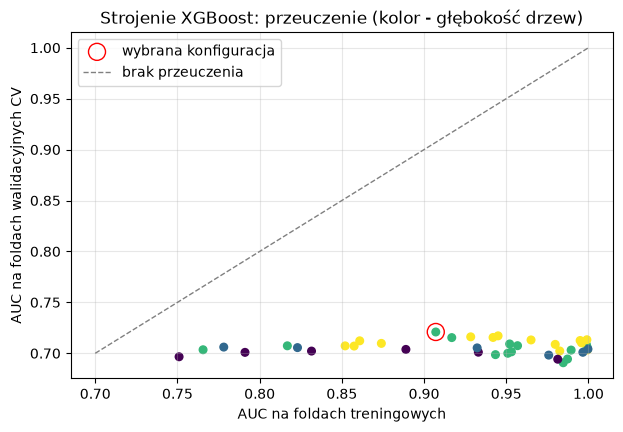

In [26]:
ax = plt.gca()
ax.scatter(tab_tuning["AUC train"], tab_tuning["AUC CV"], c=tab_tuning["max_depth"].astype(float), cmap="viridis", s=30)
najl_i = szukaj.best_index_
ax.scatter(tab_tuning.loc[najl_i, "AUC train"], tab_tuning.loc[najl_i, "AUC CV"], s=150, facecolors="none", edgecolors="red", label="wybrana konfiguracja")
ax.plot([0.7, 1], [0.7, 1], "--", color="gray", lw=1, label="brak przeuczenia")
ax.set_xlabel("AUC na foldach treningowych"); ax.set_ylabel("AUC na foldach walidacyjnych CV")
ax.set_title("Strojenie XGBoost: przeuczenie (kolor - głębokość drzew)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

Wybieramy konfigurację z najniższym log-loss w CV. Konfiguracje z głębokimi drzewami i bez regularyzacji mają AUC na
foldach treningowych bliskie 1 przy gorszym AUC w CV - to przeuczenie, którego unikamy. Model końcowy uczymy na całym train.

In [27]:
black_box = model_black_box(**PARAM_BB).fit(X_tr, y_tr)
P["black-box"] = {s: black_box.predict_proba(X[s])[:, 1] for s in X}
display(pd.DataFrame({s: metryki(Y[s], P["black-box"][s]) for s in X}).T.round(4))

,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1467,0.8964,0.7928,0.6523,0.6490,0.3079,0.0928,0.0763,0.0857,0.0140,2.4661
valid,600.0,0.1483,0.1412,0.7350,0.4701,0.3477,0.3691,0.3690,0.1118,0.0347,0.0345,0.0631,1.1646
test,599.0,0.1486,0.1412,0.7431,0.4863,0.3672,0.3417,0.3723,0.1135,0.0145,0.0241,0.0661,1.0743


### 6.2 Porównanie jakości na valid i teście

,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
logit (valid),0.1438,0.7187,0.4375,0.3506,0.3244,0.3774,0.1148,0.0302,0.0337,0.0400,0.9450
black-box (valid),0.1412,0.7350,0.4701,0.3477,0.3691,0.3690,0.1118,0.0347,0.0345,0.0631,1.1646
logit (test),0.1435,0.7298,0.4597,0.3527,0.3312,0.3774,0.1148,0.0171,0.0250,0.0459,0.9252
black-box (test),0.1412,0.7431,0.4863,0.3672,0.3417,0.3723,0.1135,0.0145,0.0241,0.0661,1.0743


,AUC 95% CI,PR-AUC 95% CI,KS 95% CI,log-loss 95% CI
logit (test),[0.674; 0.785],[0.252; 0.437],[0.283; 0.474],[0.328; 0.429]
black-box (test),[0.690; 0.800],[0.265; 0.451],[0.310; 0.495],[0.326; 0.421]


Różnica Gini (black-box - logit) na teście: +0.0259, 95% przedział bootstrap (sparowany): [-0.0389; +0.0912]
Różnica Gini (black-box - logit) na valid:  +0.0332, 95% przedział bootstrap (sparowany): [-0.0301; +0.1042]


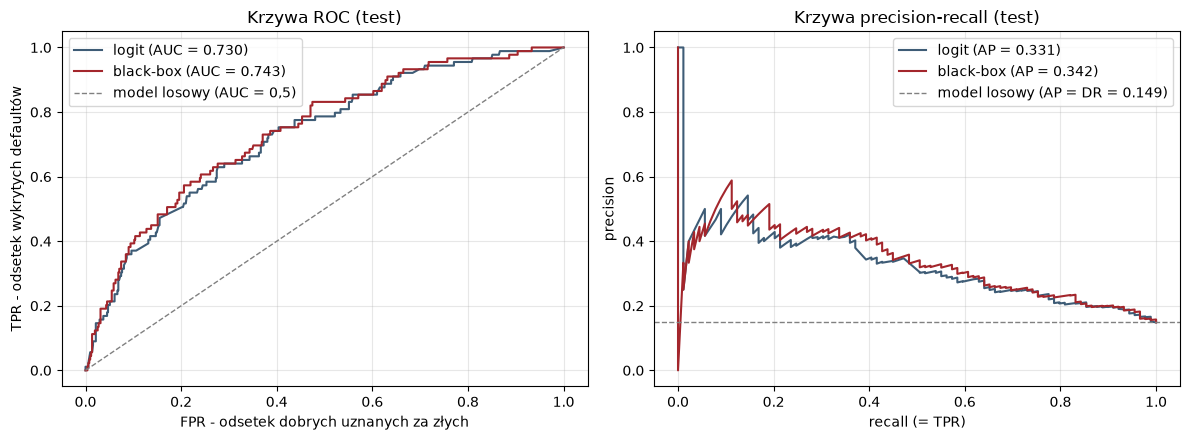

In [28]:
porownanie = pd.DataFrame({f"{m} ({s})": metryki(Y[s], P[m][s]) for s in ["valid", "test"] for m in ["logit", "black-box"]}).T
display(porownanie.drop(columns=["n", "DR"]).round(4))

def bootstrap_roznica_gini(y, p_a, p_b, B=1000, seed=RNG_SEED):     # z Lab 3
    rng = np.random.default_rng(seed); d = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        d.append(2 * (roc_auc_score(y[i], p_b[i]) - roc_auc_score(y[i], p_a[i])))
    return float(np.mean(d)), np.percentile(d, [2.5, 97.5])

def bootstrap_ci(y, p, B=1000, seed=RNG_SEED):                     # z Lab 3
    rng = np.random.default_rng(seed); w = {"AUC": [], "PR-AUC": [], "KS": [], "log-loss": []}
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        w["AUC"].append(roc_auc_score(y[i], p[i])); w["PR-AUC"].append(average_precision_score(y[i], p[i]))
        w["KS"].append(ks(y[i], p[i])); w["log-loss"].append(log_loss(y[i], np.clip(p[i], EPS, 1 - EPS)))
    return {f"{k} 95% CI": f"[{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]" for k, v in w.items()}

display(pd.DataFrame({f"{m} (test)": bootstrap_ci(y_te, P[m]["test"]) for m in ["logit", "black-box"]}).T)
sr, (lo, hi) = bootstrap_roznica_gini(y_te, P["logit"]["test"], P["black-box"]["test"])
print(f"Różnica Gini (black-box - logit) na teście: {sr:+.4f}, 95% przedział bootstrap (sparowany): [{lo:+.4f}; {hi:+.4f}]")
sr_v, (lo_v, hi_v) = bootstrap_roznica_gini(y_va, P["logit"]["valid"], P["black-box"]["valid"])
print(f"Różnica Gini (black-box - logit) na valid:  {sr_v:+.4f}, 95% przedział bootstrap (sparowany): [{lo_v:+.4f}; {hi_v:+.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                  # z Lab 3
for m in ["logit", "black-box"]:
    fpr, tpr, _ = roc_curve(y_te, P[m]["test"])
    axes[0].plot(fpr, tpr, color=KOL[m], label=f"{m} (AUC = {roc_auc_score(y_te, P[m]['test']):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, P[m]["test"])
    axes[1].plot(rec, prec, color=KOL[m], label=f"{m} (AP = {average_precision_score(y_te, P[m]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1, label="model losowy (AUC = 0,5)")
axes[1].axhline(y_te.mean(), ls="--", color="gray", lw=1, label=f"model losowy (AP = DR = {y_te.mean():.3f})")
axes[0].set_xlabel("FPR - odsetek dobrych uznanych za złych"); axes[0].set_ylabel("TPR - odsetek wykrytych defaultów"); axes[0].set_title("Krzywa ROC (test)")
axes[1].set_xlabel("recall (= TPR)"); axes[1].set_ylabel("precision"); axes[1].set_title("Krzywa precision-recall (test)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/roc_pr_test.png", dpi=120); plt.show()

**Wnioski:** black-box ma wyższy Gini o ok. 0,03 na valid i na teście (0,49 vs 0,46 na teście), nieco niższy log-loss i Brier.
Sparowany przedział bootstrap różnicy Gini obejmuje jednak zero (test: [-0,04; +0,09]) - **przewaga black-boxa w dyskryminacji
jest statystycznie niepewna**. Przy DR ≈ 15% losowy model ma PR-AUC ≈ 0,15; oba modele mają ok. 0,33-0,34.

### 6.3 Stabilność obu modeli w 5-krotnej CV (wariancja metryk)

,średnia,odch. std.,min,max
logit: Gini,0.4248,0.1097,0.2858,0.5576
logit: KS,0.3377,0.0843,0.2192,0.4263
logit: PR-AUC,0.3343,0.0647,0.2473,0.4265
logit: log-loss,0.3824,0.0232,0.3543,0.4108
logit: Brier,0.1159,0.0064,0.1078,0.1238
black-box: Gini,0.4418,0.1013,0.3099,0.5554
black-box: KS,0.3639,0.0758,0.2901,0.4551
black-box: PR-AUC,0.3684,0.0791,0.2458,0.4658
black-box: log-loss,0.3766,0.0188,0.3539,0.4009
black-box: Brier,0.1143,0.0057,0.1074,0.1224


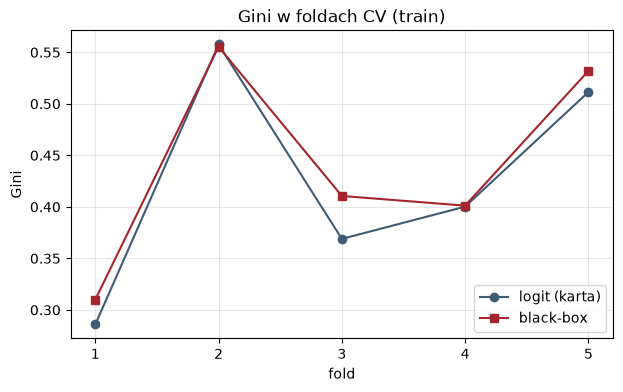

In [29]:
cv_bb, _ = metryki_cv(lambda: model_black_box(**PARAM_BB), FEATURES)
stab = pd.DataFrame({f"{m}: {c}": {"średnia": t[c].mean(), "odch. std.": t[c].std(), "min": t[c].min(), "max": t[c].max()}
                     for m, t in [("logit", cv_logit), ("black-box", cv_bb)] for c in ["Gini", "KS", "PR-AUC", "log-loss", "Brier"]}).T
display(stab.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv_logit.index, cv_logit["Gini"], "o-", color=KOL["logit"], label="logit (karta)")
ax.plot(cv_bb.index, cv_bb["Gini"], "s-", color=KOL["black-box"], label="black-box")
ax.set_xticks(cv_bb.index); ax.set_xlabel("fold"); ax.set_ylabel("Gini"); ax.set_title("Gini w foldach CV (train)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

**Wnioski:** w CV black-box ma średnio Gini wyższy o ok. 0,02 przy podobnym rozrzucie (odch. std. 0,10 vs 0,11). Rozrzut między
foldami (Gini karty od 0,29 do 0,56) jest kilka razy większy niż różnica między modelami - różnica jakości jest niewielka
w porównaniu z niepewnością wynikającą z małej liczby defaultów.

### 6.4 Złożoność modeli

In [30]:
booster = black_box.named_steps["clf"].get_booster()
drzewa = booster.trees_to_dataframe()
uzyte = (booster.get_score(importance_type="weight"))
zlozonosc = pd.DataFrame({
    "logit (karta)": {"liczba cech wejściowych": len(CECHY_L), "cechy faktycznie używane": len(CECHY_L),
                      "parametry / drzewa": f"{len(CECHY_L) + 1} współczynników",
                      "przedziały / liście": int(sum(len(woe_l.tables_[c]) for c in CECHY_L)),
                      "monotoniczność": "wymuszona (WoE monotoniczne)"},
    "black-box (XGBoost)": {"liczba cech wejściowych": len(FEATURES), "cechy faktycznie używane": len(uzyte),
                            "parametry / drzewa": f"{drzewa['Tree'].nunique()} drzew, głębokość ≤ {PARAM_BB['max_depth']}",
                            "przedziały / liście": int((drzewa["Feature"] == "Leaf").sum()),
                            "monotoniczność": "brak ograniczeń"}})
display(zlozonosc)

,logit (karta),black-box (XGBoost)
liczba cech wejściowych,7,192
cechy faktycznie używane,7,164
parametry / drzewa,8 współczynników,"300 drzew, głębokość ≤ 4"
przedziały / liście,32,2915
monotoniczność,wymuszona (WoE monotoniczne),brak ograniczeń


## 7. Wyjaśnienia globalne

**Ustawienia (Lab 4):** SHAP liczymy w **log-szansach**. Dla karty - wzór zamknięty φ_j = β_j·(WoE_j(x) - E[WoE_j]),
tło = cały train (model liniowy w przestrzeni WoE, więc to dokładne wartości Shapleya przy niezależnych cechach).
Dla XGBoost - `TreeExplainer`, wariant `tree_path_dependent` (bez tła; wartość bazowa = średnia log-szans na train).
Kolumny one-hot jednej cechy sumujemy do cechy źródłowej.

### 7.1 SHAP: wyliczenie i kontrola addytywności

In [31]:
pre_bb, clf_bb = black_box.named_steps["pre"], black_box.named_steps["clf"]
nazwy_bb = list(pre_bb.get_feature_names_out())

def zrodlo(nazwa):                                            # z Lab 4 (zmienione pod nazwy ColumnTransformer)
    if nazwa.startswith("num__"):
        return nazwa[5:]
    return next(c for c in cat_cols if nazwa.startswith(f"cat__{c}_"))

G_bb = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in nazwy_bb])     # z Lab 4: macierz grupowania kolumn
explainer = shap.TreeExplainer(clf_bb)
sv_te = explainer(pre_bb.transform(X_te))
PHI_BB = sv_te.values @ G_bb
BAZA_BB = float(np.ravel(sv_te.base_values)[0])
blad_bb = np.abs(BAZA_BB + PHI_BB.sum(axis=1) - _z(P["black-box"]["test"])).max()

W_tlo = woe_l.transform(X_tr[CECHY_L]).mean()
def shap_logit(Xw):
    # wzór zamknięty dla modelu liniowego w przestrzeni WoE (Lab 4, sekcja 3)
    return (woe_l.transform(Xw[CECHY_L]) - W_tlo) * lr_l.coef_.ravel()
PHI_LOG = shap_logit(X_te)
BAZA_LOG = float(lr_l.intercept_[0] + (W_tlo * lr_l.coef_.ravel()).sum())
blad_log = np.abs(BAZA_LOG + PHI_LOG.sum(axis=1) - baseline.decision_function(X_te[CECHY_L])).max()
print(f"Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box {blad_bb:.1e}, karta {blad_log:.1e}")
print(f"Wartość bazowa: black-box {BAZA_BB:+.3f} log-szans (PD {expit(BAZA_BB):.1%}), karta {BAZA_LOG:+.3f} (PD {expit(BAZA_LOG):.1%})")

Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box 2.9e-06, karta 8.9e-16
Wartość bazowa: black-box -1.763 log-szans (PD 14.6%), karta -2.028 (PD 11.6%)


Addytywność jest spełniona z dokładnością numeryczną - suma wkładów odtwarza log-szanse każdej firmy. Wartość bazowa karty
(log-szanse przy średnim WoE) różni się od logitu średniego PD, bo funkcja logistyczna jest nieliniowa.

### 7.2 Ważność cech: SHAP i permutacja

Dwie miary: średnie |SHAP| na teście (wkład do log-szans) i **ważność permutacyjna** na valid (spadek AUC po
przemieszaniu cechy - Lab 1, Lab 3). Permutacja jest agnostyczna, więc liczymy ją dla obu modeli tą samą metodą.

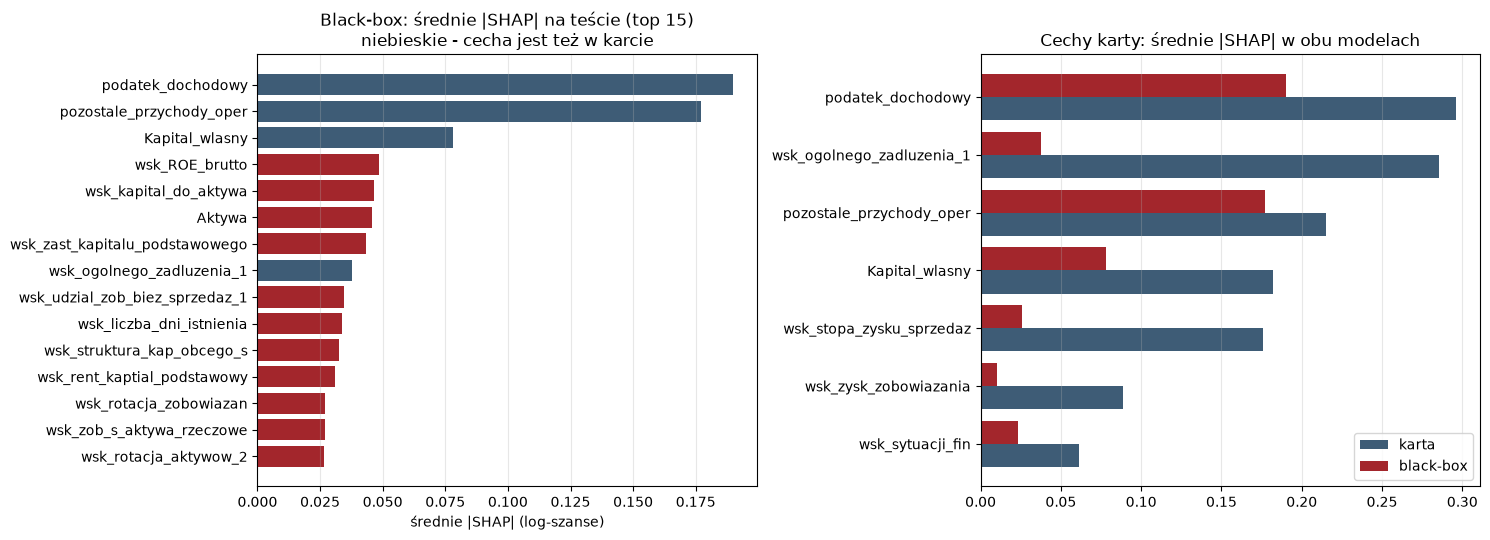

,|SHAP| black-box,ranga SHAP bb,permutacja bb (spadek AUC),ranga perm. bb
podatek_dochodowy,0.1899,1,0.0059,2
pozostale_przychody_oper,0.1772,2,0.0093,1
Kapital_wlasny,0.0781,3,0.0026,6
wsk_ROE_brutto,0.0487,4,0.0041,3
wsk_kapital_do_aktywa,0.0466,5,-0.0029,192
Aktywa,0.0457,6,0.0012,19
wsk_zast_kapitalu_podstawowego,0.0434,7,0.0017,10
wsk_ogolnego_zadluzenia_1,0.0376,8,0.0004,37
wsk_udzial_zob_biez_sprzedaz_1,0.0346,9,0.0013,15
wsk_liczba_dni_istnienia,0.0336,10,0.0031,5


Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): 0.23


,|SHAP| karta,permutacja karta,|SHAP| black-box,ranga w black-boxie (z 192)
Kapital_wlasny,0.1820,0.0067,0.0781,3
podatek_dochodowy,0.2962,0.0242,0.1899,1
pozostale_przychody_oper,0.2149,0.0150,0.1772,2
wsk_ogolnego_zadluzenia_1,0.2853,0.0472,0.0376,8
wsk_stopa_zysku_sprzedaz,0.1760,0.0118,0.0256,16
wsk_sytuacji_fin,0.0614,0.0002,0.0230,18
wsk_zysk_zobowiazania,0.0889,0.0079,0.0102,41


In [32]:
from sklearn.inspection import permutation_importance

waz_shap_bb = pd.Series(np.abs(PHI_BB).mean(axis=0), index=FEATURES).sort_values(ascending=False)
waz_shap_log = np.abs(PHI_LOG).mean().sort_values(ascending=False)
perm_bb = permutation_importance(black_box, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=RNG_SEED)
perm_log = permutation_importance(baseline, X_va[CECHY_L], y_va, scoring="roc_auc", n_repeats=20, random_state=RNG_SEED)
waz_perm_bb = pd.Series(perm_bb.importances_mean, index=FEATURES)
waz_perm_log = pd.Series(perm_log.importances_mean, index=CECHY_L)

TOP_BB = waz_shap_bb.index[:15].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = waz_shap_bb[TOP_BB][::-1]
axes[0].barh(t.index, t.values, color=[KOL["logit"] if c in CECHY_L else KOL["black-box"] for c in t.index])
axes[0].set_title("Black-box: średnie |SHAP| na teście (top 15)\nniebieskie - cecha jest też w karcie"); axes[0].set_xlabel("średnie |SHAP| (log-szanse)")
t2 = pd.DataFrame({"karta: |SHAP|": waz_shap_log, "black-box: |SHAP| tej cechy": waz_shap_bb[CECHY_L]}).sort_values("karta: |SHAP|")
yy = np.arange(len(t2))
axes[1].barh(yy - 0.2, t2["karta: |SHAP|"], 0.4, color=KOL["logit"], label="karta")
axes[1].barh(yy + 0.2, t2["black-box: |SHAP| tej cechy"], 0.4, color=KOL["black-box"], label="black-box")
axes[1].set_yticks(yy); axes[1].set_yticklabels(t2.index); axes[1].legend(); axes[1].set_title("Cechy karty: średnie |SHAP| w obu modelach")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/shap_waznosc.png", dpi=120); plt.show()

ranking = pd.DataFrame({"|SHAP| black-box": waz_shap_bb, "ranga SHAP bb": waz_shap_bb.rank(ascending=False).astype(int),
                        "permutacja bb (spadek AUC)": waz_perm_bb, "ranga perm. bb": waz_perm_bb.rank(ascending=False).astype(int)})
display(ranking.sort_values("|SHAP| black-box", ascending=False).head(15).round(4))
print(f"Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): {spearmanr(waz_shap_bb, waz_perm_bb[waz_shap_bb.index])[0]:.2f}")
display(pd.DataFrame({"|SHAP| karta": waz_shap_log, "permutacja karta": waz_perm_log, "|SHAP| black-box": waz_shap_bb[CECHY_L],
                      "ranga w black-boxie (z 192)": waz_shap_bb.rank(ascending=False)[CECHY_L].astype(int)}).round(4))

**Wnioski:**
- Trzy najważniejsze cechy black-boxa według SHAP - `podatek_dochodowy`, `pozostale_przychody_oper`, `Kapital_wlasny` - są
  w karcie. `wsk_ogolnego_zadluzenia_1` jest 8., a trzy najsłabsze cechy karty są w black-boxie dalej (16., 18. i 41. miejsce).
- Zgodność SHAP i permutacji dla 192 cech black-boxa jest niska (ρ ≈ 0,23). Permutacja jednej z kilku skorelowanych cech prawie nie
  zmienia AUC, bo model korzysta z jej „bliźniaków” - ważność permutacyjna zaniża znaczenie skorelowanych cech. W karcie, gdzie cechy
  są słabo skorelowane (VIF < 2,2), obie miary dają podobny ranking.

### 7.3 Spójność wyjaśnień black-boxa z kartą

Black-box korzysta z 192 skorelowanych wskaźników, a karta z 7. Porównanie „cecha do cechy” jest więc niepełne:
SHAP rozdziela wkład między wiele wariantów tej samej miary. Dlatego grupujemy cechy black-boxa **tematycznie**:
do każdej cechy karty przypisujemy cechy black-boxa skorelowane z nią |ρ| ≥ 0,7 (train) i sumujemy ich średnie |SHAP|.

In [33]:
kor_tr = df_train[num_cols].corr(method="spearman")
temat = {}
przypisane = set()
for c in CECHY_L:
    grupa_c = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7 and f not in przypisane]
    przypisane |= set(grupa_c)
    temat[c] = {"cech w grupie": len(grupa_c), "suma |SHAP| grupy (black-box)": waz_shap_bb[grupa_c].sum(),
                "|SHAP| w karcie": waz_shap_log[c]}
reszta = [f for f in FEATURES if f not in przypisane]
temat["pozostałe cechy"] = {"cech w grupie": len(reszta), "suma |SHAP| grupy (black-box)": waz_shap_bb[reszta].sum(), "|SHAP| w karcie": 0.0}
tab_temat = pd.DataFrame(temat).T
tab_temat["udział w black-boxie"] = tab_temat["suma |SHAP| grupy (black-box)"] / tab_temat["suma |SHAP| grupy (black-box)"].sum()
tab_temat["udział w karcie"] = tab_temat["|SHAP| w karcie"] / tab_temat["|SHAP| w karcie"].sum()
display(tab_temat.round(3))
rho_temat = spearmanr(tab_temat.loc[CECHY_L, "suma |SHAP| grupy (black-box)"], tab_temat.loc[CECHY_L, "|SHAP| w karcie"])[0]
print(f"Korelacja rang ważności grup tematycznych (karta vs black-box): {rho_temat:.2f}")

,cech w grupie,suma |SHAP| grupy (black-box),|SHAP| w karcie,udział w black-boxie,udział w karcie
podatek_dochodowy,2.0,0.201,0.296,0.113,0.227
Kapital_wlasny,8.0,0.196,0.182,0.111,0.140
wsk_ogolnego_zadluzenia_1,17.0,0.250,0.285,0.141,0.219
wsk_zysk_zobowiazania,30.0,0.264,0.089,0.149,0.068
wsk_stopa_zysku_sprzedaz,2.0,0.048,0.176,0.027,0.135
wsk_sytuacji_fin,1.0,0.023,0.061,0.013,0.047
pozostale_przychody_oper,2.0,0.193,0.215,0.109,0.165
pozostałe cechy,130.0,0.597,0.000,0.337,0.000


Korelacja rang ważności grup tematycznych (karta vs black-box): 0.39


**Wnioski:** po zsumowaniu SHAP w grupy tematyczne oba modele opierają się na tych samych obszarach: zadłużenie i wypłacalność,
rentowność, zysk (podatek), kapitał własny, pozostałe przychody. Różnica wag jest umiarkowana (ρ rang grup ≈ 0,4): w karcie
większy udział mają zadłużenie i podatek, w black-boxie - grupa rentowności (`wsk_zysk_zobowiazania`, 30 wskaźników). Ok. 1/3
wkładu black-boxa pochodzi z cech spoza tematów karty (m.in. należności i ich rotacja, struktura aktywów) - to źródło jego niewielkiej przewagi.

### 7.4 Beeswarm i wykresy zależności SHAP

Wartości cech na wykresie beeswarm i osi X wykresów zależności są **rangami percentylowymi** (wskaźniki mają skrajne ogony).

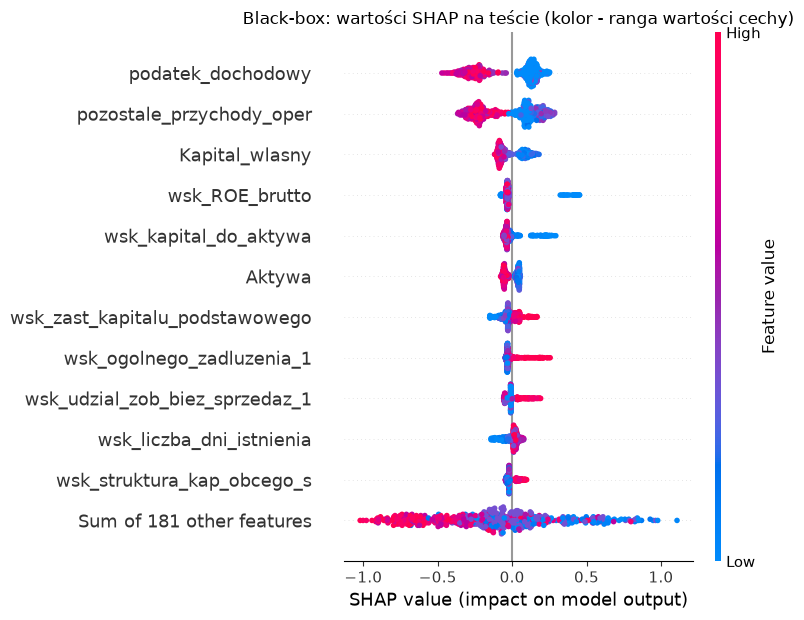

In [34]:
kolor_dane = X_te[num_cols].rank(pct=True).reindex(columns=FEATURES)
E_bb = shap.Explanation(values=PHI_BB, base_values=np.full(len(PHI_BB), BAZA_BB),
                        data=kolor_dane.to_numpy(dtype=float), feature_names=FEATURES)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    shap.plots.beeswarm(E_bb, max_display=12, show=False)
plt.title("Black-box: wartości SHAP na teście (kolor - ranga wartości cechy)"); plt.tight_layout()
plt.savefig("wykresy/shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

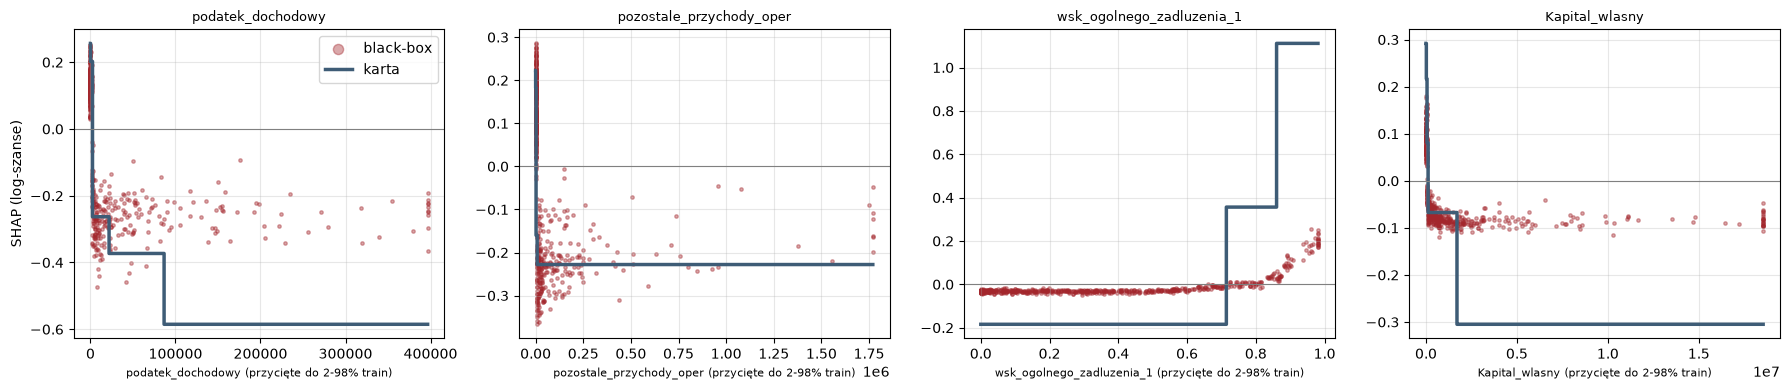

In [35]:
CECHY_DEP = [c for c in TOP_BB if c in num_cols][:2] + [c for c in waz_shap_log.index if c not in TOP_BB[:2]][:2]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_DEP):
    j = FEATURES.index(c); xv = X_te[c].to_numpy()
    lo, hi = np.nanpercentile(X_tr[c], [2, 98])
    ax.scatter(np.clip(xv, lo, hi), PHI_BB[:, j], s=6, alpha=0.4, color=KOL["black-box"], label="black-box")
    if c in CECHY_L:
        o = np.argsort(xv)
        ax.step(np.clip(xv[o], lo, hi), PHI_LOG[c].to_numpy()[o], color=KOL["logit"], lw=2.5, where="post", label="karta")
    ax.axhline(0, color="gray", lw=0.8); ax.set_title(c, fontsize=9); ax.set_xlabel(f"{c} (przycięte do 2-98% train)", fontsize=8); ax.grid(alpha=0.3)
axes[0].set_ylabel("SHAP (log-szanse)"); axes[0].legend(markerscale=3)
plt.tight_layout(); plt.savefig("wykresy/shap_zaleznosc.png", dpi=120); plt.show()

**Wnioski:** zależności black-boxa mają ten sam kierunek co schodki karty: większy podatek i kapitał własny obniżają ryzyko,
wysokie zadłużenie podnosi je skokowo. Black-box widzi dodatkowo kształty, których karta z 3-5 przedziałami nie oddaje,
np. plateau dla dużych wartości `pozostale_przychody_oper` i rozrzut wkładu przy tej samej wartości cechy (interakcje).

## 8. Kształt zależności: PDP, ICE, ALE (Lab 5)

Wszystkie krzywe w **log-szansach**, na próbie firm z testu (`XS`), siatka - kwantyle 2-98% z train (bez ekstrapolacji).
Funkcje `pdp`, `ice`, `ale`, `pdp_wysrodkowane` z Lab 5. Dla cech, których nie ma w karcie, krzywa karty jest płaska.

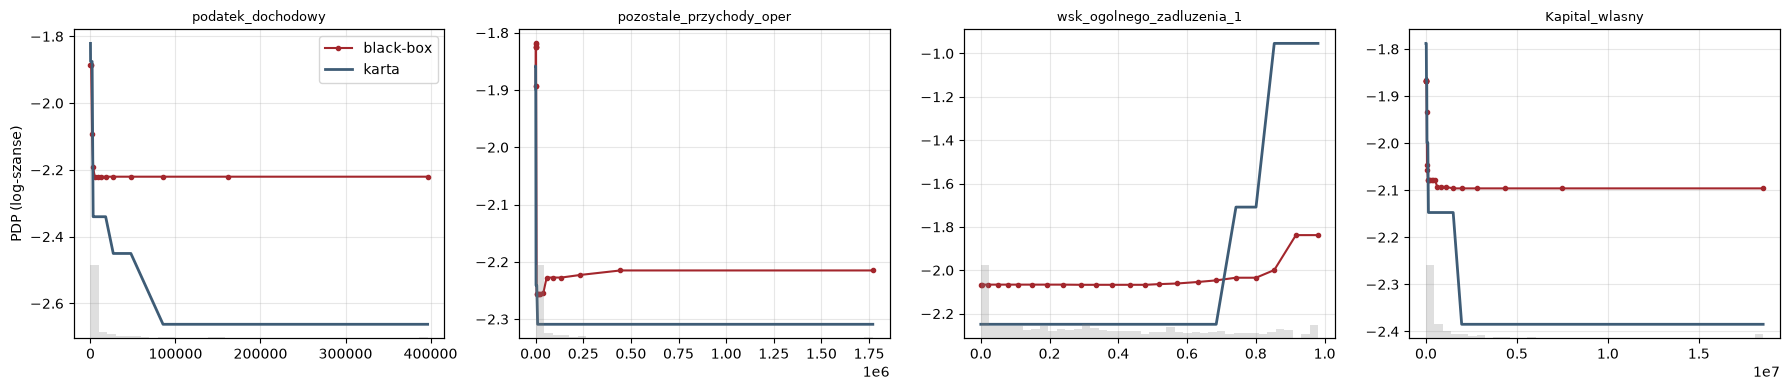

In [36]:
def log_szanse(model, cechy=None):                            # z Lab 4
    return lambda Xw: _z(model.predict_proba(Xw if cechy is None else Xw[cechy])[:, 1])

f_bb, f_lg = log_szanse(black_box), log_szanse(baseline, CECHY_L)
XS = X_te.reset_index(drop=True)

def siatka_kwantyli(cecha, n=25, lo=0.02, hi=0.98):          # z Lab 5
    return np.unique(np.quantile(X_tr[cecha].dropna(), np.linspace(lo, hi, n)))

def pdp(f, X, cecha, siatka):                                 # z Lab 5
    """PDP z definicji: wartość z siatki podstawiamy wszystkim firmom i uśredniamy prognozę."""
    wynik = []
    for v in siatka:
        Xv = X.copy(); Xv[cecha] = v
        wynik.append(np.mean(f(Xv)))
    return np.array(wynik)

def ice(f, X, cecha, siatka):                                 # z Lab 5
    """Macierz ICE (firmy × siatka): prognoza każdej firmy dla każdej wartości cechy."""
    duze = pd.concat([X.assign(**{cecha: v}) for v in siatka], ignore_index=True)
    return np.asarray(f(duze)).reshape(len(siatka), len(X)).T

def ale(f, X, cecha, K=20):                                   # z Lab 5
    """ALE pierwszego rzędu z definicji."""
    x = X[cecha].to_numpy(dtype=float); ok = ~np.isnan(x)
    granice = np.unique(np.quantile(x[ok], np.linspace(0, 1, K + 1)))
    k = np.clip(np.searchsorted(granice, x[ok], side="left") - 1, 0, len(granice) - 2)
    Xd, Xg = X.loc[ok].copy(), X.loc[ok].copy()
    Xd[cecha], Xg[cecha] = granice[k], granice[k + 1]
    roznice = f(Xg) - f(Xd)
    n_k = np.bincount(k, minlength=len(granice) - 1)
    efekt = np.bincount(k, weights=roznice, minlength=len(granice) - 1) / np.maximum(n_k, 1)
    a = np.concatenate([[0.0], np.cumsum(efekt)])
    a -= np.sum((a[:-1] + a[1:]) / 2 * n_k) / n_k.sum()
    return granice, a, n_k

def pdp_wysrodkowane(f, X, cecha, siatka):                    # z Lab 5
    p = pdp(f, X, cecha, siatka)
    return p - np.interp(X[cecha].dropna(), siatka, p).mean()

CECHY_PDP = CECHY_DEP
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_PDP):
    s = siatka_kwantyli(c)
    ax.plot(s, pdp(f_bb, XS, c, s), "o-", ms=3, color=KOL["black-box"], label="black-box")
    ax.plot(s, pdp(f_lg, XS, c, s), "-", lw=2, color=KOL["logit"], label="karta")
    ax2 = ax.twinx(); ax2.hist(XS[c].dropna().clip(s.min(), s.max()), bins=40, color="gray", alpha=0.25)
    ax2.set_yticks([]); ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
    ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PDP (log-szanse)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp.png", dpi=120); plt.show()

**Wnioski:** PDP black-boxa i karty mają zgodne kierunki dla wszystkich czterech cech. Black-box ma gładsze, nasycające się krzywe
(efekt płaski w ogonach), a karta - schodki. Dla zadłużenia oba modele pokazują próg: ryzyko rośnie dopiero dla zadłużenia ogólnego
powyżej ok. 0,85, co jest ekonomicznie sensowne (bliskie zera kapitały własne).

### 8.1 ICE i c-ICE - czy wszystkie firmy reagują tak samo?

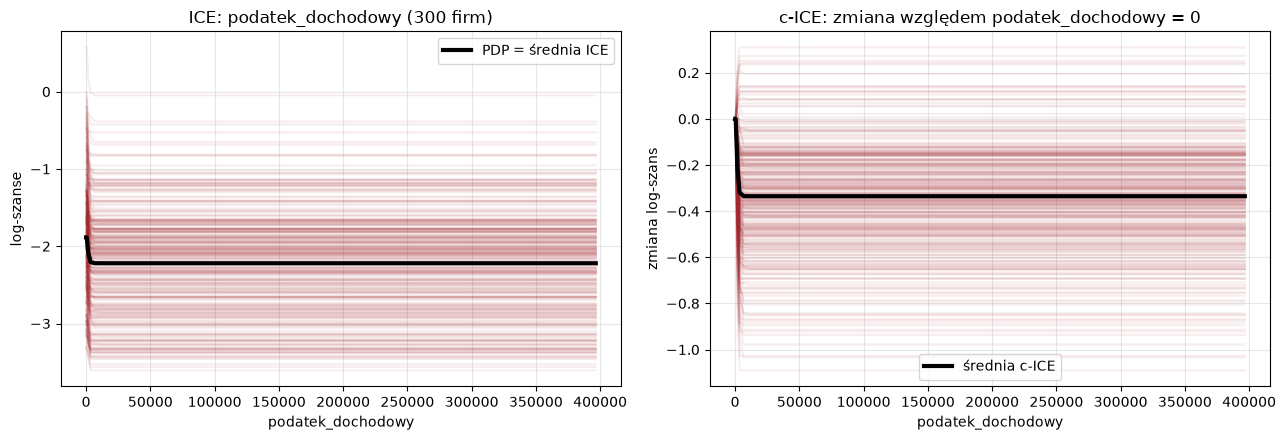

Zmiana podatek_dochodowy z 0 do 3.97e+05: średnio -0.335 log-szans; 10% firm: < -0.639, 10% firm: > -0.059
   wielkość = mikro    : średni efekt -0.425 (n = 174)
   wielkość = mała     : średni efekt -0.328 (n = 100)
   wielkość = pozostałe: średni efekt -0.290 (n = 325)


In [37]:
c_ice = CECHY_PDP[0]
S_ICE = siatka_kwantyli(c_ice, n=20)
ICE_M = ice(f_bb, XS, c_ice, S_ICE)
C_ICE = ICE_M - ICE_M[:, [0]]                                 # c-ICE: punkt odniesienia = najniższa wartość z siatki
pokaz = np.random.default_rng(RNG_SEED).choice(len(XS), 300, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(S_ICE, ICE_M[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[0].plot(S_ICE, ICE_M.mean(axis=0), color="black", lw=3, label="PDP = średnia ICE")
axes[0].set_title(f"ICE: {c_ice} (300 firm)"); axes[0].set_ylabel("log-szanse")
axes[1].plot(S_ICE, C_ICE[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[1].plot(S_ICE, C_ICE.mean(axis=0), color="black", lw=3, label="średnia c-ICE")
axes[1].set_title(f"c-ICE: zmiana względem {c_ice} = {S_ICE[0]:.3g}"); axes[1].set_ylabel("zmiana log-szans")
for ax in axes:
    ax.set_xlabel(c_ice); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/ice.png", dpi=120); plt.show()
EFEKT = C_ICE[:, -1]
print(f"Zmiana {c_ice} z {S_ICE[0]:.3g} do {S_ICE[-1]:.3g}: średnio {EFEKT.mean():+.3f} log-szans; "
      f"10% firm: < {np.percentile(EFEKT, 10):+.3f}, 10% firm: > {np.percentile(EFEKT, 90):+.3f}")
for nazwa, maska in [("mikro", XS["wielkosc"] == "mikro"), ("mała", XS["wielkosc"] == "mała"), ("pozostałe", XS["wielkosc"] == "pozostałe")]:
    print(f"   wielkość = {nazwa:9s}: średni efekt {EFEKT[maska.to_numpy()].mean():+.3f} (n = {maska.sum()})")

**Wnioski:** c-ICE pokazuje, że efekt podatku dochodowego (zysku) nie jest jednakowy: dla 10% firm zmiana log-szans jest słabsza
niż -0,06, dla 10% silniejsza niż -0,64. Najsilniej reagują firmy mikro - przy tej samej kwocie podatku zmienia się dla nich
bardziej obraz rentowności. Karta (jeden współczynnik na cechę) tej interakcji z wielkością nie ma.

### 8.2 PDP a ALE przy skorelowanych cechach

PDP podstawia wartość cechy wszystkim firmom, także tam, gdzie takich kombinacji nie ma w danych (cechy są silnie
skorelowane - 3.3). ALE liczy efekty lokalnie, w obrębie przedziałów cechy. Duża różnica PDP - ALE ostrzega, że PDP
ekstrapoluje.

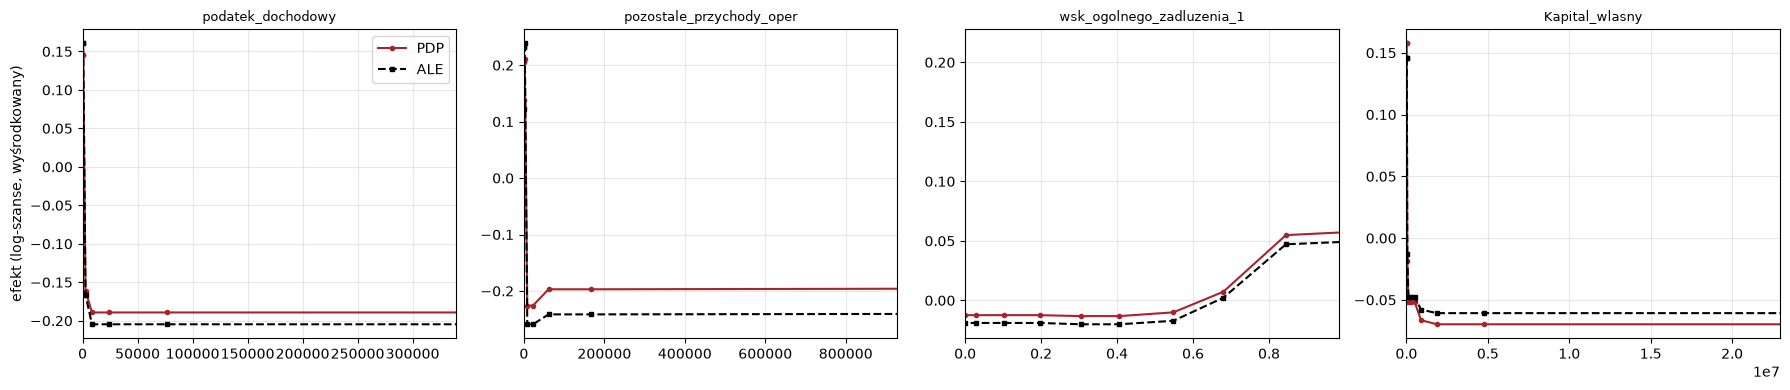

,zakres ALE,maks. |PDP - ALE|,maks. |ρ| z inną cechą,różnica / zakres
podatek_dochodowy,0.365,0.015,0.714,0.042
pozostale_przychody_oper,0.498,0.044,0.740,0.089
wsk_ogolnego_zadluzenia_1,0.067,0.008,0.996,0.115
Kapital_wlasny,0.206,0.012,0.907,0.058


In [38]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4)); roznice = {}
for ax, c in zip(axes, CECHY_PDP):
    gr, a, _ = ale(f_bb, XS, c, K=10)
    p = pdp_wysrodkowane(f_bb, XS, c, gr)
    ax.plot(gr, p, "o-", ms=3, color=KOL["black-box"], label="PDP"); ax.plot(gr, a, "s--", ms=3, color="black", label="ALE")
    ax.set_xlim(np.nanpercentile(XS[c], [2, 98])); ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
    w = (gr >= np.nanpercentile(XS[c], 2)) & (gr <= np.nanpercentile(XS[c], 98))
    roznice[c] = {"zakres ALE": np.ptp(a[w]), "maks. |PDP - ALE|": np.abs(p - a)[w].max(),
                  "maks. |ρ| z inną cechą": kor_tr.loc[c].drop(c).abs().max() if c in kor_tr else np.nan}
axes[0].set_ylabel("efekt (log-szanse, wyśrodkowany)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp_ale.png", dpi=120); plt.show()
display(pd.DataFrame(roznice).T.assign(**{"różnica / zakres": lambda t: t["maks. |PDP - ALE|"] / t["zakres ALE"]}).round(3))

**Wnioski:** różnica PDP - ALE to 4-12% zakresu efektu, mimo że cechy mają bardzo skorelowane odpowiedniki (dla zadłużenia ρ = 0,996).
PDP nie wprowadza tu w błąd; największa różnica dotyczy zadłużenia, gdzie PDP ocenia też kombinacje cech niespotykane w danych.
Przy tak silnych korelacjach w raporcie opieramy się na ALE.

### 8.3 Monotoniczność względem intuicji ekonomicznej

Oczekiwany kierunek zapisujemy **przed** analizą wyników, z wiedzy o finansach firmy: wyższe zadłużenie → wyższe ryzyko,
wyższa rentowność, zysk, kapitał własny i podatek (proxy zysku) → niższe ryzyko. Tabela naruszeń z Lab 5:
jaka część zmienności PDP black-boxa idzie w kierunku przeciwnym do oczekiwanego.

In [39]:
OCZEKIWANY = {"podatek_dochodowy": -1, "Kapital_wlasny": -1, "wsk_ogolnego_zadluzenia_1": +1, "wsk_zysk_zobowiazania": -1,
              "wsk_stopa_zysku_sprzedaz": -1, "wsk_sytuacji_fin": -1, "pozostale_przychody_oper": -1}
OCZEKIWANY.update({c: int(np.sign(spearmanr(df_train[c], df_train[TARGET], nan_policy="omit")[0])) for c in TOP_BB[:6] if c not in OCZEKIWANY and c in num_cols})

def naruszenia(f, kierunki):                                  # z Lab 5
    w = {}
    for c, kier in kierunki.items():
        s = siatka_kwantyli(c)
        d = np.diff(ice(f, XS, c, s).mean(axis=0)) * kier
        w[c] = {"oczekiwany kierunek": "+" if kier > 0 else "-", "zmienność PDP": np.abs(d).sum(),
                "suma naruszeń": float(np.abs(d[d < 0].sum())), "maks. naruszenie": float(np.abs(min(d.min(), 0.0)))}
    t = pd.DataFrame(w).T
    t["udział naruszeń"] = t["suma naruszeń"].astype(float) / t["zmienność PDP"].astype(float)
    return t

tab_mono = naruszenia(f_bb, OCZEKIWANY)
tab_mono["zgodny znak β w karcie"] = [("tak" if c in CECHY_L else "-") for c in tab_mono.index]
display(tab_mono.round(3))

,oczekiwany kierunek,zmienność PDP,suma naruszeń,maks. naruszenie,udział naruszeń,zgodny znak β w karcie
podatek_dochodowy,-,0.335225,0.0,0.0,0.000,tak
Kapital_wlasny,-,0.233649,0.003162,0.003162,0.014,tak
wsk_ogolnego_zadluzenia_1,+,0.229924,0.000799,0.000799,0.003,tak
wsk_zysk_zobowiazania,-,0.027097,0.0,0.0,0.000,tak
wsk_stopa_zysku_sprzedaz,-,0.152411,0.005847,0.005847,0.038,tak
wsk_sytuacji_fin,-,0.089197,0.025714,0.025714,0.288,tak
pozostale_przychody_oper,-,0.552427,0.114857,0.066734,0.208,tak
wsk_ROE_brutto,-,0.532474,0.033099,0.033099,0.062,-
wsk_kapital_do_aktywa,-,0.253609,0.003215,0.003215,0.013,-
Aktywa,-,0.10543,0.004774,0.002853,0.045,-


**Wnioski:** dla podatku, kapitału, zadłużenia i rentowności sprzedaży naruszenia monotoniczności są pomijalne (< 4% zmienności PDP).
Większe naruszenia mają `wsk_sytuacji_fin` (29%) i `pozostale_przychody_oper` (21%), ale ich bezwzględna wielkość jest mała
(maks. 0,03-0,07 log-szans) i dotyczy obszarów o małej liczbie firm. Nie wprowadzamy ograniczeń monotonicznych w XGBoost - w karcie
monotoniczność jest zagwarantowana binningiem; w modelu wdrożeniowym black-boxa warto ją wymusić dla tych dwóch cech (`monotone_constraints`).

## 9. Wyjaśnienia lokalne: studia przypadków

Cztery firmy z testu, wybrane według PD black-boxa (przed kalibracją PD jest bliskie częstości w próbie, CITL ≈ 0 - 6.1):
1. **najwyższe PD**, 2. **graniczna** - PD najbliżej progu z funkcji zysku p* = MARGIN / (MARGIN + LGD) = 18,2% (12.2),
3. **typowa przyjęta** - PD najbliżej mediany, 4. **największa niezgodność modeli** - największa różnica rang PD karty i black-boxa.

Dla każdej: wykres kaskadowy SHAP black-boxa, kody przyczyn (top 3), dekompozycja punktów karty i (9.2) LIME.

,wiersz testu,PD black-box,PD karta,punkty karty,default (fakt)
najwyższe PD,102.0,0.639,0.511,485.855,0.0
graniczna (PD ≈ p*),320.0,0.182,0.149,537.398,0.0
typowa przyjęta,48.0,0.114,0.086,555.302,1.0
niezgodność modeli,571.0,0.177,0.048,573.331,0.0



=== najwyższe PD: wiersz 102, PD black-box 63.9%, PD karta 51.1%, default = 0 ===


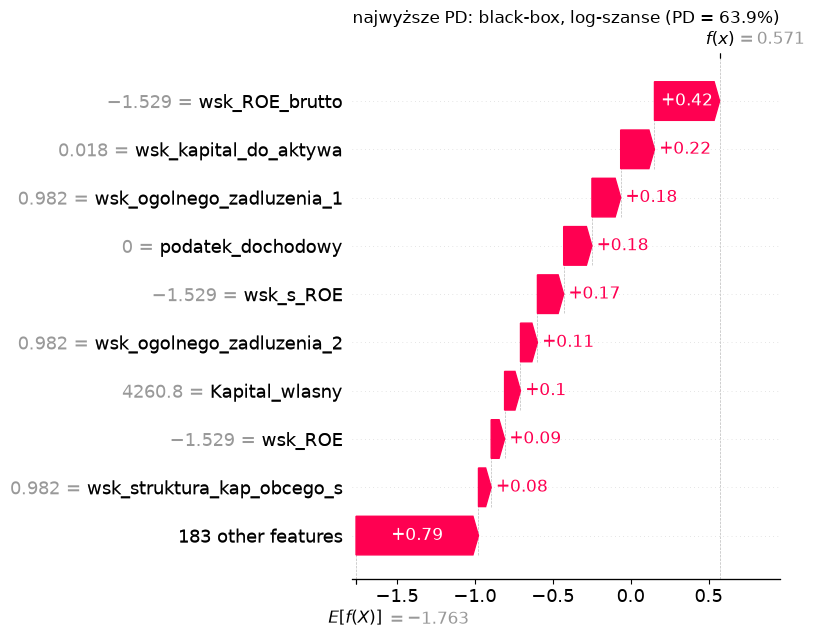

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_ROE_brutto,-1.529365,0.418,1.52,podnosi ryzyko
wsk_kapital_do_aktywa,0.018305,0.217,1.24,podnosi ryzyko
wsk_ogolnego_zadluzenia_1,0.981695,0.184,1.20,podnosi ryzyko
podatek_dochodowy,0.000000,0.181,1.20,podnosi ryzyko
wsk_s_ROE,-1.529365,0.169,1.18,podnosi ryzyko
wsk_ogolnego_zadluzenia_2,0.981695,0.109,1.11,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_ogolnego_zadluzenia_1,0.981695,46.8,37.4,1.111
podatek_dochodowy,0.0,71.4,24.3,0.256
Kapital_wlasny,4260.8,69.6,17.2,0.292
pozostale_przychody_oper,0.0,71.3,13.0,0.223
wsk_stopa_zysku_sprzedaz,-0.019691,75.5,9.9,0.080
wsk_zysk_zobowiazania,-0.028517,74.8,6.4,0.087
wsk_sytuacji_fin,0.542254,76.4,2.8,0.023



=== graniczna (PD ≈ p*): wiersz 320, PD black-box 18.2%, PD karta 14.9%, default = 0 ===


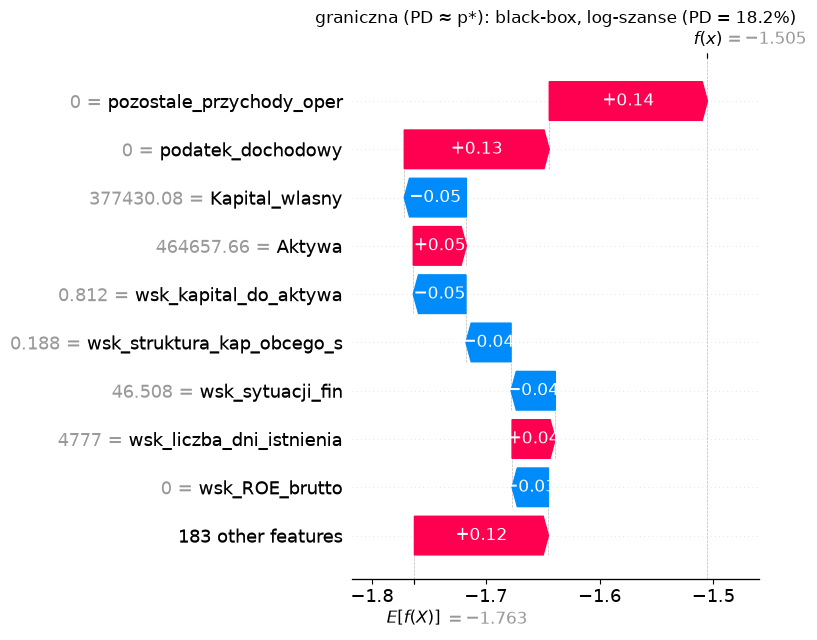

,wartość,SHAP,mnożnik szans e^φ,kierunek
pozostale_przychody_oper,0.000000,0.139,1.15,podnosi ryzyko
podatek_dochodowy,0.000000,0.127,1.14,podnosi ryzyko
Kapital_wlasny,377430.080000,-0.055,0.95,obniża ryzyko
Aktywa,464657.660000,0.047,1.05,podnosi ryzyko
wsk_kapital_do_aktywa,0.812276,-0.046,0.95,obniża ryzyko
wsk_struktura_kap_obcego_s,0.187724,-0.040,0.96,obniża ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
podatek_dochodowy,0.0,71.4,24.3,0.256
pozostale_przychody_oper,0.0,71.3,13.0,0.223
wsk_stopa_zysku_sprzedaz,0.0,75.5,9.9,0.080
Kapital_wlasny,377430.08,80.0,6.9,-0.067
wsk_zysk_zobowiazania,0.0,75.8,5.4,0.053
wsk_ogolnego_zadluzenia_1,0.187724,84.2,0.0,-0.184
wsk_sytuacji_fin,46.508247,79.3,0.0,-0.075



=== typowa przyjęta: wiersz 48, PD black-box 11.4%, PD karta 8.6%, default = 1 ===


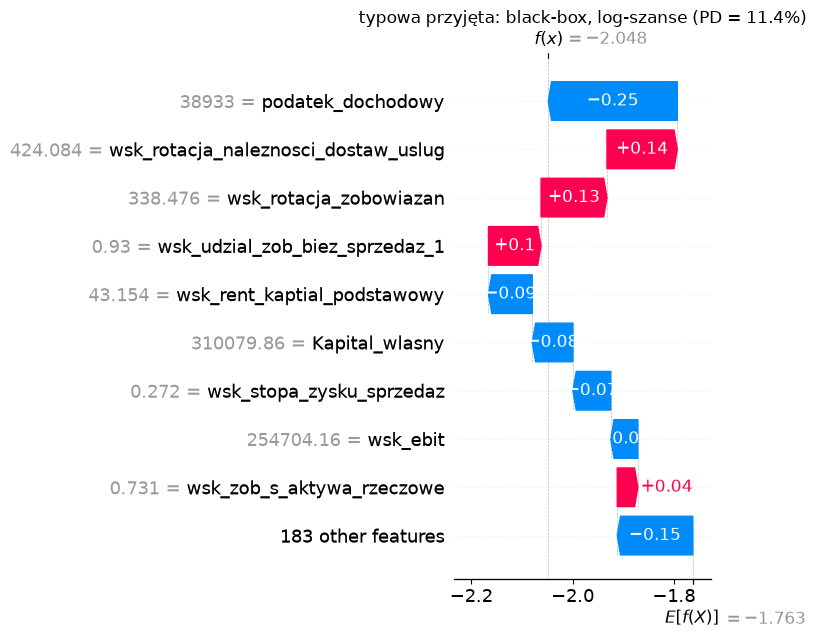

,wartość,SHAP,mnożnik szans e^φ,kierunek
podatek_dochodowy,38933.000000,-0.255,0.78,obniża ryzyko
wsk_rotacja_naleznosci_dostaw_uslug,424.084098,0.139,1.15,podnosi ryzyko
wsk_rotacja_zobowiazan,338.476084,0.130,1.14,podnosi ryzyko
wsk_udzial_zob_biez_sprzedaz_1,0.929879,0.104,1.11,podnosi ryzyko
wsk_rent_kaptial_podstawowy,43.153508,-0.086,0.92,obniża ryzyko
Kapital_wlasny,310079.860000,-0.080,0.92,obniża ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_ogolnego_zadluzenia_1,0.743028,68.6,15.6,0.356
pozostale_przychody_oper,0.0,71.3,13.0,0.223
Kapital_wlasny,310079.86,80.0,6.9,-0.067
podatek_dochodowy,38933.0,89.6,6.1,-0.373
wsk_zysk_zobowiazania,0.247537,81.2,0.0,-0.135
wsk_stopa_zysku_sprzedaz,0.271713,85.4,0.0,-0.264
wsk_sytuacji_fin,24.086792,79.3,0.0,-0.075



=== niezgodność modeli: wiersz 571, PD black-box 17.7%, PD karta 4.8%, default = 0 ===


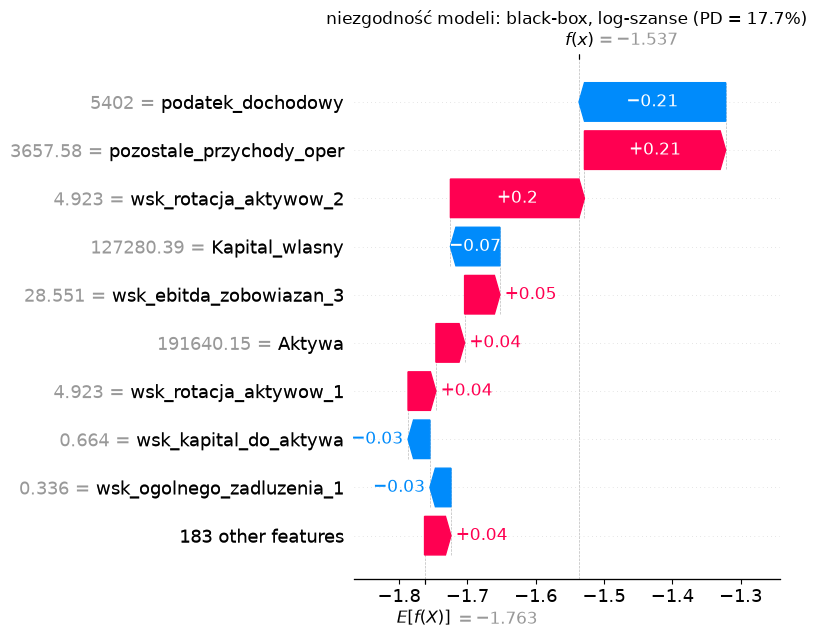

,wartość,SHAP,mnożnik szans e^φ,kierunek
podatek_dochodowy,5402.000000,-0.215,0.81,obniża ryzyko
pozostale_przychody_oper,3657.580000,0.207,1.23,podnosi ryzyko
wsk_rotacja_aktywow_2,4.922917,0.196,1.22,podnosi ryzyko
Kapital_wlasny,127280.390000,-0.072,0.93,obniża ryzyko
wsk_ebitda_zobowiazan_3,28.550672,0.052,1.05,podnosi ryzyko
Aktywa,191640.150000,0.042,1.04,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
podatek_dochodowy,5402.0,86.4,9.3,-0.263
Kapital_wlasny,127280.39,80.0,6.9,-0.067
wsk_zysk_zobowiazania,0.0,75.8,5.4,0.053
pozostale_przychody_oper,3657.58,82.4,2.0,-0.160
wsk_ogolnego_zadluzenia_1,0.335837,84.2,0.0,-0.184
wsk_stopa_zysku_sprzedaz,0.052637,85.4,0.0,-0.264
wsk_sytuacji_fin,222.705245,79.3,0.0,-0.075


In [40]:
p_star = MARGIN / (MARGIN + LGD)
pd_bb_te, pd_lg_te = P["black-box"]["test"], P["logit"]["test"]
rangi_bb, rangi_lg = pd.Series(pd_bb_te).rank(pct=True), pd.Series(pd_lg_te).rank(pct=True)
PRZYPADKI = {"najwyższe PD": int(np.argmax(pd_bb_te)),
             "graniczna (PD ≈ p*)": int(np.argmin(np.abs(pd_bb_te - p_star))),
             "typowa przyjęta": int(np.argmin(np.abs(pd_bb_te - np.median(pd_bb_te)))),
             "niezgodność modeli": int((rangi_bb - rangi_lg).abs().idxmax())}
display(pd.DataFrame({k: {"wiersz testu": i, "PD black-box": pd_bb_te[i], "PD karta": pd_lg_te[i],
                          "punkty karty": wynik_model[i], "default (fakt)": y_te[i]} for k, i in PRZYPADKI.items()}).T.round(3))

def powody(i, n=10):
    s = pd.Series(PHI_BB[i], index=FEATURES)
    s = s.reindex(s.abs().sort_values(ascending=False).index)[:n]
    return pd.DataFrame({"wartość": [XS.loc[i, c] for c in s.index], "SHAP": s.round(3).to_numpy(),
                         "mnożnik szans e^φ": np.exp(s).round(2).to_numpy(),
                         "kierunek": np.where(s > 0, "podnosi ryzyko", "obniża ryzyko")}, index=s.index)

def punkty_vs_max(i):
    pk = punkty_firmy(X_te.iloc[[i]]).iloc[0]
    maks = karta_pkt.groupby("cecha")["punkty"].max()
    return pd.DataFrame({"wartość": X_te.iloc[i][CECHY_L], "punkty": pk.round(1), "utracone vs maksimum": (maks[CECHY_L] - pk).round(1),
                         "SHAP karty": PHI_LOG.iloc[i].round(3)}).sort_values("utracone vs maksimum", ascending=False)

for nazwa, i in PRZYPADKI.items():
    print(f"\n=== {nazwa}: wiersz {i}, PD black-box {pd_bb_te[i]:.1%}, PD karta {pd_lg_te[i]:.1%}, default = {y_te[i]} ===")
    shap.plots.waterfall(shap.Explanation(values=PHI_BB[i], base_values=BAZA_BB, data=XS.iloc[i].to_numpy(dtype=object),
                                          feature_names=FEATURES), max_display=10, show=False)
    plt.title(f"{nazwa}: black-box, log-szanse (PD = {pd_bb_te[i]:.1%})"); plt.tight_layout()
    plt.savefig(f"wykresy/waterfall_{list(PRZYPADKI).index(nazwa) + 1}.png", dpi=110, bbox_inches="tight"); plt.show()
    display(powody(i, 6))
    display(punkty_vs_max(i))

**Wnioski z przypadków:**
- **Najwyższe PD** (64%): o ryzyku decydują bardzo mały kapitał własny (`wsk_kapital_do_aktywa`, `wsk_ROE_brutto`) i zadłużenie
  ogólne 98% aktywów, przy braku zysku. Karta też ocenia ją jako jedną z najgorszych (PD 51% przed korektą do 4%, 486 pkt). Firma nie zbankrutowała - PD 64% oznacza wysokie ryzyko, nie pewność.
- **Graniczna** (PD 18,2% ≈ p*): ryzyko podnoszą brak pozostałych przychodów operacyjnych i brak zysku (zerowy podatek), a obniża
  wysoki kapitał własny (81% aktywów); to firma, dla której niewielka poprawa wyników zmienia decyzję (9.3 i 13).
- **Typowa przyjęta** (PD 11%): wkłady są małe i się znoszą. Firma jednak zbankrutowała - przypomnienie, że średnie PD ~11% oznacza
  ok. 1 default na 9 takich firm.
- **Niezgodność modeli**: karta daje 4,8%, black-box 17,7%. Najważniejsze cechy SHAP to te same pozycje co w karcie (podatek,
  pozostałe przychody), ale black-box ocenia je inaczej - nieliniowo i w połączeniu z innymi wskaźnikami, których karta nie ma.
  Takie firmy (duża różnica ocen dwóch modeli) warto kierować do analityka.

### 9.1 LIME (kilka obserwacji)

`LimeTabularExplainer` dla black-boxa, z próbkowaniem wokół wyjaśnianej firmy (`sample_around_instance=True`) i bez
dyskretyzacji - zastępczy model liniowy w standaryzowanych cechach. Dwie decyzje wynikają z danych:
- braki uzupełniamy medianą z train (LIME nie obsługuje braków; black-box dostaje te same uzupełnione wartości),
- cechy przycinamy do 1-99 percentyla z train - przy skrajnych ogonach odchylenie standardowe jest ogromne i próbki
  LIME leżałyby daleko poza danymi.

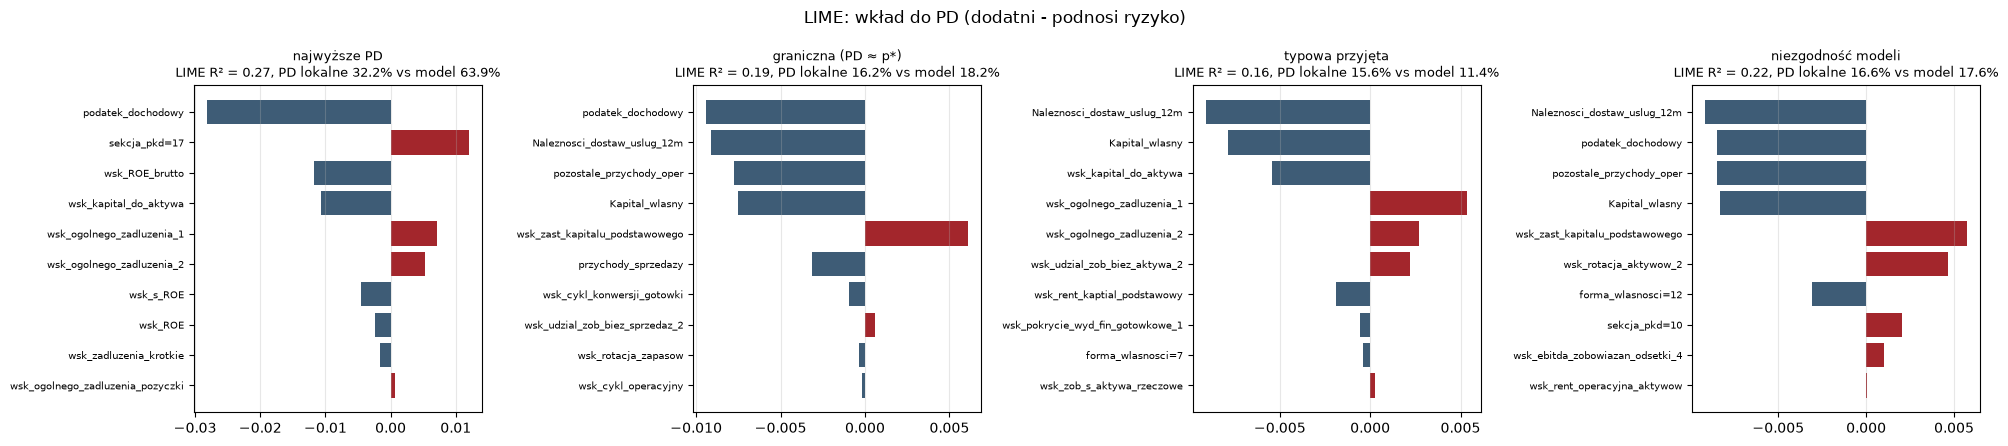

In [41]:
from lime.lime_tabular import LimeTabularExplainer

granice_lime = X_tr[num_cols].quantile([0.01, 0.99])
mediany_lime = X_tr[num_cols].median()
kat_wartosci = {c: sorted(X_tr[c].unique()) for c in cat_cols}

def do_lime(Xw):
    # DataFrame -> macierz LIME: braki = mediana, przycięcie 1-99%, kategorie jako kody całkowite
    A = Xw[num_cols].fillna(mediany_lime).clip(granice_lime.loc[0.01], granice_lime.loc[0.99], axis=1)
    B = pd.DataFrame({c: Xw[c].map({v: k for k, v in enumerate(kat_wartosci[c])}).fillna(0) for c in cat_cols}, index=Xw.index)
    return pd.concat([A, B], axis=1)[FEATURES].to_numpy(dtype=float)

def z_lime(M):
    # macierz LIME -> DataFrame dla black-boxa
    D = pd.DataFrame(M, columns=FEATURES)
    for c in cat_cols:
        D[c] = [kat_wartosci[c][int(round(v))] for v in D[c]]
    return D

def f_lime(M):
    return black_box.predict_proba(z_lime(M))

L_TR, L_TE = do_lime(X_tr), do_lime(X_te)
idx_kat = [FEATURES.index(c) for c in cat_cols]

def lime_explainer(seed, kernel_width=None):
    return LimeTabularExplainer(L_TR, feature_names=FEATURES, categorical_features=idx_kat, class_names=["brak", "default"],
                                discretize_continuous=False, sample_around_instance=True, kernel_width=kernel_width, random_state=seed)

def lime_wyjasnij(i, seed=RNG_SEED, num_samples=5000, kernel_width=None, num_features=10):
    return lime_explainer(seed, kernel_width).explain_instance(L_TE[i], f_lime, num_features=num_features, num_samples=num_samples)

LIME = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (nazwa, i) in zip(axes, PRZYPADKI.items()):
    e = lime_wyjasnij(i); LIME[nazwa] = e
    lst = sorted(e.as_list(), key=lambda t: abs(t[1]))
    ax.barh([a for a, _ in lst], [b for _, b in lst], color=[KOL["test"] if b > 0 else KOL["train"] for _, b in lst])
    ax.set_title(f"{nazwa}\nLIME R² = {e.score:.2f}, PD lokalne {e.local_pred[0]:.1%} vs model {f_lime(L_TE[[i]])[0, 1]:.1%}", fontsize=9)
    ax.tick_params(axis="y", labelsize=7); ax.grid(axis="x", alpha=0.3)
plt.suptitle("LIME: wkład do PD (dodatni - podnosi ryzyko)"); plt.tight_layout(); plt.savefig("wykresy/lime_przypadki.png", dpi=110); plt.show()

### 9.2 Zgodność wyjaśnień lokalnych: SHAP, LIME i karta

Jaccard top-5 cech (SHAP vs LIME dla black-boxa) i zgodność kierunku wpływu dla cech wspólnych.

In [42]:
def top_k(seria, k=5):
    return set(seria.abs().sort_values(ascending=False).index[:k])

wiersze = []
for nazwa, i in PRZYPADKI.items():
    s_shap = pd.Series(PHI_BB[i], index=FEATURES)
    s_lime = pd.Series({FEATURES[j]: w for j, w in LIME[nazwa].local_exp[1]})
    wspolne = top_k(s_shap, 10) & set(s_lime.index)
    wiersze.append({"przypadek": nazwa, "Jaccard top-5 SHAP vs LIME": len(top_k(s_shap) & top_k(s_lime)) / len(top_k(s_shap) | top_k(s_lime)),
                    "wspólne cechy (top-10 SHAP ∩ LIME)": len(wspolne),
                    "zgodny kierunek wśród wspólnych": f"{sum(np.sign(s_shap[c]) == np.sign(s_lime[c]) for c in wspolne)} / {len(wspolne)}",
                    "top-3 SHAP": ", ".join(s_shap.abs().sort_values(ascending=False).index[:3]),
                    "top-3 LIME": ", ".join(s_lime.abs().sort_values(ascending=False).index[:3]),
                    "top-3 karta (utracone pkt)": ", ".join(punkty_vs_max(i).index[:3])})
display(pd.DataFrame(wiersze).set_index("przypadek"))

,Jaccard top-5 SHAP vs LIME,wspólne cechy (top-10 SHAP ∩ LIME),zgodny kierunek wśród wspólnych,top-3 SHAP,top-3 LIME,top-3 karta (utracone pkt)
przypadek,,,,,,
najwyższe PD,0.666667,7,2 / 7,"wsk_ROE_brutto, wsk_kapital_do_aktywa, wsk_ogo...","podatek_dochodowy, sekcja_pkd, wsk_ROE_brutto","wsk_ogolnego_zadluzenia_1, podatek_dochodowy, ..."
graniczna (PD ≈ p*),0.428571,3,1 / 3,"pozostale_przychody_oper, podatek_dochodowy, K...","podatek_dochodowy, Naleznosci_dostaw_uslug_12m...","podatek_dochodowy, pozostale_przychody_oper, w..."
typowa przyjęta,0.000000,3,3 / 3,"podatek_dochodowy, wsk_rotacja_naleznosci_dost...","Naleznosci_dostaw_uslug_12m, Kapital_wlasny, w...","wsk_ogolnego_zadluzenia_1, pozostale_przychody..."
niezgodność modeli,0.428571,4,3 / 4,"podatek_dochodowy, pozostale_przychody_oper, w...","Naleznosci_dostaw_uslug_12m, podatek_dochodowy...","podatek_dochodowy, Kapital_wlasny, wsk_zysk_zo..."


**Wnioski:** LIME i SHAP wskazują często różne cechy (Jaccard top-5 od 0 do 0,67), a dla firmy z najwyższym PD kierunek zgadza się
tylko w 2 z 7 wspólnych cech. Przyczyny: (a) LIME przybliża model liniowo w otoczeniu 192-wymiarowym, a XGBoost jest schodkowy;
(b) LIME mierzy wpływ zmiany cechy w otoczeniu firmy, SHAP - wkład względem średniej firmy; (c) przy skorelowanych cechach obie metody
mogą przypisać wkład różnym „bliźniakom”. Wierność i stabilność obu metod mierzymy w sekcji 10.

### 9.3 „What-if”: jak zmienia się PD przy zmianie jednej cechy

Dla firmy granicznej zmieniamy kolejno każdą z 4 najważniejszych cech (według jej SHAP) na wartości z siatki kwantyli
train, pozostałe cechy bez zmian (to ICE pojedynczej firmy). Linia przerywana - próg p*.

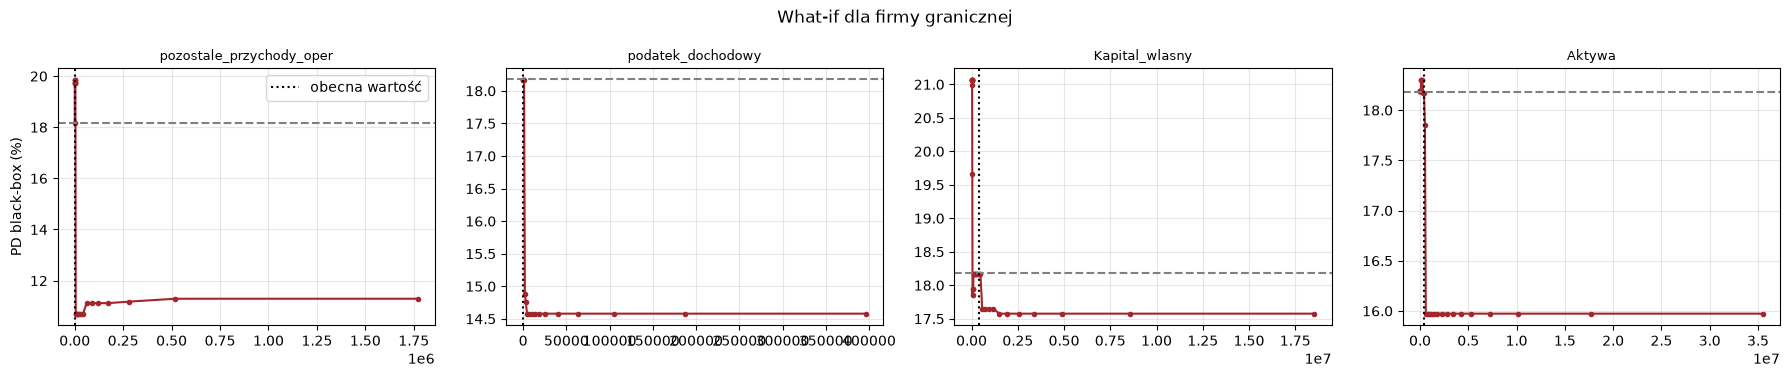

In [43]:
i_gr = PRZYPADKI["graniczna (PD ≈ p*)"]
cechy_wi = [c for c in powody(i_gr, 10).index if c in num_cols][:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cechy_wi):
    s = siatka_kwantyli(c, n=30)
    p_wi = black_box.predict_proba(pd.concat([XS.iloc[[i_gr]].assign(**{c: v}) for v in s]))[:, 1]
    ax.plot(s, 100 * p_wi, "o-", ms=3, color=KOL["black-box"]); ax.axhline(100 * p_star, ls="--", color="gray")
    ax.axvline(XS.loc[i_gr, c], ls=":", color="black", label="obecna wartość"); ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PD black-box (%)"); axes[0].legend()
plt.suptitle("What-if dla firmy granicznej"); plt.tight_layout(); plt.savefig("wykresy/what_if.png", dpi=110); plt.show()

**Wnioski:** pojedyncza zmiana jednej cechy (przy reszcie bez zmian) przesuwa PD tej firmy o kilka punktów procentowych - zwiększenie
pozostałych przychodów operacyjnych lub kapitału obniża PD poniżej progu p*. To jednak analiza modelu, nie świata: w rzeczywistości
zmiana jednej pozycji sprawozdania zmienia też powiązane wskaźniki (analiza z zależnościami - sekcja 13).

## 10. Wierność i stabilność wyjaśnień

### 10.1 Wierność SHAP

SHAP jest z konstrukcji **lokalnie dokładny**: baza + Σφ = f(x) (sprawdzone w 7.1 - błąd rzędu 1e-6). Wierność w sensie
„czy wkłady oddają zachowanie modelu” sprawdzamy testem usuwania: zastępujemy k najważniejszych (według SHAP) cech firmy
wartościami z tła (mediana train) i mierzymy zmianę log-szans; porównujemy z zastąpieniem k losowych cech.

In [44]:
mediany_bb = X_tr[num_cols].median()
def usun_cechy(i, cechy):
    x = XS.iloc[[i]].copy()
    for c in cechy:
        x[c] = mediany_bb[c] if c in num_cols else X_tr[c].mode()[0]
    return f_bb(x)[0]

rng_u = np.random.default_rng(RNG_SEED)
proba_u = rng_u.choice(len(XS), 100, replace=False)
wiersze = []
for k in [1, 3, 5, 10]:
    d_shap, d_los = [], []
    for i in proba_u:
        f0 = f_bb(XS.iloc[[i]])[0]
        top = pd.Series(np.abs(PHI_BB[i]), index=FEATURES).sort_values(ascending=False).index[:k]
        d_shap.append(abs(usun_cechy(i, top) - f0))
        d_los.append(abs(usun_cechy(i, rng_u.choice(FEATURES, k, replace=False)) - f0))
    wiersze.append({"k usuniętych cech": k, "średnia |zmiana log-szans|: top-k SHAP": np.mean(d_shap),
                    "średnia |zmiana log-szans|: k losowych": np.mean(d_los)})
display(pd.DataFrame(wiersze).set_index("k usuniętych cech").round(3))

,średnia |zmiana log-szans|: top-k SHAP,średnia |zmiana log-szans|: k losowych
k usuniętych cech,,
1,0.304,0.006
3,0.451,0.023
5,0.479,0.040
10,0.582,0.080


**Wnioski:** zastąpienie jednej najważniejszej według SHAP cechy wartością typową zmienia log-szanse średnio o 0,30, a jednej
losowej - o 0,006 (50 razy mniej). Ranking SHAP wiernie wskazuje cechy, od których zależy prognoza modelu.

### 10.2 Wierność LIME: lokalne R² i błąd aproksymacji

Dla każdej firmy losujemy **nowe** otoczenie tak jak LIME (rozkład normalny wokół firmy w skali cech LIME) i porównujemy
PD black-boxa z prognozą zastępczego modelu liniowego: ważone R² (wagi jądra LIME) i średni błąd bezwzględny (MAE, w pp PD).
Raportujemy też R² zwracane przez LIME (na jego własnych próbkach) i różnicę PD w samym punkcie. Sprawdzamy wpływ
szerokości jądra: węższe jądro - bardziej lokalne, ale mniej próbek o istotnej wadze.

In [45]:
def wiernosc_lime(i, e, explainer, n=2000, seed=0):
    rng_f = np.random.default_rng(seed)
    x = L_TE[i]; skala, srednia = explainer.scaler.scale_, explainer.scaler.mean_
    Z = x + rng_f.normal(size=(n, len(x))) * skala
    for j in idx_kat:                                             # kategorie: losowanie według częstości z train (jak w LIME)
        wart, licz = np.unique(L_TR[:, j], return_counts=True)
        Z[:, j] = rng_f.choice(wart, n, p=licz / licz.sum())
    Zs = (Z - srednia) / skala
    for j in idx_kat:
        Zs[:, j] = (Z[:, j] == x[j]).astype(float)
    xs = (x - srednia) / skala
    for j in idx_kat:
        xs[j] = 1.0
    odl = np.sqrt(((Zs - xs) ** 2).sum(axis=1))
    szer = explainer.kernel_width if hasattr(explainer, "kernel_width") else np.sqrt(len(x)) * 0.75
    w = np.sqrt(np.exp(-(odl ** 2) / szer ** 2))
    zast = e.intercept[1] + sum(b * Zs[:, j] for j, b in e.local_exp[1])
    prawdz = f_lime(Z)[:, 1]
    r2 = 1 - np.sum(w * (prawdz - zast) ** 2) / np.sum(w * (prawdz - np.average(prawdz, weights=w)) ** 2)
    return {"R² LIME (własne próbki)": e.score, "R² ważone (nowe otoczenie)": r2, "MAE (pp PD)": 100 * np.mean(np.abs(prawdz - zast)),
            "|PD lokalne - PD modelu| w punkcie (pp)": 100 * abs(e.local_pred[0] - f_lime(L_TE[[i]])[0, 1])}

SZER_DOM = np.sqrt(len(FEATURES)) * 0.75
proba_l = np.random.default_rng(1).choice(len(XS), 20, replace=False)
wiersze = []
for mn in [0.25, 0.5, 1.0, 2.0]:
    for i in proba_l:
        ex = lime_explainer(RNG_SEED, kernel_width=SZER_DOM * mn); ex.kernel_width = SZER_DOM * mn
        e = ex.explain_instance(L_TE[i], f_lime, num_features=10, num_samples=5000)
        wiersze.append({"szerokość jądra": f"{mn} × domyślna", **wiernosc_lime(i, e, ex)})
tab_wiern = pd.DataFrame(wiersze).groupby("szerokość jądra").agg(["median", "min"])
display(tab_wiern.round(3))

R² LIME (własne próbki)        R² ważone (nowe otoczenie)  \
                                 median    min                     median   
szerokość jądra                                                             
0.25 × domyślna                   0.023  0.003                     -4.804   
0.5 × domyślna                    0.213  0.008                      0.224   
1.0 × domyślna                    0.216  0.003                      0.228   
2.0 × domyślna                    0.216  0.026                      0.228   

                        MAE (pp PD)         \
                    min      median    min   
szerokość jądra                              
0.25 × domyślna -12.565       8.378  3.014   
0.5 × domyślna   -0.003       2.595  1.770   
1.0 × domyślna   -0.001       2.588  1.760   
2.0 × domyślna    0.011       2.591  1.759   

                |PD lokalne - PD modelu| w punkcie (pp)         
                                                 median    min  
szerokość jądra                                                 
0.25 × domyślna                                   0.073  0.002  
0.5 × domyślna                                    6.405  0.213  
1.0 × domyślna                                    8.225  0.191  
2.0 × domyślna                                    8.241  0.184

**Wnioski:**
- Przy domyślnym jądrze lokalne R² LIME wynosi ok. 0,22 (mediana), także na nowym otoczeniu - zastępczy model liniowy wyjaśnia
  tylko 1/5 zmienności PD black-boxa w otoczeniu firmy, a błąd średni to ok. 2,6 pp PD.
- PD zastępczego modelu w samym punkcie różni się od PD black-boxa średnio o ok. 8 pp - **wyjaśnienie LIME może być mylące
  dla konkretnej firmy**, zwłaszcza blisko progu decyzyjnego.
- Zwężenie jądra (0,25 × domyślna) poprawia zgodność w punkcie, ale zastępczy model uczy się na kilku próbkach o istotnej wadze i
  na nowym otoczeniu ma ujemne R² - kompromis lokalność / stabilność. Szersze jądro niczego nie poprawia.
- Przyczyna: model drzewiasty jest kawałkami stały, a otoczenie ma 192 wymiarów - liniowe przybliżenie jest z natury słabe.

### 10.3 Stabilność LIME: te same firmy, różne ziarna losowania

Dla każdego przypadku z sekcji 9: 10 uruchomień LIME z różnymi ziarnami, dla 1 000, 5 000 i 20 000 próbek.
Miary: średni Jaccard top-5 między parami uruchomień i średnia korelacja Spearmana wag (na sumie wybranych cech).
Model black-box jest za każdym razem ten sam - więc **zmienność wynika wyłącznie z metody wyjaśniającej** (losowanie próbek).

In [46]:
def stabilnosc_lime(i, num_samples, n_seed=10):
    wagi = []
    for s in range(n_seed):
        e = lime_wyjasnij(i, seed=s, num_samples=num_samples)
        wagi.append(pd.Series({FEATURES[j]: w for j, w in e.local_exp[1]}))
    jac, rho = [], []
    for a, b in itertools.combinations(range(n_seed), 2):
        ta, tb = top_k(wagi[a]), top_k(wagi[b]); jac.append(len(ta & tb) / len(ta | tb))
        u = wagi[a].index.union(wagi[b].index)
        rho.append(spearmanr(wagi[a].reindex(u).fillna(0), wagi[b].reindex(u).fillna(0))[0])
    return np.mean(jac), np.mean(rho)

wiersze = []
for nazwa, i in PRZYPADKI.items():
    for ns in [1000, 5000, 20000]:
        j_, r_ = stabilnosc_lime(i, ns)
        wiersze.append({"przypadek": nazwa, "liczba próbek": ns, "Jaccard top-5": j_, "Spearman wag": r_})
tab_stab_lime = pd.DataFrame(wiersze).pivot(index="przypadek", columns="liczba próbek")
display(tab_stab_lime.round(3))

Jaccard top-5               Spearman wag              
liczba próbek               1000   5000   20000        1000   5000   20000
przypadek                                                                 
graniczna (PD ≈ p*)         0.564  1.000  1.000        0.569  0.835  0.933
najwyższe PD                0.830  0.747  0.793        0.851  0.884  0.946
niezgodność modeli          0.482  0.874  1.000        0.438  0.826  0.900
typowa przyjęta             0.600  0.733  0.763        0.669  0.882  0.924

**Wnioski:** przy 1 000 próbek top-5 LIME zmienia się między ziarnami (Jaccard 0,48-0,83). Przy 5 000 i 20 000 próbek stabilność
rośnie (Jaccard 0,73-1,0, ρ wag 0,83-0,95). Ponieważ model się nie zmienia, **niestabilność pochodzi z metody** (losowanie otoczenia)
i maleje z liczbą próbek. Stabilność nie oznacza jednak wierności - stabilne wyjaśnienie może nadal słabo opisywać model (10.2).

### 10.4 Stabilność rankingów ważności (SHAP) przy zmianie danych uczących

TreeSHAP jest deterministyczny, więc tu źródłem zmienności jest **model**: uczymy black-box od nowa na każdym z 5 foldów
treningowych CV i liczymy globalny ranking średniego |SHAP| na tym samym zbiorze testowym. To samo dla karty (binning,
WoE i β od nowa). Miary: Spearman rang (wszystkie cechy) i Jaccard top-k między parami foldów.

In [47]:
rank_bb, rank_lg = [], []
for a, b in FOLDY:
    m = model_black_box(**PARAM_BB).fit(X_tr.iloc[a], y_tr[a])
    pre_f, clf_f = m.named_steps["pre"], m.named_steps["clf"]
    G_f = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in pre_f.get_feature_names_out()])
    rank_bb.append(pd.Series(np.abs(shap.TreeExplainer(clf_f)(pre_f.transform(X_te)).values @ G_f).mean(axis=0), index=FEATURES))
    mk = karta(CECHY_L).fit(X_tr.iloc[a][CECHY_L], y_tr[a])
    W = mk.named_steps["woe"].transform(X_te[CECHY_L]); Wt = mk.named_steps["woe"].transform(X_tr.iloc[a][CECHY_L]).mean()
    rank_lg.append(np.abs((W - Wt) * mk.named_steps["lr"].coef_.ravel()).mean())

def zgodnosc_rankingow(lista, k):
    jac, rho = [], []
    for s1, s2 in itertools.combinations(lista, 2):
        t1, t2 = set(s1.nlargest(k).index), set(s2.nlargest(k).index)
        jac.append(len(t1 & t2) / len(t1 | t2)); rho.append(spearmanr(s1, s2[s1.index])[0])
    return np.mean(jac), np.min(jac), np.mean(rho)

wiersze = []
for nazwa, lista, ks_ in [("black-box (192 cech)", rank_bb, [5, 10, 20]), ("karta (7 cech)", rank_lg, [3])]:
    for k in ks_:
        jm, jmin, r = zgodnosc_rankingow(lista, k)
        wiersze.append({"model": nazwa, "top-k": k, "Jaccard średni": jm, "Jaccard min": jmin, "Spearman rang (wszystkie cechy)": r})
display(pd.DataFrame(wiersze).set_index(["model", "top-k"]).round(3))
grupy_bb = [pd.Series({c: s[[f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7]].sum() for c in CECHY_L}) for s in rank_bb]
jm, jmin, r = zgodnosc_rankingow(grupy_bb, 3)
print(f"Black-box, grupy tematyczne (7.3): Jaccard top-3 średni {jm:.2f} (min {jmin:.2f}), Spearman rang grup {r:.2f}")

Jaccard średni  Jaccard min  \
model                top-k                                
black-box (192 cech) 5               0.327        0.250   
                     10              0.315        0.176   
                     20              0.351        0.212   
karta (7 cech)       3               0.520        0.200   

                            Spearman rang (wszystkie cechy)  
model                top-k                                   
black-box (192 cech) 5                                0.687  
                     10                               0.687  
                     20                               0.687  
karta (7 cech)       3                                0.686

Black-box, grupy tematyczne (7.3): Jaccard top-3 średni 0.49 (min 0.20), Spearman rang grup 0.65


**Wnioski:**
- Ranking SHAP black-boxa zmienia się wyraźnie, gdy model uczymy na innym podzbiorze train: Jaccard top-5 ≈ 0,33, korelacja rang
  ≈ 0,69. TreeSHAP jest deterministyczny, więc **niestabilność pochodzi z modelu**: przy 190 skorelowanych wskaźnikach boosting
  w każdym foldzie wybiera inne „bliźniacze” cechy, a SHAP rozdziela między nie wkład.
- Na poziomie grup tematycznych stabilność rośnie (Jaccard top-3 ≈ 0,49), a karta ma Jaccard top-3 ≈ 0,52 przy 7 cechach.
- **Ograniczenia SHAP / LIME:** przy skorelowanych cechach wkład jest dzielony arbitralnie (wariant `tree_path_dependent`
  zależy od struktury drzew), a wyjaśnienia opisują model, nie przyczyny - „obniżenie zadłużenia o X obniży PD o Y” nie wynika z SHAP.

## 11. Kalibracja probabilistyczna

Kolejność z Lab 3 (krok 4): **A. kalibracja statystyczna** (kształt) → **B. dostosowanie do tendencji centralnej 4%**
(poziom). Kalibratory i przesunięcie dopasowujemy na **valid** (dane niewykorzystane do uczenia modeli), test - tylko ocena.

### 11.1 Diagnostyka przed kalibracją (valid)

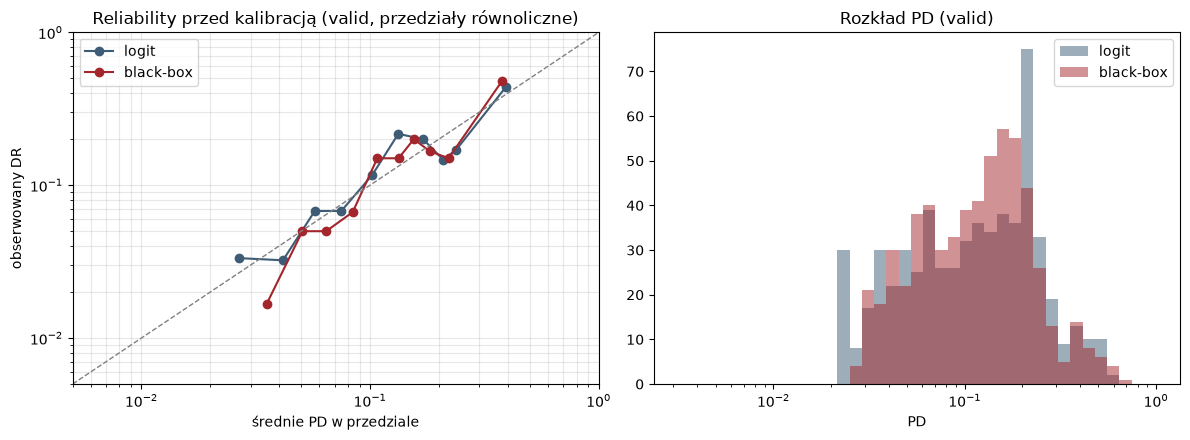

,DR,średnie PD,AUC,Brier,log-loss,ECE,ACE,CITL a,slope b,rzetelność (REL),rozdzielczość (RES),niepewność (UNC)
logit,0.1483,0.1438,0.7187,0.1148,0.3774,0.0302,0.0337,0.0400,0.9450,0.0019,0.0133,0.1263
black-box,0.1483,0.1412,0.7350,0.1118,0.3690,0.0347,0.0345,0.0631,1.1646,0.0021,0.0159,0.1263


In [48]:
from sklearn.calibration import calibration_curve

def reliability(ax, y, p, label, n_bins=10, **kw):           # z Lab 3
    obs, pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
    ax.plot(pred, obs, "o-", label=label, **kw)

def os_log(ax, lo=5e-3, hi=1.0):                              # z Lab 3
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")

def murphy(y, p, n_bins=10):                                  # z Lab 2 - dekompozycja Briera
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    o = y.mean(); rel = res = 0.0
    for m in range(len(edges) - 1):
        msk = idx == m
        if msk.any():
            w = msk.mean(); rel += w * (p[msk].mean() - y[msk].mean()) ** 2; res += w * (y[msk].mean() - o) ** 2
    return {"rzetelność (REL)": rel, "rozdzielczość (RES)": res, "niepewność (UNC)": o * (1 - o)}

KOL_KAL = ["DR", "średnie PD", "AUC", "Brier", "log-loss", "ECE", "ACE", "CITL a", "slope b"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["logit", "black-box"]:
    reliability(axes[0], y_va, P[m]["valid"], m, color=KOL[m])
    axes[1].hist(P[m]["valid"], bins=np.logspace(-2.5, 0, 40), alpha=0.5, label=m, color=KOL[m])
os_log(axes[0]); axes[0].set_title("Reliability przed kalibracją (valid, przedziały równoliczne)"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD (valid)"); axes[1].legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_przed.png", dpi=120); plt.show()
display(pd.concat([pd.DataFrame({m: metryki(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T[KOL_KAL],
                   pd.DataFrame({m: murphy(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T], axis=1).round(4))

**Wnioski:** przed kalibracją oba modele są dobrze skalibrowane do częstości w próbie: średnie PD 14,1-14,4% przy DR 14,8%,
CITL a ≈ 0,04-0,06, ECE ≈ 0,03 (ok. 1/5 DR). Nachylenie black-boxa na valid wynosi 1,16 - PD jest lekko zbyt „ostrożne” (za mało
skrajne). Oba modele uczono bez wag klas i bez oversamplingu, więc nie trzeba korekty a priori.

### 11.2 Kształt: Platt, izotoniczna, beta - wybór walidacją krzyżową wewnątrz valid

Kalibrator uczymy na valid, więc nie możemy go na valid oceniać. Jak w Lab 3: **5-krotna CV wewnątrz valid** -
kalibrator uczy się na 4/5 valid, ocena na 1/5. Na valid jest 89 defaultów - izotoniczna (dziesiątki schodków) jest
narażona na przeuczenie (Lab 2, sekcja 6), Platt i beta mają 2-3 parametry.

In [49]:
from sklearn.isotonic import IsotonicRegression

def _beta_cechy(p):                                           # z Lab 3
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])

FIT = {                                                       # z Lab 3 (4.2)
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
    "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y),
}

def zastosuj(metoda, kal, p):                                 # z Lab 3
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta":
        return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)

def cv_miara(metoda, y, p, k=5, miara="log-loss"):            # z Lab 3 (cv_logloss), dodany Brier
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RNG_SEED); w = []
    for a, b in skf.split(p.reshape(-1, 1), y):
        q = np.clip(zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b]), EPS, 1 - EPS)
        w.append(log_loss(y[b], q) if miara == "log-loss" else brier_score_loss(y[b], q))
    return float(np.mean(w))

wybor_kal = pd.concat({miara: pd.DataFrame({m: {met: cv_miara(met, y_va, P[m]["valid"], miara=miara) for met in FIT}
                                            for m in ["logit", "black-box"]}).T for miara in ["log-loss", "Brier"]}, axis=1)
display(wybor_kal.round(5))

PROSTOTA = ["bez kalibracji", "Platt", "beta", "izotoniczna"]
METODA = {}
for m in ["logit", "black-box"]:
    ll = wybor_kal["log-loss"].loc[m]
    METODA[m] = next(met for met in PROSTOTA if ll[met] <= ll.min() + 0.001)       # najprostsza w granicy 0,001 od najlepszej
print("Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001):", METODA)

log-loss                                        Brier  \
          bez kalibracji    Platt izotoniczna     beta bez kalibracji   
logit            0.37740  0.38123     0.40531  0.38177        0.11477   
black-box        0.36898  0.37089     0.40940  0.37143        0.11178   

                                         
             Platt izotoniczna     beta  
logit      0.11590     0.11783  0.11621  
black-box  0.11214     0.11337  0.11222

Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001): {'logit': 'bez kalibracji', 'black-box': 'bez kalibracji'}


**Wnioski:** w CV wewnątrz valid najniższy log-loss ma wariant **bez kalibracji kształtu**, Platt i beta są o 0,002-0,004 gorsze,
izotoniczna wyraźnie gorsza (log-loss 0,405-0,409) - przy 89 defaultach jej schodki są przeuczone (Lab 2, sekcja 6). Kształt PD jest
więc poprawny i wystarczy korekta poziomu. Wybór jest zgodny z zasadą z Lab 3: przy różnicach w trzecim miejscu po przecinku
wybieramy rozwiązanie najprostsze.

### 11.3 Walidacja po kalibracji statystycznej (test)

DR  średnie PD     AUC   Brier  log-loss  \
logit     bez kalibracji  0.1486      0.1435  0.7298  0.1148    0.3774   
          Platt           0.1486      0.1479  0.7298  0.1148    0.3771   
          izotoniczna     0.1486      0.1482  0.7094  0.1169    0.3992   
          beta            0.1486      0.1480  0.7298  0.1148    0.3771   
black-box bez kalibracji  0.1486      0.1412  0.7431  0.1135    0.3723   
          Platt           0.1486      0.1486  0.7431  0.1134    0.3722   
          izotoniczna     0.1486      0.1489  0.7351  0.1147    0.3778   
          beta            0.1486      0.1485  0.7431  0.1134    0.3720   

                             ECE     ACE  CITL a  slope b  
logit     bez kalibracji  0.0171  0.0250  0.0459   0.9252  
          Platt           0.0180  0.0262  0.0061   0.9789  
          izotoniczna     0.0230  0.0150  0.0034   0.6295  
          beta            0.0152  0.0257  0.0049   0.9773  
black-box bez kalibracji  0.0145  0.0241  0.0661   1.0743  
          Platt           0.0145  0.0256  0.0000   0.9223  
          izotoniczna     0.0226  0.0314 -0.0029   0.7549  
          beta            0.0114  0.0256  0.0003   0.9231

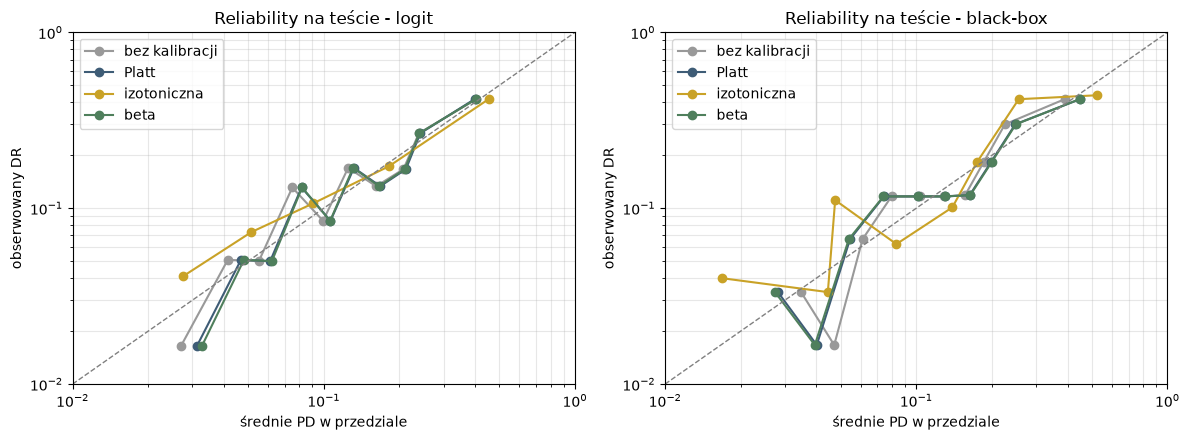

In [50]:
KAL = {m: FIT[METODA[m]](y_va, P[m]["valid"]) for m in P}
PS = {m: {s: zastosuj(METODA[m], KAL[m], P[m][s]) for s in X} for m in P}                     # po kalibracji kształtu
wiersze = {}
for m in P:
    for met in ["bez kalibracji", "Platt", "izotoniczna", "beta"]:
        kal = FIT[met](y_va, P[m]["valid"])
        wiersze[(m, met)] = metryki(y_te, zastosuj(met, kal, P[m]["test"]))
tab_kal_test = pd.DataFrame(wiersze).T[KOL_KAL]
display(tab_kal_test.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, m in zip(axes, P):
    for met, kol in [("bez kalibracji", "#999999"), ("Platt", KOL["logit"]), ("izotoniczna", KOL["valid"]), ("beta", "#4F7F5C")]:
        reliability(ax, y_te, zastosuj(met, FIT[met](y_va, P[m]["valid"]), P[m]["test"]), met, color=kol)
    os_log(ax, lo=1e-2); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_metody.png", dpi=120); plt.show()

**Wnioski (test):** Platt i beta sprowadzają CITL do zera i nachylenie do ok. 0,92-0,98, ale log-loss i Brier poprawiają się dopiero
w czwartym miejscu po przecinku. Izotoniczna pogarsza log-loss i AUC (remisy w schodkach) - potwierdza decyzję z 11.2.

### 11.4 Dostosowanie do tendencji centralnej PD = 4% (calibration-in-the-large)

$$\text{logit}(q) = \text{logit}(p) + \delta$$

δ wyznaczamy na **populacji referencyjnej = valid** tak, by średnie PD na valid wyniosło 4%, i to samo δ stosujemy na teście
(Lab 3, 4.3). 4% traktujemy jako zewnętrzne założenie biznesowe o docelowym portfelu (długookresowa średnia DR).
DR w naszych danych to ok. 14,8%, więc δ < 0 - PD po korekcie będzie **niższe od DR w próbie** z założenia.

In [51]:
def delta_do_sredniej(p, cel, lo=-15.0, hi=15.0, iters=100):   # z Lab 3
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if expit(z + mid).mean() < cel else (lo, mid)
    return (lo + hi) / 2

DELTA = {m: delta_do_sredniej(PS[m]["valid"], TARGET_PD) for m in P}
P4 = {m: {s: expit(_z(PS[m][s]) + DELTA[m]) for s in X} for m in P}                       # po kalibracji do 4%

def pd_koncowe(Xw, m="black-box"):
    # pełny łańcuch: model -> kalibracja kształtu -> przesunięcie do 4%
    p = black_box.predict_proba(Xw)[:, 1] if m == "black-box" else baseline.predict_proba(Xw[CECHY_L])[:, 1]
    return expit(_z(zastosuj(METODA[m], KAL[m], p)) + DELTA[m])

for m in P:
    print(f"{m:9s}: kształt = {METODA[m]}, δ = {DELTA[m]:+.3f} | średnie PD na valid: {P[m]['valid'].mean():.2%} (model) -> "
          f"{PS[m]['valid'].mean():.2%} (kształt) -> {P4[m]['valid'].mean():.2%} (po δ) | DR valid {y_va.mean():.2%}")
wiersze = {}
for m in P:
    wiersze[(m, "1. model")] = metryki(y_te, P[m]["test"])
    wiersze[(m, f"2. kształt: {METODA[m]}")] = metryki(y_te, PS[m]["test"])
    wiersze[(m, "3. kształt + 4%")] = metryki(y_te, P4[m]["test"])
tab_4 = pd.DataFrame(wiersze).T[KOL_KAL + ["Gini"]]
display(tab_4.round(4))

logit    : kształt = bez kalibracji, δ = -1.494 | średnie PD na valid: 14.38% (model) -> 14.38% (kształt) -> 4.00% (po δ) | DR valid 14.83%
black-box: kształt = bez kalibracji, δ = -1.463 | średnie PD na valid: 14.12% (model) -> 14.12% (kształt) -> 4.00% (po δ) | DR valid 14.83%


DR  średnie PD     AUC   Brier  \
logit     1. model                    0.1486      0.1435  0.7298  0.1148   
          2. kształt: bez kalibracji  0.1486      0.1435  0.7298  0.1148   
          3. kształt + 4%             0.1486      0.0402  0.7298  0.1314   
black-box 1. model                    0.1486      0.1412  0.7431  0.1135   
          2. kształt: bez kalibracji  0.1486      0.1412  0.7431  0.1135   
          3. kształt + 4%             0.1486      0.0401  0.7431  0.1313   

                                      log-loss     ECE     ACE  CITL a  \
logit     1. model                      0.3774  0.0171  0.0250  0.0459   
          2. kształt: bez kalibracji    0.3774  0.0171  0.0250  0.0459   
          3. kształt + 4%               0.4758  0.1084  0.1084  1.5399   
black-box 1. model                      0.3723  0.0145  0.0241  0.0661   
          2. kształt: bez kalibracji    0.3723  0.0145  0.0241  0.0661   
          3. kształt + 4%               0.4701  0.1084  0.1084  1.5295   

                                      slope b    Gini  
logit     1. model                     0.9252  0.4597  
          2. kształt: bez kalibracji   0.9252  0.4597  
          3. kształt + 4%              0.9246  0.4597  
black-box 1. model                     1.0743  0.4863  
          2. kształt: bez kalibracji   1.0743  0.4863  
          3. kształt + 4%              1.0741  0.4863

**Wnioski:**
- δ ≈ -1,49 (karta) i -1,46 (black-box): średnie PD spada z ok. 14% do 4,0% na valid i na teście.
- **AUC i Gini się nie zmieniają** (przesunięcie jest monotoniczne) - ranking ryzyka i kolejność firm są te same.
- Na teście (DR 14,9%) kalibracja statystyczna się **pogarsza**: CITL a ≈ 1,53, Brier 0,113 → 0,131, log-loss 0,37 → 0,47.
  To skutek założenia, nie błąd modelu: 4% to tendencja centralna docelowego portfela, a nasza próba ma DR 3,7 razy wyższy.
- Nachylenie się nie zmienia - δ przesuwa poziom, nie kształt (krzywe reliability przesuwają się równolegle w lewo).

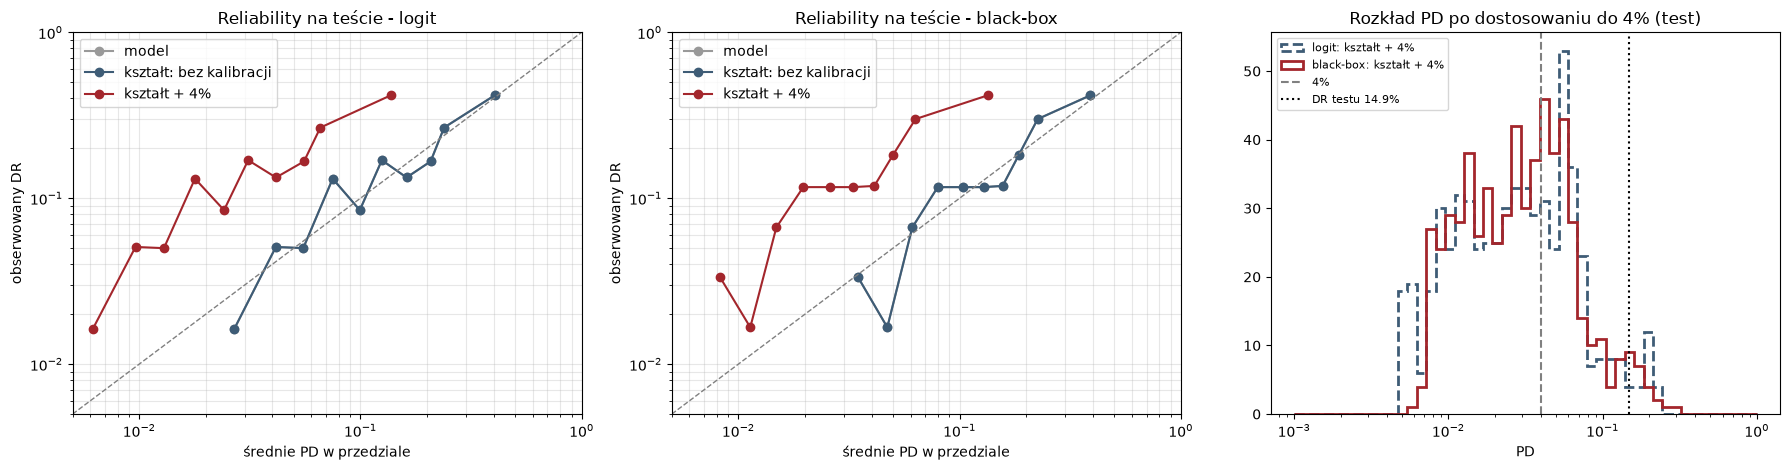

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, m in zip(axes[:2], P):
    for p, lab, col in [(P[m]["test"], "model", "#999999"), (PS[m]["test"], f"kształt: {METODA[m]}", KOL["logit"]), (P4[m]["test"], "kształt + 4%", KOL["test"])]:
        reliability(ax, y_te, p, lab, color=col)
    os_log(ax, lo=5e-3); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
for m, ls in [("logit", "--"), ("black-box", "-")]:
    axes[2].hist(P4[m]["test"], bins=np.logspace(-3, 0, 50), histtype="step", lw=2, ls=ls, label=f"{m}: kształt + 4%", color=KOL[m])
axes[2].axvline(TARGET_PD, ls="--", color="gray", label="4%"); axes[2].axvline(y_te.mean(), ls=":", color="black", label=f"DR testu {y_te.mean():.1%}")
axes[2].set_xscale("log"); axes[2].set_xlabel("PD"); axes[2].set_title("Rozkład PD po dostosowaniu do 4% (test)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wykresy/kalibracja_4proc.png", dpi=120); plt.show()

### 11.5 Czy PD = 4% jest skalibrowane dla docelowego portfela?

Przesunięcie logitu o δ to dokładnie **korekta a priori** (Lab 2): zmiana częstości klas z π = 14,8% na 4% przy tej samej
zależności cech od statusu firmy. Jeśli docelowy portfel różni się od próby tylko udziałem defaultów, PD po δ powinno być
skalibrowane na teście **przeważonym do DR = 4%** (wagi: default 0,04 / DR testu, brak defaultu 0,96 / (1 - DR testu)).

In [53]:
w_te = np.where(y_te == 1, TARGET_PD / y_te.mean(), (1 - TARGET_PD) / (1 - y_te.mean()))
def miary_wazone(y, p, w):
    z = _z(p)
    a = brentq(lambda d: np.average(expit(z + d), weights=w) - np.average(y, weights=w), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y, sample_weight=w).coef_[0, 0]
    return {"DR (ważony)": np.average(y, weights=w), "średnie PD (ważone)": np.average(p, weights=w),
            "Brier (ważony)": np.average((p - y) ** 2, weights=w), "log-loss (ważony)": log_loss(y, np.clip(p, EPS, 1 - EPS), sample_weight=w),
            "CITL a": a, "slope b": b}
display(pd.DataFrame({(m, wariant): miary_wazone(y_te, p, w_te) for m in P
                      for wariant, p in [("kształt (bez δ)", PS[m]["test"]), ("kształt + 4%", P4[m]["test"])]}).T.round(4))

DR (ważony)  średnie PD (ważone)  Brier (ważony)  \
logit     kształt (bez δ)         0.04               0.1329          0.0507   
          kształt + 4%            0.04               0.0365          0.0372   
black-box kształt (bez δ)         0.04               0.1307          0.0488   
          kształt + 4%            0.04               0.0365          0.0371   

                           log-loss (ważony)  CITL a  slope b  
logit     kształt (bez δ)             0.2085 -1.3960   0.9182  
          kształt + 4%                0.1548  0.0980   0.9200  
black-box kształt (bez δ)             0.2046 -1.3653   1.0376  
          kształt + 4%                0.1532  0.0981   1.0392

**Wnioski:** na teście przeważonym do DR = 4% PD po δ jest dobrze skalibrowane (CITL a ≈ 0,10, nachylenie 0,92-1,04, Brier 0,037),
a PD bez δ jest tam zawyżone 3,6 raza (CITL ≈ -1,4). Dostosowanie do 4% jest więc poprawne **pod warunkiem**, że docelowy portfel
różni się od próby tylko udziałem defaultów, a zależność wskaźników finansowych od statusu firmy jest taka sama. Jeśli próba jest
nadreprezentowana w defaultach przez dobór (np. celowe dobranie upadłych firm), to założenie jest rozsądne; jeśli wysoki DR wynika
ze złego okresu - PD po δ będzie zaniżone w podobnych okresach (filozofia TTC, nie PIT).

## 12. Progi decyzyjne i mapowanie PD → rating

### 12.1 Skala główna i rozkład firm

Skala z Lab 3: 7 klas dla firm bez defaultu (AAA ... CCC), granice rosnące geometrycznie, klasa **D** zarezerwowana dla
stwierdzonego defaultu (nie przypisujemy jej w dniu oceny). PD po dostosowaniu do 4%.

In [54]:
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]       # z Lab 3
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]

def rating(p):
    return pd.Categorical(pd.cut(np.asarray(p), bins=RATING_BINS, labels=RATING_LABELS, right=False), categories=RATING_LABELS, ordered=True)

skala = pd.DataFrame({"klasa": RATING_LABELS,
                      "przedział PD": [f"{100 * RATING_BINS[k]:.0f}% - {100 * RATING_BINS[k + 1]:.0f}%" if k < 6 else "≥ 20%" for k in range(7)]}).set_index("klasa")
R = {m: {s: rating(P4[m][s]) for s in X} for m in P}
for m in P:
    udz = pd.Series(R[m]["test"]).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
    skala[f"udział - {m} (test)"] = (100 * udz).round(1)
    skala[f"HHI {m}"] = round(float((udz ** 2).sum()), 3)
display(skala)

,przedział PD,udział - logit (test),HHI logit,udział - black-box (test),HHI black-box
klasa,,,,,
AAA,0% - 1%,16.5,0.225,11.0,0.251
AA,1% - 2%,21.9,0.225,25.4,0.251
A,2% - 5%,32.9,0.225,38.2,0.251
BBB,5% - 8%,19.7,0.225,15.9,0.251
BB,8% - 12%,3.7,0.225,4.2,0.251
B,12% - 20%,3.7,0.225,4.2,0.251
CCC,≥ 20%,1.7,0.225,1.2,0.251


**Wnioski:** po kalibracji do 4% najwięcej firm trafia do klas A i AA (ok. 55-64%), do klas BB-CCC tylko 9-10%. Koncentracja
(HHI 0,23-0,25) jest wyższa od równomiernej (0,14), ale żadna klasa nie przekracza 40% portfela. Black-box rozkłada firmy
podobnie, z nieco większą koncentracją w klasie A.

### 12.2 Backtest per klasa: monotoniczność, test Jeffreysa, światła (test)


logit: DR rośnie monotonicznie między klasami: True | światła po δ: {'czerwone': 5, 'żółte': 2} | przed δ: {'zielone': 7}


,n,defaulty,oczekiwane,średnie PD,DR,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,
AAA,99,3,0.7200,0.0073,0.0303,0.0153,żółte,0.0316,zielone
AA,131,10,1.8663,0.0142,0.0763,0.0000,czerwone,0.0604,zielone
A,197,26,6.3716,0.0323,0.1320,0.0000,czerwone,0.1288,zielone
BBB,118,29,7.3658,0.0624,0.2458,0.0000,czerwone,0.2283,zielone
BB,22,7,2.2024,0.1001,0.3182,0.0020,czerwone,0.3306,zielone
B,22,9,3.4508,0.1569,0.4091,0.0020,czerwone,0.4506,zielone
CCC,10,5,2.0881,0.2088,0.5000,0.0184,żółte,0.5401,zielone



black-box: DR rośnie monotonicznie między klasami: False | światła po δ: {'czerwone': 6, 'zielone': 1} | przed δ: {'zielone': 7}


,n,defaulty,oczekiwane,średnie PD,DR,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,
AAA,66,3,0.5553,0.0084,0.0455,0.0068,czerwone,0.0354,zielone
AA,152,10,2.2132,0.0146,0.0658,0.0000,czerwone,0.0599,zielone
A,229,27,7.7766,0.0340,0.1179,0.0000,czerwone,0.1311,zielone
BBB,95,24,5.7115,0.0601,0.2526,0.0000,czerwone,0.2161,zielone
BB,25,9,2.3632,0.0945,0.3600,0.0001,czerwone,0.3102,zielone
B,25,13,3.7771,0.1511,0.5200,0.0000,czerwone,0.4330,zielone
CCC,7,3,1.6476,0.2354,0.4286,0.1175,zielone,0.5685,zielone


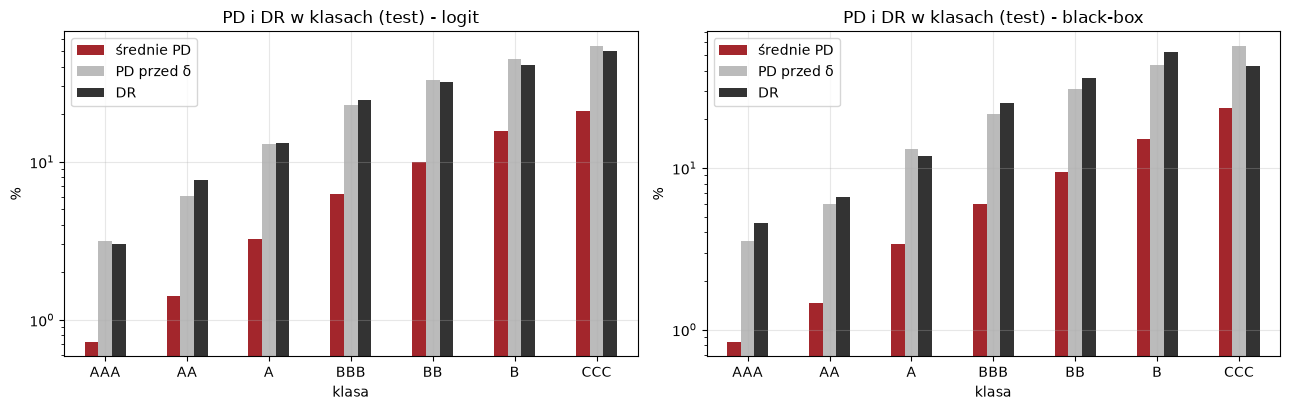

In [55]:
def swiatlo(p):                                               # z Lab 3
    return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")

def backtest(y, p, r, p_kszt=None):                           # z Lab 3
    rows = []
    for lab in RATING_LABELS:
        msk = np.asarray(r == lab)
        if not msk.any():
            continue
        n_k, d_k, pd_k = int(msk.sum()), int(y[msk].sum()), float(p[msk].mean())
        pj = float(beta_dist.cdf(pd_k, d_k + 0.5, n_k - d_k + 0.5))
        w = {"klasa": lab, "n": n_k, "defaulty": d_k, "oczekiwane": n_k * pd_k, "średnie PD": pd_k, "DR": d_k / n_k,
             "p Jeffreysa": pj, "światło": swiatlo(pj)}
        if p_kszt is not None:
            pk = float(p_kszt[msk].mean())
            w.update({"PD przed δ": pk, "światło przed δ": swiatlo(float(beta_dist.cdf(pk, d_k + 0.5, n_k - d_k + 0.5)))})
        rows.append(w)
    return pd.DataFrame(rows).set_index("klasa")

BT = {}
for m in P:
    BT[m] = backtest(y_te, P4[m]["test"], R[m]["test"], PS[m]["test"])
    print(f"\n{m}: DR rośnie monotonicznie między klasami: {bool(np.all(np.diff(BT[m]['DR'].to_numpy()) >= 0))} | "
          f"światła po δ: {BT[m]['światło'].value_counts().to_dict()} | przed δ: {BT[m]['światło przed δ'].value_counts().to_dict()}")
    display(BT[m].round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    (100 * BT[m][["średnie PD", "PD przed δ", "DR"]]).plot.bar(ax=ax, rot=0, color=[KOL["test"], "#BBBBBB", "#333333"])
    ax.set_yscale("log"); ax.set_ylabel("%"); ax.set_title(f"PD i DR w klasach (test) - {m}"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/backtest.png", dpi=120); plt.show()

**Wnioski:**
- DR rośnie monotonicznie między klasami karty (3% w AAA do 50% w CCC). W black-boxie jest jedno odwrócenie: CCC (3 z 7 firm)
  ma niższy DR niż B (13 z 25) - przy 7 firmach to przypadek, nie błąd skali.
- Po δ prawie wszystkie klasy mają czerwone światło, przed δ - wszystkie zielone. Zgodnie z interpretacją z Lab 3: model dobrze
  szereguje i kalibruje się w próbie, a różnicę tworzy **wyłącznie kotwica 4%** wobec DR testu 14,9%. W raporcie walidacyjnym
  komentujemy to jako zamierzony skutek PD through-the-cycle, a nie sygnał do rekalibracji.

### 12.3 Funkcja zysku i próg operacyjny

Brak kolumny z ekspozycją, więc przyjmujemy **jednakową ekspozycję EAD = 1** dla każdej firmy (wyniki - na jednostkę
ekspozycji). Ekonomia z Lab 3: przyjęty dobry klient daje zysk MARGIN = 10%, przyjęty zły - stratę LGD = 45%, odrzucenie - 0.

| | default | brak defaultu |
|---|---|---|
| **przyjęty** | FN: strata −LGD | TN: zysk +MARGIN |
| **odrzucony** | TP: 0 (uniknięta strata) | FP: 0 (utracony zysk MARGIN) |

Próg teoretyczny dla skalibrowanego PD: p* = MARGIN / (MARGIN + LGD) = 18,2%. Próg empiryczny szukamy na **valid**.

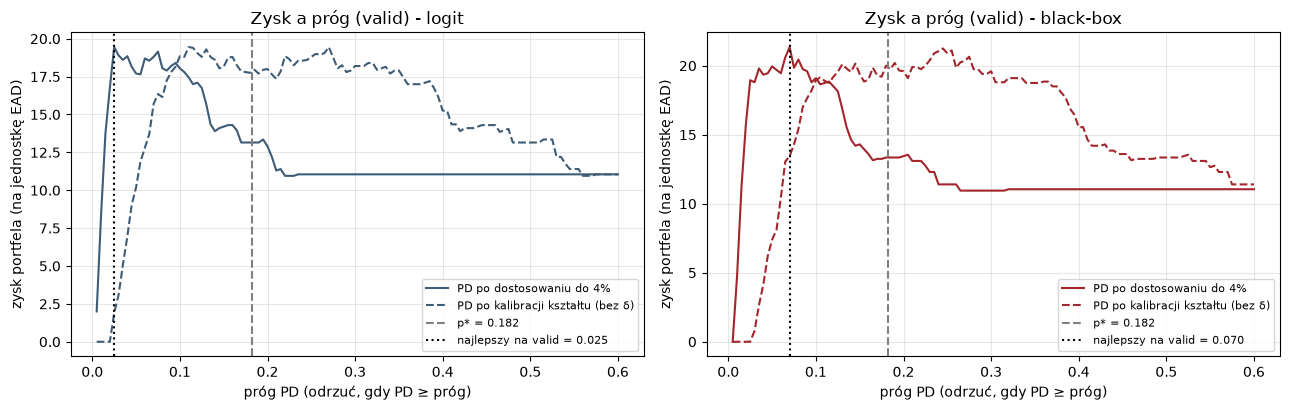

próg  stopa akceptacji  \
model     wariant                                                   
logit     próg z valid (PD 4%)            0.025             0.466   
          próg teoretyczny p* (PD 4%)     0.182             0.973   
          próg teoretyczny p* (PD bez δ)  0.182             0.691   
          przyjmij wszystkich             1.010             1.000   
black-box próg z valid (PD 4%)            0.070             0.885   
          próg teoretyczny p* (PD 4%)     0.182             0.985   
          próg teoretyczny p* (PD bez δ)  0.182             0.740   
          przyjmij wszystkich             1.010             1.000   

                                          DR wśród przyjętych  \
model     wariant                                               
logit     próg z valid (PD 4%)                          0.068   
          próg teoretyczny p* (PD 4%)                   0.139   
          próg teoretyczny p* (PD bez δ)                0.089   
          przyjmij wszystkich                           0.149   
black-box próg z valid (PD 4%)                          0.111   
          próg teoretyczny p* (PD 4%)                   0.144   
          próg teoretyczny p* (PD bez δ)                0.086   
          przyjmij wszystkich                           0.149   

                                          TP (odrzucone złe)  \
model     wariant                                              
logit     próg z valid (PD 4%)                            70   
          próg teoretyczny p* (PD 4%)                      8   
          próg teoretyczny p* (PD bez δ)                  52   
          przyjmij wszystkich                              0   
black-box próg z valid (PD 4%)                            30   
          próg teoretyczny p* (PD 4%)                      4   
          próg teoretyczny p* (PD bez δ)                  51   
          przyjmij wszystkich                              0   

                                          FP (odrzucone dobre)  \
model     wariant                                                
logit     próg z valid (PD 4%)                             250   
          próg teoretyczny p* (PD 4%)                        8   
          próg teoretyczny p* (PD bez δ)                   133   
          przyjmij wszystkich                                0   
black-box próg z valid (PD 4%)                              39   
          próg teoretyczny p* (PD 4%)                        5   
          próg teoretyczny p* (PD bez δ)                   105   
          przyjmij wszystkich                                0   

                                          FN (przyjęte złe)  \
model     wariant                                             
logit     próg z valid (PD 4%)                           19   
          próg teoretyczny p* (PD 4%)                    81   
          próg teoretyczny p* (PD bez δ)                 37   
          przyjmij wszystkich                            89   
black-box próg z valid (PD 4%)                           59   
          próg teoretyczny p* (PD 4%)                    85   
          próg teoretyczny p* (PD bez δ)                 38   
          przyjmij wszystkich                            89   

                                          TN (przyjęte dobre)  \
model     wariant                                               
logit     próg z valid (PD 4%)                            260   
          próg teoretyczny p* (PD 4%)                     502   
          próg teoretyczny p* (PD bez δ)                  377   
          przyjmij wszystkich                             510   
black-box próg z valid (PD 4%)                            471   
          próg teoretyczny p* (PD 4%)                     505   
          próg teoretyczny p* (PD bez δ)                  405   
          przyjmij wszystkich                             510   

                                          EL przyjętych (oczekiwana)  \
model     wariant                            

Odpowiednik progów w klasach ratingu: {'logit': 'odrzucamy od PD ≥ 2.5%', 'black-box': 'odrzucamy od PD ≥ 7.0%'}


In [56]:
def ekonomia(y, p, prog, margin=MARGIN, lgd=LGD):              # z Lab 3 (5.4), EAD = 1
    przyj = p < prog
    tp, fp = int(np.sum(~przyj & (y == 1))), int(np.sum(~przyj & (y == 0)))
    fn, tn = int(np.sum(przyj & (y == 1))), int(np.sum(przyj & (y == 0)))
    return {"próg": prog, "stopa akceptacji": przyj.mean(), "DR wśród przyjętych": y[przyj].mean() if przyj.any() else np.nan,
            "TP (odrzucone złe)": tp, "FP (odrzucone dobre)": fp, "FN (przyjęte złe)": fn, "TN (przyjęte dobre)": tn,
            "EL przyjętych (oczekiwana)": float(np.sum(p[przyj] * lgd)), "strata zrealizowana": lgd * fn,
            "zysk": margin * tn - lgd * fn}

progi = np.linspace(0.005, 0.6, 120)
PROG = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    for p_s, lab, ls in [(P4[m]["valid"], "PD po dostosowaniu do 4%", "-"), (PS[m]["valid"], "PD po kalibracji kształtu (bez δ)", "--")]:
        z = np.array([ekonomia(y_va, p_s, t)["zysk"] for t in progi])
        ax.plot(progi, z, ls, color=KOL[m], label=lab)
        if ls == "-":
            PROG[m] = float(progi[int(np.argmax(z))])
    ax.axvline(p_star, ls="--", color="gray", label=f"p* = {p_star:.3f}"); ax.axvline(PROG[m], ls=":", color="black", label=f"najlepszy na valid = {PROG[m]:.3f}")
    ax.set_xlabel("próg PD (odrzuć, gdy PD ≥ próg)"); ax.set_ylabel("zysk portfela (na jednostkę EAD)"); ax.set_title(f"Zysk a próg (valid) - {m}"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/prog_zysk.png", dpi=120); plt.show()

tab_prog = pd.DataFrame([{"model": m, "wariant": w, **ekonomia(y_te, p, t)} for m in P for w, p, t in [
    ("próg z valid (PD 4%)", P4[m]["test"], PROG[m]), ("próg teoretyczny p* (PD 4%)", P4[m]["test"], p_star),
    ("próg teoretyczny p* (PD bez δ)", PS[m]["test"], p_star), ("przyjmij wszystkich", P4[m]["test"], 1.01)]]).set_index(["model", "wariant"])
display(tab_prog.round(3))
print("Odpowiednik progów w klasach ratingu:", {m: f"odrzucamy od PD ≥ {PROG[m]:.1%}" for m in P})

**Wnioski:**
- Próg teoretyczny p* = 18,2% stosowany do PD po δ przyjmuje 97-99% firm - prawie jak „przyjmij wszystkich”. PD po δ jest tu
  zaniżone względem ryzyka w próbie, a p* wymaga PD skalibrowanego do portfela, na którym podejmujemy decyzje.
- Próg empiryczny z valid (2,5% dla karty, 7,0% dla black-boxa) „kompensuje” zaniżenie i daje zysk 17,5 i 20,6 wobec 11,0 przy
  przyjęciu wszystkich (na 599 firm, na jednostkę ekspozycji).
- Ten sam p* zastosowany do PD bez δ daje akceptację 69-74% i DR wśród przyjętych 8,6-8,9% - spójnie z teorią.
- Krzywe zysku są płaskie wokół optimum, więc próg karty (2,5%) jest mało precyzyjny - zmiana progu o kilka pp prawie nie zmienia
  zysku, ale wyraźnie zmienia akceptację. Biznesowo rozsądniej ustalić próg według docelowej stopy akceptacji.

### 12.4 Tabela decyzyjna: wpływ progu na wyniki biznesowe (black-box, test)

In [57]:
tab_dec = pd.DataFrame([ekonomia(y_te, P4["black-box"]["test"], t) for t in [0.03, 0.05, 0.08, PROG["black-box"], 0.12, 0.20, 1.01]]).set_index("próg")
display(tab_dec.round(3))

,stopa akceptacji,DR wśród przyjętych,TP (odrzucone złe),FP (odrzucone dobre),FN (przyjęte złe),TN (przyjęte dobre),EL przyjętych (oczekiwana),strata zrealizowana,zysk
próg,,,,,,,,,
0.03,0.518,0.071,67,222,22,288,2.297,9.90,18.90
0.05,0.746,0.089,49,103,40,407,4.745,18.00,22.70
0.08,0.905,0.118,25,32,64,478,7.315,28.80,19.00
0.07,0.885,0.111,30,39,59,471,6.913,26.55,20.55
0.12,0.947,0.129,16,16,73,494,8.379,32.85,16.55
0.20,0.988,0.145,3,4,86,506,10.079,38.70,11.90
1.01,1.000,0.149,0,0,89,510,10.820,40.05,10.95


**Wnioski:** obniżanie progu z 20% do 3% zmniejsza stopę akceptacji z 99% do 52% i DR wśród przyjętych z 14,5% do 7,1%. Liczba
odrzuconych dobrych firm (FP) rośnie szybciej niż liczba unikniętych złych (TP) - przy marży 10% i LGD 45% jeden uniknięty default
„kosztuje” odrzucenie 4,5 dobrej firmy, i tu leży optimum.

### 12.5 Porównanie decyzji: karta a black-box (test)

In [58]:
dec = {m: np.where(P4[m]["test"] < PROG[m], "przyjęty", "odrzucony") for m in P}
display(pd.crosstab(pd.Series(dec["logit"], name="karta"), pd.Series(dec["black-box"], name="black-box"), margins=True))
krz = pd.crosstab(pd.Series(R["logit"]["test"], name="rating karty"), pd.Series(R["black-box"]["test"], name="rating black-boxa"))
display(krz)
kod_l, kod_b = np.asarray(R["logit"]["test"].codes), np.asarray(R["black-box"]["test"].codes)
niezg = dec["logit"] != dec["black-box"]
print(f"Zgodność decyzji: {np.mean(~niezg):.1%} | ten sam rating: {np.mean(kod_l == kod_b):.1%} | różnica ≤ 1 klasa: {np.mean(np.abs(kod_l - kod_b) <= 1):.1%}")
tylko_l, tylko_b = (dec["logit"] == "odrzucony") & (dec["black-box"] == "przyjęty"), (dec["logit"] == "przyjęty") & (dec["black-box"] == "odrzucony")
print(f"Firmy z różną decyzją: {niezg.sum()} | odrzucone tylko przez kartę: {tylko_l.sum()} (DR {y_te[tylko_l].mean() if tylko_l.any() else np.nan:.1%}), "
      f"tylko przez black-box: {tylko_b.sum()}")

black-box,odrzucony,przyjęty,All
karta,,,
odrzucony,69,251,320
przyjęty,0,279,279
All,69,530,599


rating black-boxa,AAA,AA,A,BBB,BB,B,CCC
rating karty,,,,,,,
AAA,56,40,3,0,0,0,0
AA,10,81,39,1,0,0,0
A,0,31,126,39,1,0,0
BBB,0,0,59,46,10,3,0
BB,0,0,1,4,6,11,0
B,0,0,1,5,6,5,5
CCC,0,0,0,0,2,6,2


Zgodność decyzji: 58.1% | ten sam rating: 53.8% | różnica ≤ 1 klasa: 97.2%
Firmy z różną decyzją: 251 | odrzucone tylko przez kartę: 251 (DR 15.9%), tylko przez black-box: 0


Progi z valid są różne (karta odrzuca dużo więcej firm), więc porównanie powyżej miesza dwie rzeczy: jakość rankingu i
wybór progu. Dlatego porównujemy też decyzje **przy tej samej stopie akceptacji** - każdy model odrzuca ten sam odsetek
najgorszych firm (stopa black-boxa i stopa karty z progów z valid).

In [59]:
wiersze = []
for stopa in [np.mean(P4["black-box"]["test"] < PROG["black-box"]), np.mean(P4["logit"]["test"] < PROG["logit"])]:
    d_ = {}
    for m in P:
        prog_m = np.quantile(P4[m]["test"], stopa)
        d_[m] = P4[m]["test"] < prog_m
        wiersze.append({"stopa akceptacji": round(stopa, 3), "model": m, **{k: v for k, v in ekonomia(y_te, P4[m]["test"], prog_m).items() if k != "próg"}})
    wiersze[-1]["zgodność decyzji"] = wiersze[-2]["zgodność decyzji"] = np.mean(d_["logit"] == d_["black-box"])
display(pd.DataFrame(wiersze).set_index(["stopa akceptacji", "model"]).round(3))

DR wśród przyjętych  TP (odrzucone złe)  \
stopa akceptacji model                                                
0.884808         logit                    0.115                  28   
                 black-box                0.111                  30   
0.465776         logit                    0.068                  70   
                 black-box                0.054                  74   

                            FP (odrzucone dobre)  FN (przyjęte złe)  \
stopa akceptacji model                                                
0.884808         logit                        41                 61   
                 black-box                    39                 59   
0.465776         logit                       250                 19   
                 black-box                   246                 15   

                            TN (przyjęte dobre)  EL przyjętych (oczekiwana)  \
stopa akceptacji model                                                        
0.884808         logit                      469                       6.832   
                 black-box                  471                       6.913   
0.465776         logit                      260                       1.658   
                 black-box                  264                       1.897   

                            strata zrealizowana   zysk  zgodność decyzji  
stopa akceptacji model                                                    
0.884808         logit                    27.45  19.45              0.94  
                 black-box                26.55  20.55              0.94  
0.465776         logit                     8.55  17.45              0.87  
                 black-box                 6.75  19.65              0.87

**Wnioski:** przy tej samej stopie akceptacji modele podejmują te same decyzje dla zdecydowanej większości firm, a różnice zysku są
niewielkie. Ratingi różnią się najwyżej o jedną klasę dla ok. 97% firm. Główna różnica w decyzjach z sekcji 12.5 wynika z progów,
a nie z jakości rankingu.

## 13. Analiza kontrfaktyczna

**Pytanie:** jakie możliwie najmniejsze zmiany sytuacji finansowej poprawiłyby rating firmy o jedną klasę (BB → BBB)?

**Zależności między cechami.** Black-box używa ponad 190 wskaźników, z których wiele to warianty tej samej miary (3.3).
Zmiana jednego wskaźnika przy stałych pozostałych tworzy firmę, która nie istnieje (np. inne zadłużenie ogólne, ale to samo
zadłużenie krótkoterminowe). Dlatego zmieniamy **dźwignie** - grupy cech skorelowanych |ρ| ≥ 0,7 z cechą karty (7.3).
Wszystkie cechy dźwigni przesuwamy o tę samą liczbę **percentyli rozkładu z train** w kierunku niższego ryzyka.
Cechy niezmienne (sekcja PKD, forma własności, wielkość, wiek firmy) zostają bez zmian. Koszt zmiany = suma przesunięć w percentylach.

In [60]:
from scipy.stats import rankdata
R_TR = {c: np.sort(X_tr[c].dropna().to_numpy()) for c in num_cols}

def przesun(x, c, delta_pct, kier):
    # przesunięcie wartości cechy c o delta_pct percentyli w kierunku kier (+1 w górę, -1 w dół) rozkładu z train
    if pd.isna(x):
        return x
    r = np.searchsorted(R_TR[c], x, side="right") / len(R_TR[c])
    return float(np.quantile(R_TR[c], np.clip(r + kier * delta_pct, 0, 1)))

KIER_RYZYKA = {c: OCZEKIWANY[c] for c in CECHY_L}            # +1: wyższa wartość = wyższe ryzyko
DZWIGNIE = {}
for c in CECHY_L:
    czl = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7]
    DZWIGNIE[c] = {f: -KIER_RYZYKA[c] * int(np.sign(kor_tr.loc[c, f])) for f in czl}    # kierunek zmiany obniżający ryzyko
display(pd.DataFrame({"liczba cech w dźwigni": {c: len(v) for c, v in DZWIGNIE.items()},
                      "kierunek zmiany cechy wiodącej": {c: "w górę" if v[c] > 0 else "w dół" for c, v in DZWIGNIE.items()}}))

def jako_df(x):
    return x.to_frame().T.astype(X_te.dtypes.to_dict())

def zastosuj_dzwignie(x, zmiany):
    x = x.copy()
    for d, delta in zmiany.items():
        for f, kier in DZWIGNIE[d].items():
            x[f] = przesun(x[f], f, delta, kier)
    return x

kandydaci_bb = np.where(np.asarray(R["black-box"]["test"]) == "BB")[0]
i_cf = int(kandydaci_bb[np.argmin(np.abs(P4["black-box"]["test"][kandydaci_bb] - 0.10))])            # BB, PD w środku klasy
x_cf = X_te.iloc[i_cf]
print(f"Firma: wiersz testu {i_cf}, PD po 4% = {P4['black-box']['test'][i_cf]:.2%}, rating {R['black-box']['test'][i_cf]}, "
      f"karta: PD = {P4['logit']['test'][i_cf]:.2%}, rating {R['logit']['test'][i_cf]}, default = {y_te[i_cf]}")
display(x_cf[CECHY_L].to_frame("wartość").T)

,liczba cech w dźwigni,kierunek zmiany cechy wiodącej
podatek_dochodowy,2,w górę
Kapital_wlasny,8,w górę
wsk_ogolnego_zadluzenia_1,18,w dół
wsk_zysk_zobowiazania,31,w górę
wsk_stopa_zysku_sprzedaz,2,w górę
wsk_sytuacji_fin,1,w górę
pozostale_przychody_oper,4,w górę


Firma: wiersz testu 53, PD po 4% = 9.94%, rating BB, karta: PD = 8.94%, rating BB, default = 1


,podatek_dochodowy,Kapital_wlasny,wsk_ogolnego_zadluzenia_1,wsk_zysk_zobowiazania,wsk_stopa_zysku_sprzedaz,wsk_sytuacji_fin,pozostale_przychody_oper
wartość,13462.0,7229.69,0.997172,-0.000852,-0.191648,0.000646,102179.74


In [61]:
KROKI = np.round(np.arange(0.05, 0.81, 0.05), 2)
wyniki_cf = []
for d in DZWIGNIE:                                            # pojedyncze dźwignie
    for delta in KROKI:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d: delta}).pipe(jako_df))[0]
        wyniki_cf.append({"dźwignie": d, "przesunięcie (percentyle)": f"{delta:.2f}", "koszt": delta, "PD": p, "rating": rating([p])[0]})
for d1, d2 in itertools.combinations(DZWIGNIE, 2):           # pary dźwigni, równe przesunięcia
    for delta in KROKI[:8]:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d1: delta, d2: delta}).pipe(jako_df))[0]
        wyniki_cf.append({"dźwignie": f"{d1} + {d2}", "przesunięcie (percentyle)": f"{delta:.2f} + {delta:.2f}", "koszt": 2 * delta, "PD": p, "rating": rating([p])[0]})
cf = pd.DataFrame(wyniki_cf)
cel = cf[cf["rating"].astype(str).isin(["BBB", "A", "AA", "AAA"])]
najtansze = cel.sort_values("koszt").groupby("dźwignie").head(1).sort_values("koszt").head(8)
display(najtansze.round(4))

,dźwignie,przesunięcie (percentyle),koszt,PD,rating
33,wsk_ogolnego_zadluzenia_1,0.10,0.1,0.0650,BBB
121,podatek_dochodowy + wsk_ogolnego_zadluzenia_1,0.10 + 0.10,0.2,0.0663,BBB
161,Kapital_wlasny + wsk_ogolnego_zadluzenia_1,0.10 + 0.10,0.2,0.0639,BBB
217,wsk_ogolnego_zadluzenia_1 + wsk_sytuacji_fin,0.10 + 0.10,0.2,0.0650,BBB
209,wsk_ogolnego_zadluzenia_1 + wsk_stopa_zysku_sp...,0.10 + 0.10,0.2,0.0634,BBB
201,wsk_ogolnego_zadluzenia_1 + wsk_zysk_zobowiazania,0.10 + 0.10,0.2,0.0645,BBB
225,wsk_ogolnego_zadluzenia_1 + pozostale_przychod...,0.10 + 0.10,0.2,0.0682,BBB
179,Kapital_wlasny + wsk_stopa_zysku_sprzedaz,0.20 + 0.20,0.4,0.0782,BBB


**Wnioski:** najtańsza zmiana to dźwignia **zadłużenia**: przesunięcie o 10 percentyli rozkładu poprawia rating z BB na BBB
(PD 9,9% → 6,5%). Pozostałe pojedyncze dźwignie nie wystarczają w badanym zakresie, a pary działają tylko w połączeniu z zadłużeniem.

### 13.1 Wiarygodność kontrfaktu i porównanie z SHAP / LIME

Realność sprawdzamy odległością do najbliższej prawdziwej firmy z train (w przestrzeni rang percentylowych 20 najważniejszych
cech black-boxa), w porównaniu z typową odległością firm testowych do train.

In [62]:
from sklearn.neighbors import NearestNeighbors
TOP20 = [c for c in TOP_BB if c in num_cols][:20] + [c for c in waz_shap_bb.index if c in num_cols and c not in TOP_BB][:max(0, 20 - len([c for c in TOP_BB if c in num_cols]))]
def rangi_pct(Xw):
    return np.column_stack([np.searchsorted(R_TR[c], Xw[c].fillna(np.nanmedian(R_TR[c])).to_numpy(), side="right") / len(R_TR[c]) for c in TOP20])
nn = NearestNeighbors(n_neighbors=1).fit(rangi_pct(X_tr))
odl_typowe = nn.kneighbors(rangi_pct(X_te))[0].ravel()
najl_cf = najtansze.iloc[0]
zm = {d.strip(): float(v) for d, v in zip(najl_cf["dźwignie"].split("+"), najl_cf["przesunięcie (percentyle)"].split("+"))}
x_nowe = zastosuj_dzwignie(x_cf, zm)
odl_cf = nn.kneighbors(rangi_pct(x_nowe.pipe(jako_df)))[0][0, 0]
print(f"Najtańszy kontrfakt: {najl_cf['dźwignie']} o {najl_cf['przesunięcie (percentyle)']} percentyli -> PD {najl_cf['PD']:.2%}, rating {najl_cf['rating']}")
print(f"Odległość do najbliższej firmy z train: kontrfakt {odl_cf:.3f} | firmy testowe: mediana {np.median(odl_typowe):.3f}, 90. percentyl {np.percentile(odl_typowe, 90):.3f}")
display(pd.DataFrame({"przed": x_cf[[c for c in DZWIGNIE[list(zm)[0]]][:8]], "po": x_nowe[[c for c in DZWIGNIE[list(zm)[0]]][:8]]}).round(3))

s_shap = pd.Series(PHI_BB[i_cf], index=FEATURES)
e_cf = lime_wyjasnij(i_cf)
s_lime = pd.Series({FEATURES[j]: w for j, w in e_cf.local_exp[1]})
dz_shap = pd.Series({d: s_shap[list(DZWIGNIE[d])].sum() for d in DZWIGNIE})
dz_lime = pd.Series({d: s_lime.reindex(list(DZWIGNIE[d])).fillna(0).sum() for d in DZWIGNIE})
display(pd.DataFrame({"suma SHAP cech dźwigni": dz_shap, "suma wag LIME cech dźwigni": dz_lime,
                      "najtańszy kontrfakt z tą dźwignią (koszt)": cel.groupby("dźwignie")["koszt"].min().reindex(list(DZWIGNIE))}).round(3))

Najtańszy kontrfakt: wsk_ogolnego_zadluzenia_1 o 0.10 percentyli -> PD 6.50%, rating BBB
Odległość do najbliższej firmy z train: kontrfakt 0.723 | firmy testowe: mediana 0.397, 90. percentyl 0.594


,przed,po
Zobowiazania_rezerwy,2549063.73,1189241.012921
wsk_kapital_do_aktywa,0.002828,0.15085
wsk_mnoznik_kap_wl,353.582715,6.836635
wsk_udzial_kap_wlasnego_aktywa_1,0.002828,0.154073
wsk_udzial_kap_wlasnego_aktywa_2,0.003422,0.129234
wsk_ogolnego_zadluzenia_1,0.997172,0.840953
wsk_ogolnego_zadluzenia_2,0.997172,0.845915
wsk_zadluzenie_kap_wlasnego,352.582715,5.442338


,suma SHAP cech dźwigni,suma wag LIME cech dźwigni,najtańszy kontrfakt z tą dźwignią (koszt)
podatek_dochodowy,-0.295,-0.024,NaN
Kapital_wlasny,0.133,-0.009,NaN
wsk_ogolnego_zadluzenia_1,0.791,0.002,0.10
wsk_zysk_zobowiazania,0.003,0.000,0.45
wsk_stopa_zysku_sprzedaz,0.045,0.000,NaN
wsk_sytuacji_fin,0.020,0.000,NaN
pozostale_przychody_oper,-0.101,0.000,NaN


**Wnioski:**
- Firma ma kapitał własny ok. 0,3% aktywów i zadłużenie ogólne 99,7%. Przesunięcie o 10 percentyli oznacza w praktyce
  **dokapitalizowanie albo spłatę ok. 1,36 mln zł zobowiązań** (z 2,55 do 1,19 mln), tak by kapitał własny stanowił ok. 15% aktywów.
  Mała zmiana w percentylach to duża zmiana kwotowa, bo firma leży w skrajnym ogonie rozkładu.
- Kontrfakt jest dalej od prawdziwych firm niż typowa firma testowa (0,72 vs mediana 0,40) - zmieniamy zadłużenie, ale pozostałe
  wskaźniki (np. rentowność, płynność) zostają jak u firmy prawie bez kapitału. Rzeczywista firma po dokapitalizowaniu zmieniłaby też
  inne wskaźniki - **wynik należy traktować jako kierunek, nie gwarancję**.
- Zgodność z SHAP: dźwignia zadłużenia ma największą sumę SHAP (+0,79 log-szans) - to ona najbardziej podnosi ryzyko tej firmy.
  LIME przypisuje tym cechom prawie zerowe wagi - kolejny przykład niskiej wierności LIME (10.2).
- Ograniczenia: kontrfakt opisuje model, nie przyczynowość; nie uwzględnia kosztu i wykonalności zmiany ani reakcji innych pozycji
  sprawozdania; przy skorelowanych cechach zależy od definicji dźwigni.

### 13.2 Kontrfakt w karcie scoringowej

W karcie odpowiedź jest dokładna: rating zależy od sumy punktów, więc wystarczy policzyć, ile punktów brakuje do granicy
klasy BBB i które przejście do sąsiedniego przedziału daje najwięcej punktów.

In [63]:
pd_lim = RATING_BINS[RATING_LABELS.index("BB")]                 # granica BBB / BB
p_l = P4["logit"]["test"][i_cf]
z0 = baseline.decision_function(X_te.iloc[[i_cf]][CECHY_L])[0]
pd_z_modelu = lambda t: expit(_z(zastosuj(METODA["logit"], KAL["logit"], np.array([expit(z0 + t)]))) + DELTA["logit"])[0] - (pd_lim - 1e-4)
dz = brentq(pd_z_modelu, -10, 0) if p_l >= pd_lim else 0.0    # wymagana zmiana logitu karty (łańcuch kalibracji uwzględniony)
potrzebne_pkt = -factor * dz
wiersze = []
kody_cf = woe_l.codes(X_te.iloc[[i_cf]][CECHY_L]).iloc[0]
for c in CECHY_L:
    tab = woe_l.tables_[c]; k = int(kody_cf[c])
    for k2 in range(len(tab)):
        if k2 == k or tab["przedział"].iloc[k2] == "BRAK":
            continue
        d_pkt = factor * (-betas[c]) * (tab["WoE"].iloc[k2] - tab["WoE"].iloc[k])
        if d_pkt > 0:
            wiersze.append({"cecha": c, "z przedziału": tab["przedział"].iloc[k], "do przedziału": tab["przedział"].iloc[k2],
                            "skok przedziałów": abs(k2 - k), "zmiana punktów": d_pkt, "wystarczy sama": d_pkt >= potrzebne_pkt})
ruchy = pd.DataFrame(wiersze).sort_values(["skok przedziałów", "zmiana punktów"], ascending=[True, False])
print(f"Karta: PD po 4% = {p_l:.2%} ({R['logit']['test'][i_cf]}) | do ratingu BBB potrzeba PD < {pd_lim:.0%}, "
      f"czyli {potrzebne_pkt:.1f} pkt więcej (wynik {wynik_model[i_cf]:.0f} -> {wynik_model[i_cf] + potrzebne_pkt:.0f} pkt)")
display(ruchy.head(8).round(1))

Karta: PD po 4% = 8.94% (BB) | do ratingu BBB potrzeba PD < 8%, czyli 3.6 pkt więcej (wynik 511 -> 515 pkt)


,cecha,z przedziału,do przedziału,skok przedziałów,zmiana punktów,wystarczy sama
7,wsk_ogolnego_zadluzenia_1,[0.8535; inf),[0.7108; 0.8535),1,21.8,True
11,wsk_stopa_zysku_sprzedaz,[-0.4397; 0.006048),[0.006048; 0.03185),1,4.5,True
0,podatek_dochodowy,[2384; 2.152e+04),[2.152e+04; 8.535e+04),1,3.2,False
2,Kapital_wlasny,[-inf; 2e+04),[2e+04; 5.613e+04),1,2.2,False
13,wsk_sytuacji_fin,[-inf; 0.004826),[0.004826; 0.0264),1,1.7,False
8,wsk_zysk_zobowiazania,[-0.4605; 0),[0; 0.04593),1,1.0,False
6,wsk_ogolnego_zadluzenia_1,[0.8535; inf),[-inf; 0.7108),2,37.4,True
12,wsk_stopa_zysku_sprzedaz,[-0.4397; 0.006048),[0.03185; inf),2,9.9,True


**Wnioski:** w karcie wystarczy przejście zadłużenia ogólnego do sąsiedniego przedziału (z ≥ 0,85 do 0,71-0,85): +22 pkt przy
potrzebnych 3,6 pkt. Oba modele wskazują więc tę samą dźwignię, a karta podaje odpowiedź dokładną i łatwą do zakomunikowania klientowi.

## 14. Audyt podgrup, monitoring i podsumowanie

### 14.1 Szybki audyt podgrup (test)

Dane nie zawierają cech osób fizycznych (płeć, wiek), więc audyt dotyczy segmentów firm: wielkości jednostki, sekcji PKD
i formy własności. Przy kilkunastu defaultach w grupie różnice mogą być przypadkowe - AUC liczymy tylko przy ≥ 10 defaultach.

In [64]:
def audyt(kol, maks_grup=6):
    g_te = X_te[kol].where(X_te[kol].isin(X_te[kol].value_counts().index[:maks_grup]), "INNE")
    rows = []
    for g in g_te.unique():
        msk = (g_te == g).to_numpy()
        w = {"segment": f"{kol} = {g}", "n": int(msk.sum()), "defaulty": int(y_te[msk].sum()), "DR": y_te[msk].mean()}
        for m in P:
            w[f"śr. PD bez δ ({m})"] = PS[m]["test"][msk].mean()
            w[f"DR / PD bez δ ({m})"] = y_te[msk].mean() / PS[m]["test"][msk].mean()
            w[f"Brier ({m})"] = brier_score_loss(y_te[msk], PS[m]["test"][msk])
            w[f"AUC ({m})"] = roc_auc_score(y_te[msk], P[m]["test"][msk]) if y_te[msk].sum() >= 10 and (1 - y_te[msk]).sum() >= 10 else np.nan
        rows.append(w)
    return pd.DataFrame(rows).set_index("segment").sort_values("n", ascending=False)

tab_audyt = pd.concat([audyt(k) for k in ["wielkosc", "sekcja_pkd", "forma_wlasnosci"]])
display(tab_audyt.round(3))

,n,defaulty,DR,śr. PD bez δ (logit),DR / PD bez δ (logit),Brier (logit),AUC (logit),śr. PD bez δ (black-box),DR / PD bez δ (black-box),Brier (black-box),AUC (black-box)
segment,,,,,,,,,,,
wielkosc = pozostałe,325,52,0.160,0.130,1.231,0.125,0.746,0.133,1.206,0.122,0.743
wielkosc = mikro,174,23,0.132,0.177,0.745,0.099,0.777,0.168,0.787,0.099,0.796
wielkosc = mała,100,14,0.140,0.128,1.091,0.111,0.696,0.122,1.150,0.113,0.760
sekcja_pkd = INNE,149,23,0.154,0.147,1.047,0.116,0.778,0.145,1.063,0.118,0.775
sekcja_pkd = G,124,15,0.121,0.138,0.875,0.105,0.736,0.134,0.906,0.101,0.766
sekcja_pkd = M,94,12,0.128,0.166,0.767,0.088,0.852,0.165,0.773,0.088,0.856
sekcja_pkd = C,82,14,0.171,0.113,1.517,0.148,0.601,0.109,1.565,0.136,0.680
sekcja_pkd = F,50,9,0.180,0.158,1.141,0.133,NaN,0.153,1.178,0.145,NaN
sekcja_pkd = J,50,10,0.200,0.150,1.334,0.138,0.735,0.149,1.344,0.130,0.778


**Wnioski:**
- Wielkość: firmy mikro mają DR 13,2% przy PD 16,8-17,7% - oba modele **zawyżają** ich ryzyko (DR / PD ≈ 0,75-0,79), a dla
  pozostałych zaniżają (≈ 1,2). AUC w grupach jest podobne (0,74-0,80).
- Formy własności F215 i F216 mają DR 21-22% przy PD 12-16% (DR / PD 1,3-1,8) - kandydat do korekty segmentowej (Lab 3, Zadanie 5),
  ale przy 12-13 defaultach różnica może być przypadkowa.
- Sekcja C (przetwórstwo) ma DR / PD ≈ 1,5 i najniższe AUC (0,60-0,68). Pozostałe sekcje są w granicach losowości.
- Wniosek: brak systematycznej dyskryminacji jednego segmentu, ale korekta segmentowa dla wielkości firmy jest warta rozważenia
  na większej próbie.

### 14.2 Stabilność populacji (PSI) i plan monitoringu

PSI z Lab 3 (train jako populacja referencyjna). Przy podziale losowym PSI powinno być bliskie zera - to kontrola
poprawności podziału, a po wdrożeniu ta sama miara na nowych danych służy do monitoringu.

In [65]:
def psi(ref, cur, n_bins=10):                                 # z Lab 3
    ref, cur = pd.Series(ref), pd.Series(cur)
    if not pd.api.types.is_numeric_dtype(ref):
        kat = ref.astype(str).value_counts(normalize=True)
        e = kat.to_numpy(); a = cur.astype(str).value_counts(normalize=True).reindex(kat.index).fillna(0).to_numpy()
    else:
        ref, cur = ref.dropna(), cur.dropna()
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, n_bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
        e = np.histogram(ref, edges)[0] / len(ref); a = np.histogram(cur, edges)[0] / len(cur)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

wiersze = [{"zmienna": f"PD ({m})", "PSI valid": psi(P4[m]["train"], P4[m]["valid"]), "PSI test": psi(P4[m]["train"], P4[m]["test"])} for m in P]
for c in CECHY_L + [c for c in TOP_BB[:5] if c not in CECHY_L] + cat_cols:
    wiersze.append({"zmienna": c, "PSI valid": psi(X_tr[c], X_va[c]), "PSI test": psi(X_tr[c], X_te[c])})
tab_psi = pd.DataFrame(wiersze).set_index("zmienna")
tab_psi["ocena (test)"] = pd.cut(tab_psi["PSI test"], [-np.inf, 0.10, 0.25, np.inf], labels=["stabilnie", "obserwuj", "istotna zmiana"])
display(tab_psi.round(4))

,PSI valid,PSI test,ocena (test)
zmienna,,,
PD (logit),0.0086,0.0170,stabilnie
PD (black-box),0.0105,0.0078,stabilnie
podatek_dochodowy,0.0110,0.0187,stabilnie
Kapital_wlasny,0.0108,0.0078,stabilnie
wsk_ogolnego_zadluzenia_1,0.0161,0.0109,stabilnie
wsk_zysk_zobowiazania,0.0105,0.0212,stabilnie
wsk_stopa_zysku_sprzedaz,0.0242,0.0293,stabilnie
wsk_sytuacji_fin,0.0067,0.0191,stabilnie
pozostale_przychody_oper,0.0253,0.0284,stabilnie


**Wnioski:** PSI wyniku i cech jest < 0,05 - podział losowy daje zbiory o tej samej strukturze, zgodnie z oczekiwaniem.
Po wdrożeniu PSI liczone na nowych firmach będzie pierwszym sygnałem zmiany portfela (np. innego udziału firm mikro).

| Obszar | Miara | Częstotliwość | Próg alarmowy |
|---|---|---|---|
| populacja | PSI wyniku i CSI cech karty / top-10 SHAP | kwartalnie | > 0,10 obserwuj, > 0,25 przegląd modelu |
| dyskryminacja | Gini, KS na nowych defaultach | rocznie (po 12 mies.) | spadek Gini > 0,10 względem walidacji |
| kalibracja | średnie PD vs DR, Brier, ECE, test Jeffreysa per klasa | rocznie | czerwone światło w ≥ 2 klasach |
| wyjaśnienia | Jaccard top-5 SHAP względem walidacji, znaki β karty | kwartalnie | Jaccard < 0,5 albo zmiana znaku |
| decyzje | stopa akceptacji, DR wśród przyjętych | miesięcznie | odchylenie > 5 pp od planu |

### 14.3 Podsumowanie porównania modeli

In [66]:
podsum = pd.DataFrame({
    m: {"Gini test": 2 * roc_auc_score(y_te, P[m]["test"]) - 1, "AUC test 95% CI": bootstrap_ci(y_te, P[m]["test"])["AUC 95% CI"],
        "Gini CV (średnia ± odch.)": f"{(cv_logit if m == 'logit' else cv_bb)['Gini'].mean():.3f} ± {(cv_logit if m == 'logit' else cv_bb)['Gini'].std():.3f}",
        "KS test": ks(y_te, P[m]["test"]), "PR-AUC test": average_precision_score(y_te, P[m]["test"]),
        "log-loss test (po kształcie)": log_loss(y_te, PS[m]["test"]), "Brier test (po kształcie)": brier_score_loss(y_te, PS[m]["test"]),
        "metoda kalibracji kształtu": METODA[m], "δ do 4%": DELTA[m], "średnie PD test po 4%": P4[m]["test"].mean(),
        "liczba cech": len(CECHY_L) if m == "logit" else len(uzyte),
        "zysk na teście (próg z valid)": ekonomia(y_te, P4[m]["test"], PROG[m])["zysk"],
        "stabilność rankingu ważności (Jaccard top-k)": f"{zgodnosc_rankingow(rank_lg, 3)[0]:.2f} (top-3)" if m == "logit" else f"{zgodnosc_rankingow(rank_bb, 5)[0]:.2f} (top-5)",
        "wyjaśnienie lokalne": "dokładne (punkty karty)" if m == "logit" else "SHAP dokładny addytywnie; LIME - niska wierność"} for m in P}).T
display(podsum.round(3) if hasattr(podsum, "round") else podsum)
podsum.to_csv("wyniki/podsumowanie_modeli.csv")
pd.DataFrame({"logit": P4["logit"]["test"], "black-box": P4["black-box"]["test"], "y": y_te}).to_csv("wyniki/pd_test.csv", index=False)

,Gini test,AUC test 95% CI,Gini CV (średnia ± odch.),KS test,PR-AUC test,log-loss test (po kształcie),Brier test (po kształcie),metoda kalibracji kształtu,δ do 4%,średnie PD test po 4%,liczba cech,zysk na teście (próg z valid),stabilność rankingu ważności (Jaccard top-k),wyjaśnienie lokalne
logit,0.459683,[0.674; 0.785],0.425 ± 0.110,0.352743,0.331208,0.377407,0.114841,bez kalibracji,-1.493932,0.040175,7,17.45,0.52 (top-3),dokładne (punkty karty)
black-box,0.486252,[0.690; 0.800],0.442 ± 0.101,0.367151,0.341702,0.372317,0.113489,bez kalibracji,-1.463404,0.040141,164,20.55,0.33 (top-5),SHAP dokładny addytywnie; LIME - niska wierność


## 15. Wnioski końcowe

| Kryterium | Karta scoringowa (WoE + logit) | Black-box (XGBoost) |
|---|---|---|
| Dyskryminacja (test) | Gini 0,46, KS 0,35 | Gini 0,49, KS 0,37; różnica +0,03, 95% CI [-0,04; +0,09] |
| Stabilność w CV | Gini 0,43 ± 0,11 | Gini 0,44 ± 0,10 |
| Złożoność | 7 cech, 8 parametrów, 32 przedziały | 164 używane cechy, 300 drzew, ok. 2 900 liści |
| Interpretowalność | bezpośrednia: punkty, WoE, znaki β zgodne z ekonomią | pośrednia: SHAP, PDP / ALE, LIME |
| Wierność wyjaśnień lokalnych | dokładna (suma punktów = wynik) | SHAP dokładny addytywnie; LIME R² ≈ 0,22 |
| Stabilność wyjaśnień | Jaccard top-3 ≈ 0,52, znaki β stabilne | Jaccard top-5 ≈ 0,33 (wybór skorelowanych cech) |
| Kalibracja | bez korekty kształtu; δ = -1,49 do 4% | bez korekty kształtu; δ = -1,46 do 4% |
| Decyzje (test, próg z valid) | zysk 17,5 | zysk 20,6; przy równej akceptacji - podobne decyzje |

**Czy poprawa jakości black-boxa uzasadnia utratę bezpośredniej interpretowalności? - Nie w tym zastosowaniu.**
Przewaga black-boxa (+0,03 Gini) mieści się w niepewności statystycznej, oba modele opierają się na tych samych obszarach
finansowych, a wyjaśnienia black-boxa są mniej stabilne (ranking SHAP zmienia się z danymi) i - w przypadku LIME - mało wierne.
**Rekomendujemy kartę scoringową jako model ratingowy**, a XGBoost jako model kontrolny (*challenger*): do monitoringu
i do wskazywania firm, dla których modele się różnią (sekcja 9, przypadek 4) - takie firmy warto kierować do analityka.

**Najważniejsze założenia i ograniczenia:** wykluczenie wskaźników `wsk_index_*` (możliwy przeciek, kosztuje ok. 0,15-0,19 Gini),
podział grupowy oparty na heurystyce (brak identyfikatora firmy), jednakowa ekspozycja w ekonomii progu, kotwica 4% przy DR próby
14,8% (PD po δ jest skalibrowane tylko dla portfela różniącego się udziałem defaultów), mała liczba defaultów w zbiorach valid i test (89).